In [1]:
# Import all libraries required for the project.

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

PyTorch version: 2.11.0+cpu
Device: cpu


In [2]:
# Define the paths of the three datasets.

load_path = r"Load_Forecasting.csv"
solar_path = r"Solar_Forecasting.csv"
wind_path = r"Wind_Forecasting.csv"

In [3]:
# Load the three datasets into Pandas DataFrames.

load_df = pd.read_csv(load_path)
solar_df = pd.read_csv(solar_path)
wind_df = pd.read_csv(wind_path)

In [4]:
# Convert the datetime column to Pandas datetime format.

load_df["Datetime_UTC"] = pd.to_datetime(load_df["Datetime_UTC"])
solar_df["Datetime_UTC"] = pd.to_datetime(solar_df["Datetime_UTC"])
wind_df["Datetime_UTC"] = pd.to_datetime(wind_df["Datetime_UTC"])

In [5]:
# Sort all datasets by timestamp and reset the index.

load_df = load_df.sort_values("Datetime_UTC").reset_index(drop=True)
solar_df = solar_df.sort_values("Datetime_UTC").reset_index(drop=True)
wind_df = wind_df.sort_values("Datetime_UTC").reset_index(drop=True)

In [6]:
# Display the basic information of all three datasets.

print("LOAD DATASET")
print("=" * 50)
print("Shape:", load_df.shape)
print("Columns:", load_df.columns.tolist())
display(load_df.head())

print("\nSOLAR DATASET")
print("=" * 50)
print("Shape:", solar_df.shape)
print("Columns:", solar_df.columns.tolist())
display(solar_df.head())

print("\nWIND DATASET")
print("=" * 50)
print("Shape:", wind_df.shape)
print("Columns:", wind_df.columns.tolist())
display(wind_df.head())

LOAD DATASET
Shape: (26297, 12)
Columns: ['Datetime_UTC', 'Load_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'IsWeekend', 'IsHoliday']


,Datetime_UTC,Load_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month,IsWeekend,IsHoliday
0,2023-01-01 07:00:00+00:00,35829.306163,11.32,69.29,5.05,2.37,7,6,1,1,1,1
1,2023-01-01 08:00:00+00:00,35245.390234,10.36,75.44,4.62,10.12,8,6,1,1,1,1
2,2023-01-01 09:00:00+00:00,34599.761810,9.76,79.94,4.48,17.85,9,6,1,1,1,1
3,2023-01-01 10:00:00+00:00,34227.151061,9.22,83.95,4.39,57.65,10,6,1,1,1,1
4,2023-01-01 11:00:00+00:00,34093.414143,8.69,87.17,4.19,99.70,11,6,1,1,1,1



SOLAR DATASET
Shape: (26297, 14)
Columns: ['Datetime_UTC', 'Solar_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month']


,Datetime_UTC,Solar_MW,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,0.449746,11.32,69.29,5.05,2.37,0.0,0.0,0.0,NaN,7,6,1,1
1,2023-01-01 08:00:00+00:00,0.454733,10.36,75.44,4.62,10.12,0.0,0.0,0.0,NaN,8,6,1,1
2,2023-01-01 09:00:00+00:00,0.443528,9.76,79.94,4.48,17.85,0.0,0.0,0.0,NaN,9,6,1,1
3,2023-01-01 10:00:00+00:00,0.458567,9.22,83.95,4.39,57.65,0.0,0.0,0.0,NaN,10,6,1,1
4,2023-01-01 11:00:00+00:00,0.451126,8.69,87.17,4.19,99.70,0.0,0.0,0.0,NaN,11,6,1,1



WIND DATASET
Shape: (26297, 10)
Columns: ['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month']


,Datetime_UTC,Wind_MW,T2M,RH2M,WS10M,CLOUD_AMT,Hour,DayOfWeek,DayOfYear,Month
0,2023-01-01 07:00:00+00:00,21753.284477,11.32,69.29,5.05,2.37,7,6,1,1
1,2023-01-01 08:00:00+00:00,21570.395694,10.36,75.44,4.62,10.12,8,6,1,1
2,2023-01-01 09:00:00+00:00,21036.504013,9.76,79.94,4.48,17.85,9,6,1,1
3,2023-01-01 10:00:00+00:00,20595.481515,9.22,83.95,4.39,57.65,10,6,1,1
4,2023-01-01 11:00:00+00:00,20387.843555,8.69,87.17,4.19,99.70,11,6,1,1


In [7]:
# Check the time range covered by each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(f"{name}:")
    print("Start:", df["Datetime_UTC"].min())
    print("End  :", df["Datetime_UTC"].max())
    print()

Load:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00

Solar:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00

Wind:
Start: 2023-01-01 07:00:00+00:00
End  : 2025-12-31 23:00:00+00:00



In [8]:
# Check the number and percentage of missing values in each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(f"{name} missing values:")
    display(pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": df.isnull().mean() * 100
    }))
    print()

Load missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.0
Load_MW,0,0.0
T2M,0,0.0
RH2M,0,0.0
WS10M,0,0.0
CLOUD_AMT,0,0.0
Hour,0,0.0
DayOfWeek,0,0.0
DayOfYear,0,0.0
Month,0,0.0



Solar missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.000000
Solar_MW,0,0.000000
T2M,0,0.000000
RH2M,0,0.000000
WS10M,0,0.000000
CLOUD_AMT,0,0.000000
ALLSKY_SFC_SW_DWN,0,0.000000
ALLSKY_SFC_SW_DNI,0,0.000000
ALLSKY_SFC_SW_DIFF,0,0.000000
ALLSKY_KT,12505,47.552953



Wind missing values:


,Missing Count,Missing Percentage
Datetime_UTC,0,0.0
Wind_MW,0,0.0
T2M,0,0.0
RH2M,0,0.0
WS10M,0,0.0
CLOUD_AMT,0,0.0
Hour,0,0.0
DayOfWeek,0,0.0
DayOfYear,0,0.0
Month,0,0.0


In [9]:
# Check for duplicate rows and duplicate timestamps.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(name)
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate timestamps:", df["Datetime_UTC"].duplicated().sum())
    print()

Load
Duplicate rows: 0
Duplicate timestamps: 0

Solar
Duplicate rows: 0
Duplicate timestamps: 0

Wind
Duplicate rows: 0
Duplicate timestamps: 0



In [10]:
# Check whether the datasets contain continuous hourly timestamps.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    expected = pd.date_range(
        start=df["Datetime_UTC"].min(),
        end=df["Datetime_UTC"].max(),
        freq="h"
    )

    missing_timestamps = expected.difference(df["Datetime_UTC"])

    print(name)
    print("Expected timestamps:", len(expected))
    print("Actual timestamps  :", len(df))
    print("Missing timestamps :", len(missing_timestamps))
    print()

Load
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0

Solar
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0

Wind
Expected timestamps: 26297
Actual timestamps  : 26297
Missing timestamps : 0



In [11]:
# Create time-based features from the datetime column for EDA.

for df in [load_df, solar_df, wind_df]:
    df["Hour_Calc"] = df["Datetime_UTC"].dt.hour
    df["DayOfWeek_Calc"] = df["Datetime_UTC"].dt.dayofweek
    df["DayOfYear_Calc"] = df["Datetime_UTC"].dt.dayofyear
    df["Month_Calc"] = df["Datetime_UTC"].dt.month
    df["Year_Calc"] = df["Datetime_UTC"].dt.year

In [12]:
# Calculate the average target value for every hour of the day.

hourly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Hour_Calc")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Hour_Calc")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Hour_Calc")["Wind_MW"].mean()
})

display(hourly_pattern)

,Load_MW,Solar_MW,Wind_MW
Hour_Calc,,,
0,60003.199465,6173.533936,11741.277970
1,59113.524710,1886.701631,12489.867789
2,57997.122623,131.272923,13572.695826
3,56619.517314,2.481388,14789.710789
4,54373.121053,1.168896,15631.040170
5,51682.695205,0.642824,15982.580581
6,49195.140770,0.607701,15998.770323
7,47300.188044,0.504021,15702.275586
8,46015.289529,0.489495,15245.156893


In [13]:
# Convert UTC timestamps to Texas Central local time for all datasets.

load_df["Datetime_Local"] = load_df["Datetime_UTC"].dt.tz_convert("America/Chicago")
solar_df["Datetime_Local"] = solar_df["Datetime_UTC"].dt.tz_convert("America/Chicago")
wind_df["Datetime_Local"] = wind_df["Datetime_UTC"].dt.tz_convert("America/Chicago")

In [14]:
# Remove the previously created time features that were calculated from UTC time.

old_time_columns = [
    "Hour_Calc",
    "DayOfWeek_Calc",
    "DayOfYear_Calc",
    "Month_Calc",
    "Year_Calc"
]

for df in [load_df, solar_df, wind_df]:
    df.drop(
        columns=[col for col in old_time_columns if col in df.columns],
        inplace=True
    )

In [15]:
# Create the same calendar features from Texas local time for all datasets.

for df in [load_df, solar_df, wind_df]:
    df["Hour"] = df["Datetime_Local"].dt.hour
    df["DayOfWeek"] = df["Datetime_Local"].dt.dayofweek
    df["DayOfYear"] = df["Datetime_Local"].dt.dayofyear
    df["Month"] = df["Datetime_Local"].dt.month
    df["Year"] = df["Datetime_Local"].dt.year

In [16]:
# Create a readable day-of-week column for EDA.

day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

for df in [load_df, solar_df, wind_df]:
    df["DayName"] = df["DayOfWeek"].map(day_names)

In [17]:
# Compare UTC and Texas local timestamps for all datasets.

print("LOAD")
display(load_df[["Datetime_UTC", "Datetime_Local"]].head())

print("\nSOLAR")
display(solar_df[["Datetime_UTC", "Datetime_Local"]].head())

print("\nWIND")
display(wind_df[["Datetime_UTC", "Datetime_Local"]].head())

LOAD


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00



SOLAR


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00



WIND


,Datetime_UTC,Datetime_Local
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00


In [18]:
# Check the timezone offsets present in each dataset.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    offsets = df["Datetime_Local"].apply(
        lambda x: str(x.utcoffset())
    ).value_counts()

    print(f"\n{name}")
    display(offsets)


Load


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64


Solar


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64


Wind


Datetime_Local
-1 day, 19:00:00    17133
-1 day, 18:00:00     9164
Name: count, dtype: int64

In [19]:
# Display the local-time features for all three datasets.

columns = [
    "Datetime_UTC",
    "Datetime_Local",
    "Hour",
    "DayOfWeek",
    "DayName",
    "DayOfYear",
    "Month",
    "Year"
]

print("LOAD")
display(load_df[columns].head())

print("\nSOLAR")
display(solar_df[columns].head())

print("\nWIND")
display(wind_df[columns].head())

LOAD


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023



SOLAR


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023



WIND


,Datetime_UTC,Datetime_Local,Hour,DayOfWeek,DayName,DayOfYear,Month,Year
0,2023-01-01 07:00:00+00:00,2023-01-01 01:00:00-06:00,1,6,Sunday,1,1,2023
1,2023-01-01 08:00:00+00:00,2023-01-01 02:00:00-06:00,2,6,Sunday,1,1,2023
2,2023-01-01 09:00:00+00:00,2023-01-01 03:00:00-06:00,3,6,Sunday,1,1,2023
3,2023-01-01 10:00:00+00:00,2023-01-01 04:00:00-06:00,4,6,Sunday,1,1,2023
4,2023-01-01 11:00:00+00:00,2023-01-01 05:00:00-06:00,5,6,Sunday,1,1,2023


In [20]:
# Check the UTC and local time ranges for all datasets.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    print(name)
    print("UTC start   :", df["Datetime_UTC"].min())
    print("Local start :", df["Datetime_Local"].min())
    print("UTC end     :", df["Datetime_UTC"].max())
    print("Local end   :", df["Datetime_Local"].max())
    print()

Load
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00

Solar
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00

Wind
UTC start   : 2023-01-01 07:00:00+00:00
Local start : 2023-01-01 01:00:00-06:00
UTC end     : 2025-12-31 23:00:00+00:00
Local end   : 2025-12-31 17:00:00-06:00



In [21]:
# Verify that the original UTC timeline remains continuous after adding local time.

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    utc_differences = df["Datetime_UTC"].diff().dropna()

    print(name)
    print("Unique UTC intervals:")
    print(utc_differences.value_counts())
    print()

Load
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64

Solar
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64

Wind
Unique UTC intervals:
Datetime_UTC
0 days 01:00:00    26296
Name: count, dtype: int64



In [22]:
# Calculate average hourly behavior using the same Texas local-time definition for all datasets.

hourly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Hour")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Hour")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Hour")["Wind_MW"].mean()
})

display(hourly_pattern)

,Load_MW,Solar_MW,Wind_MW
Hour,,,
0,51075.981899,0.624815,16006.965176
1,48680.807020,0.598393,15955.389438
2,47039.960158,0.468558,15631.339853
3,45870.485544,0.492793,15157.181878
4,45210.314821,0.480216,14626.903485
5,45180.369909,0.659464,14094.680861
6,46125.446044,0.611187,13640.167925
7,47847.713970,20.935117,13202.398001
8,48955.418304,1291.238558,12620.304284


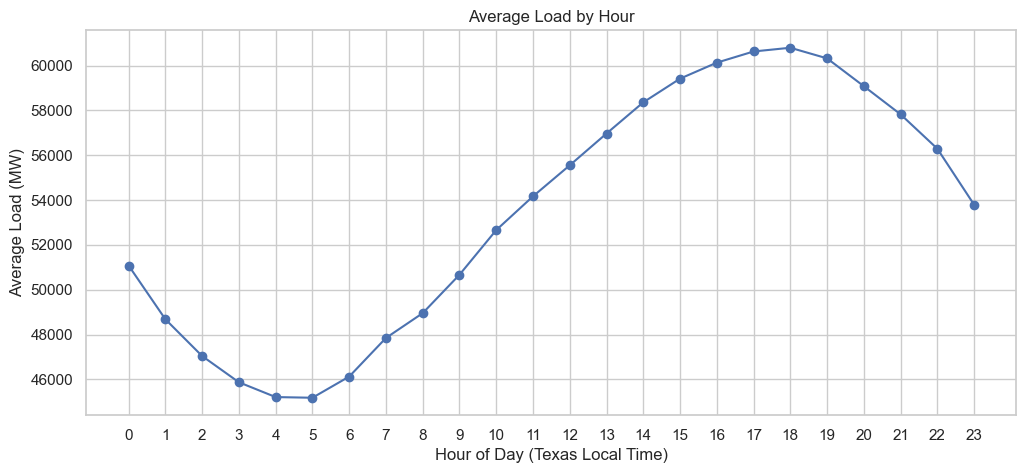

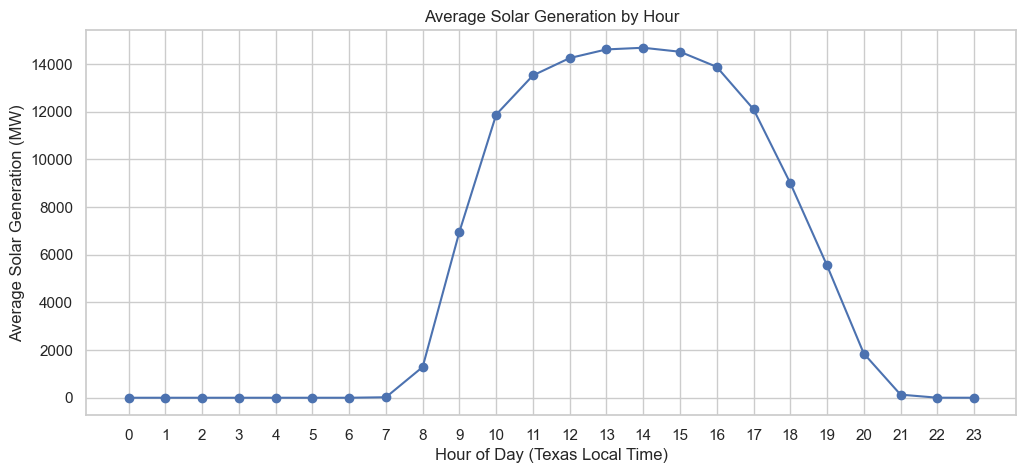

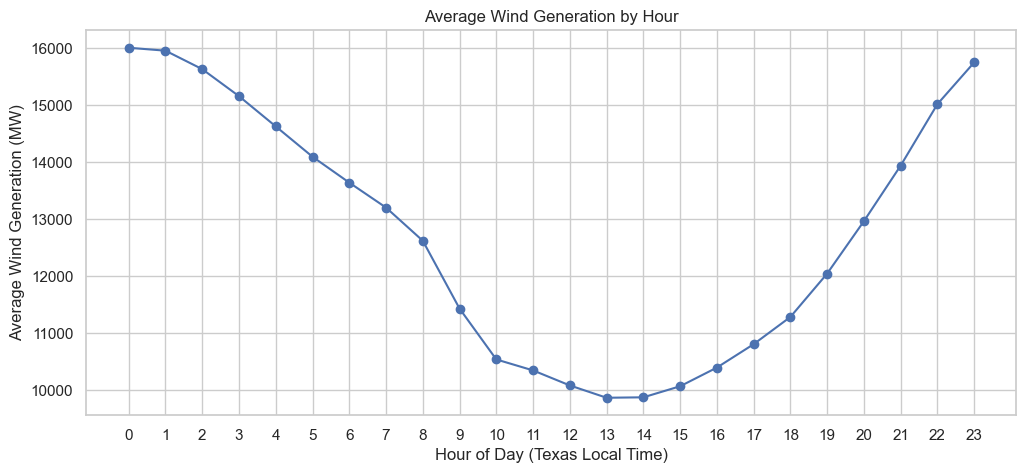

In [23]:
# Plot the average daily pattern of load, solar, and wind using Texas local time.

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Hour")
plt.xticks(range(24))

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Hour")
plt.xticks(range(24))

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Hour of Day (Texas Local Time)")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Hour")
plt.xticks(range(24))

plt.show()

In [24]:
# Calculate average generation/load for each day of the week.

weekday_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("DayOfWeek")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("DayOfWeek")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("DayOfWeek")["Wind_MW"].mean()
})

weekday_pattern.index = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

display(weekday_pattern)

,Load_MW,Solar_MW,Wind_MW
Monday,53980.155322,5650.169632,12418.394192
Tuesday,54129.842418,5664.726866,12672.682607
Wednesday,53981.356762,5551.232000,12629.239719
Thursday,53955.551062,5612.802764,12300.306427
Friday,53950.533833,5604.212408,13061.859699
Saturday,52348.440431,5506.639529,13134.118329
Sunday,51752.565217,5574.671956,12839.427665


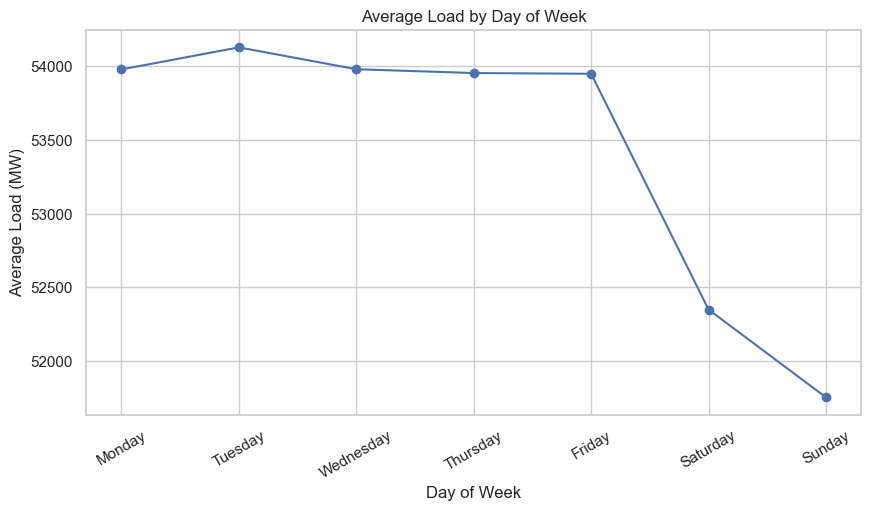

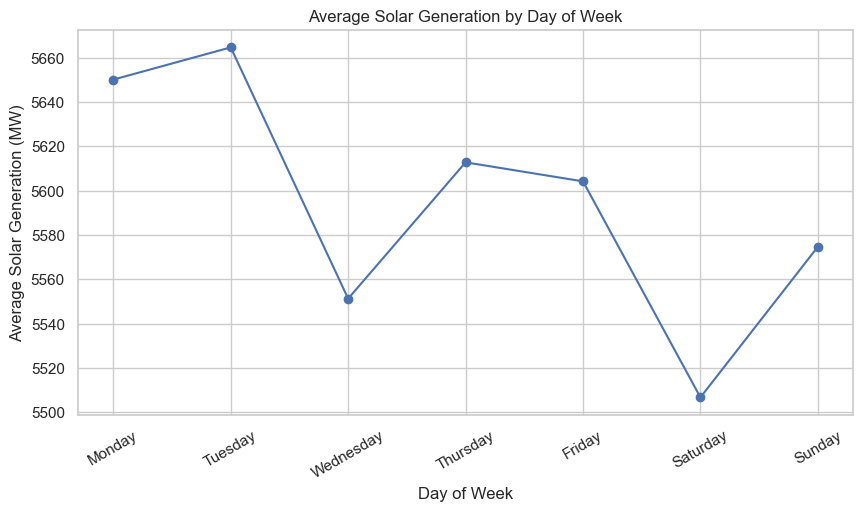

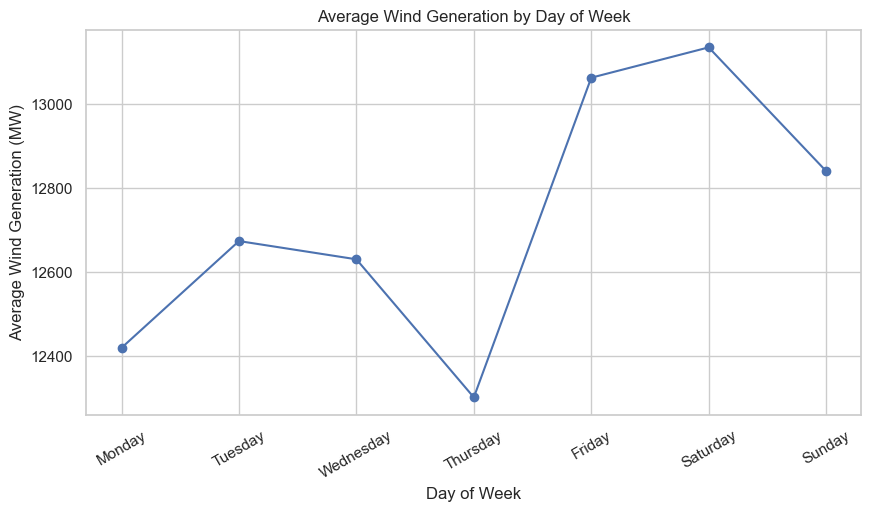

In [25]:
# Plot the average behavior for each day of the week.

plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Day of Week")
plt.xticks(rotation=30)

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Day of Week")
plt.xticks(rotation=30)

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    weekday_pattern.index,
    weekday_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Day of Week")
plt.xticks(rotation=30)

plt.show()

In [26]:
# Calculate the average target value for each month.

monthly_pattern = pd.DataFrame({
    "Load_MW": load_df.groupby("Month")["Load_MW"].mean(),
    "Solar_MW": solar_df.groupby("Month")["Solar_MW"].mean(),
    "Wind_MW": wind_df.groupby("Month")["Wind_MW"].mean()
})

monthly_pattern.index = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

display(monthly_pattern)

,Load_MW,Solar_MW,Wind_MW
January,49920.967831,3166.233494,13005.598296
February,47163.161757,3799.017529,14755.564035
March,44645.290467,4694.473203,14956.582931
April,47002.825772,5232.733234,15775.188513
May,53079.524052,6105.276482,12012.066912
June,61675.079784,7136.466868,13339.800254
July,63080.019867,7288.811653,11766.603941
August,67232.133494,7648.361727,10108.552591
September,59762.714831,6949.775362,9224.476525
October,52360.843580,6080.859089,12206.049992


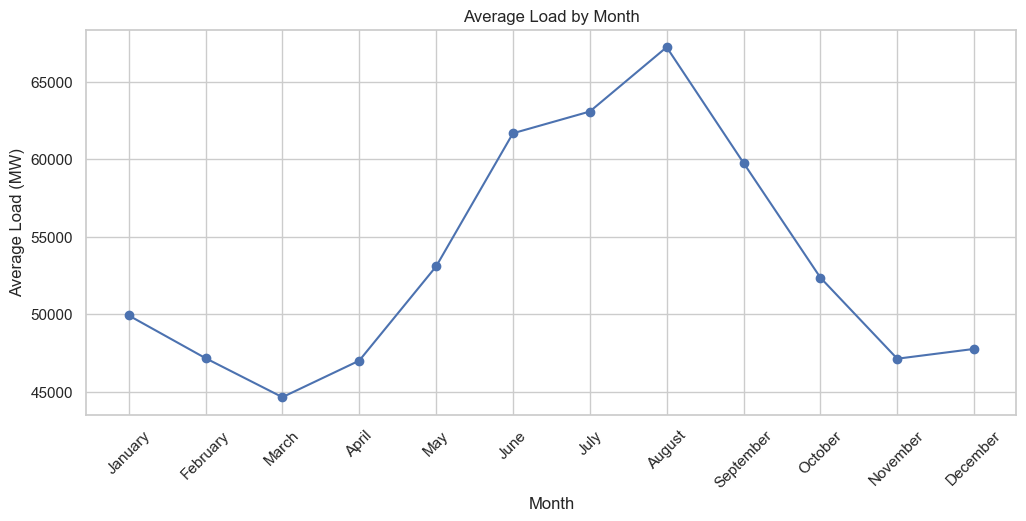

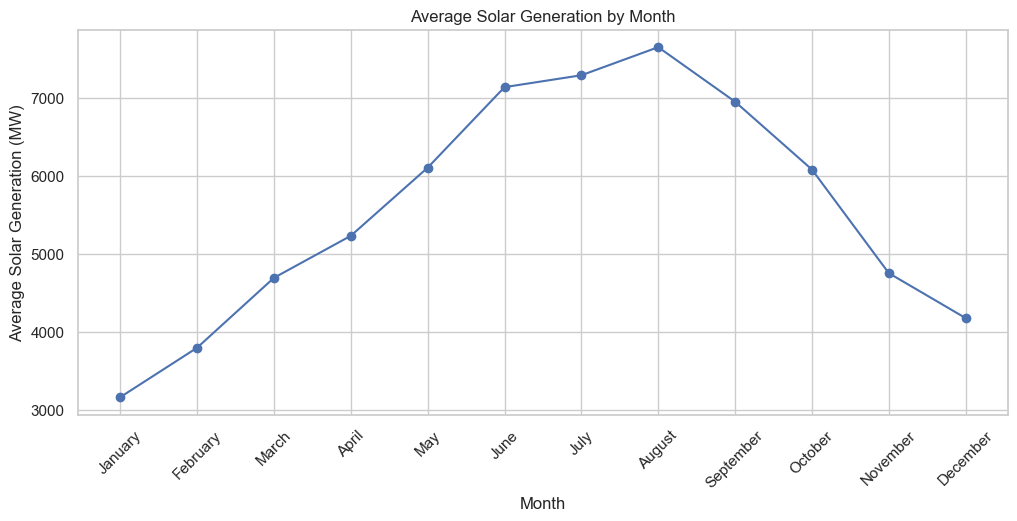

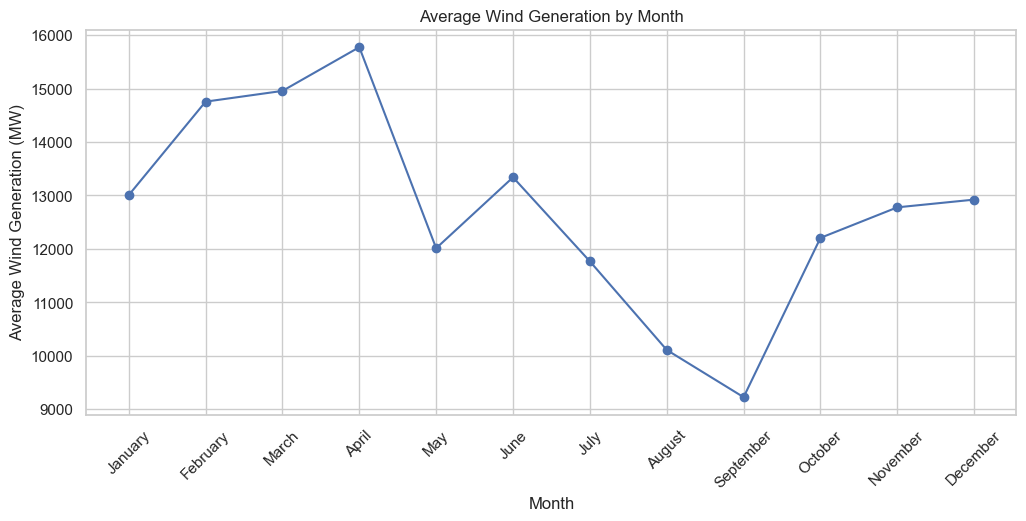

In [27]:
# Plot the average target value for each month.

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Load_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Load (MW)")
plt.title("Average Load by Month")
plt.xticks(rotation=45)

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Solar_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Solar Generation (MW)")
plt.title("Average Solar Generation by Month")
plt.xticks(rotation=45)

plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pattern.index,
    monthly_pattern["Wind_MW"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Wind Generation (MW)")
plt.title("Average Wind Generation by Month")
plt.xticks(rotation=45)

plt.show()

In [28]:
# Calculate monthly averages separately for each year.

load_monthly_yearly = load_df.pivot_table(
    index="Month",
    columns="Year",
    values="Load_MW",
    aggfunc="mean"
)

solar_monthly_yearly = solar_df.pivot_table(
    index="Month",
    columns="Year",
    values="Solar_MW",
    aggfunc="mean"
)

wind_monthly_yearly = wind_df.pivot_table(
    index="Month",
    columns="Year",
    values="Wind_MW",
    aggfunc="mean"
)

print("Load")
display(load_monthly_yearly)

print("\nSolar")
display(solar_monthly_yearly)

print("\nWind")
display(wind_monthly_yearly)

Load


Year,2023,2024,2025
Month,,,
1,43363.258621,51451.845166,54938.985581
2,45167.453521,44189.219820,52239.024141
3,42965.890170,43587.386536,47382.594696
4,42873.938291,46719.368715,51415.170311
5,49230.148181,54006.026679,56002.397295
6,59593.778336,62030.943853,63400.517161
7,64023.895128,60191.236296,65024.928179
8,67814.322540,66572.128420,67309.949523
9,59983.756764,57304.706094,61999.681635



Solar


Year,2023,2024,2025
Month,,,
1,2041.202826,2999.136661,4456.848857
2,2145.924407,3802.039533,5448.980719
3,2765.294248,4395.666261,6922.459101
4,3549.463467,4823.084387,7325.651846
5,4058.164895,5498.291718,8759.372833
6,4842.907994,6915.960153,9650.532455
7,5252.381992,6899.228163,9714.824804
8,5220.336391,7771.524844,9953.223947
9,4508.288440,6702.079506,9638.958139



Wind


Year,2023,2024,2025
Month,,,
1,14677.907350,11479.969501,12861.165765
2,15148.854008,15729.501784,13353.552823
3,14921.239958,13736.862469,16211.646366
4,14191.484616,16144.027488,16990.053434
5,9988.652771,13585.415874,12462.132092
6,11363.982284,13920.402957,14735.015520
7,12036.931344,10918.820142,12344.060336
8,10606.961377,10164.759593,9553.936803
9,10011.686263,8273.278393,9388.464918


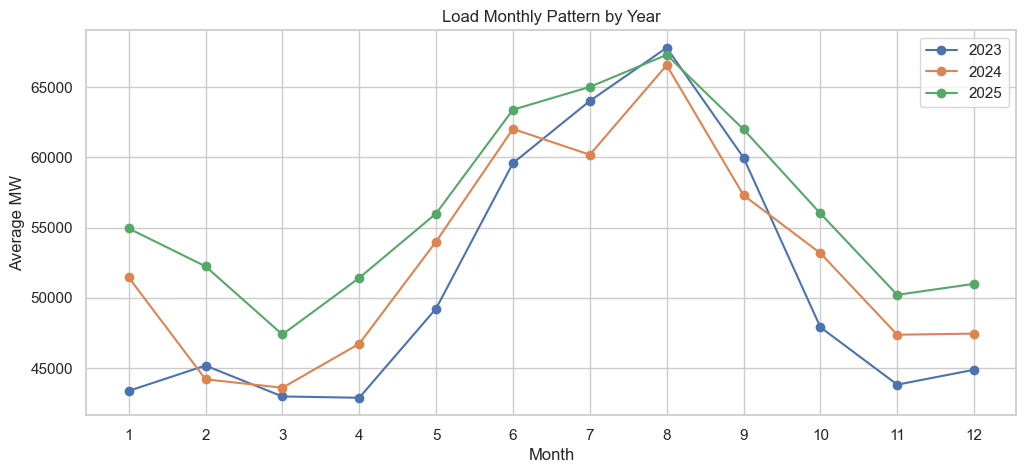

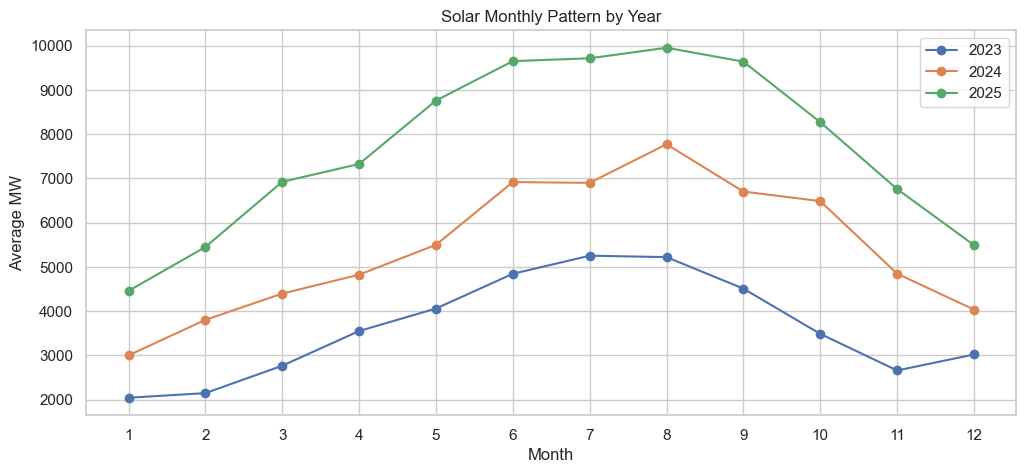

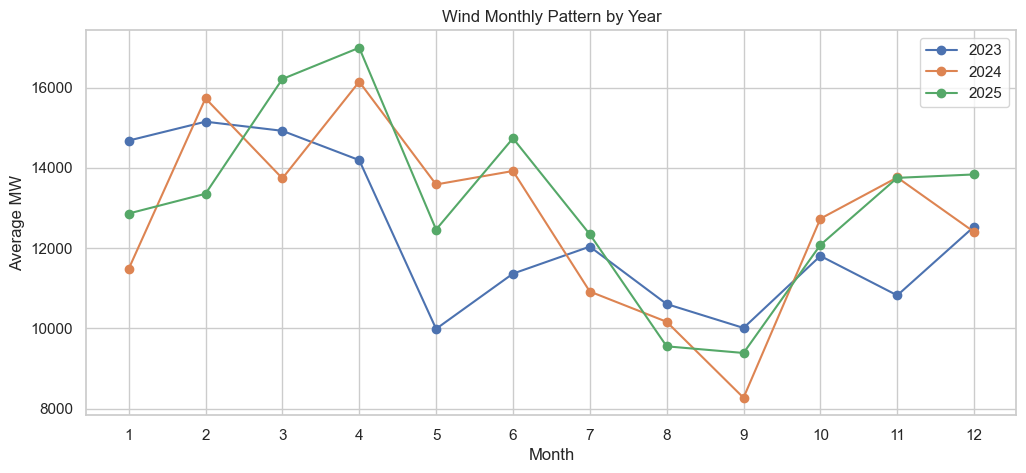

In [29]:
# Plot monthly patterns separately for each year.

figures = [
    ("Load", load_monthly_yearly),
    ("Solar", solar_monthly_yearly),
    ("Wind", wind_monthly_yearly)
]

for name, data in figures:

    plt.figure(figsize=(12, 5))

    for year in data.columns:
        plt.plot(
            data.index,
            data[year],
            marker="o",
            label=str(year)
        )

    plt.xlabel("Month")
    plt.ylabel("Average MW")
    plt.title(f"{name} Monthly Pattern by Year")
    plt.xticks(range(1, 13))
    plt.legend()

    plt.show()

In [30]:
# Calculate descriptive statistics for the three forecasting targets.

target_stats = pd.DataFrame({
    "Load_MW": load_df["Load_MW"].describe(),
    "Solar_MW": solar_df["Solar_MW"].describe(),
    "Wind_MW": wind_df["Wind_MW"].describe()
})

display(target_stats)

,Load_MW,Solar_MW,Wind_MW
count,26297.000000,26297.000000,26297.000000
mean,53442.643329,5594.988677,12722.005940
std,11035.943399,7433.929044,6697.712689
min,33681.540790,0.000010,37.929258
25%,45135.908281,0.407512,6984.308713
50%,50777.762847,336.094571,12330.326026
75%,59910.070037,10694.253827,18338.356289
max,85544.435964,29503.086634,28264.502331


In [31]:
# Calculate skewness and variation for each target.

additional_stats = pd.DataFrame({
    "Mean": [
        load_df["Load_MW"].mean(),
        solar_df["Solar_MW"].mean(),
        wind_df["Wind_MW"].mean()
    ],
    "Median": [
        load_df["Load_MW"].median(),
        solar_df["Solar_MW"].median(),
        wind_df["Wind_MW"].median()
    ],
    "Std": [
        load_df["Load_MW"].std(),
        solar_df["Solar_MW"].std(),
        wind_df["Wind_MW"].std()
    ],
    "Skewness": [
        load_df["Load_MW"].skew(),
        solar_df["Solar_MW"].skew(),
        wind_df["Wind_MW"].skew()
    ],
    "Min": [
        load_df["Load_MW"].min(),
        solar_df["Solar_MW"].min(),
        wind_df["Wind_MW"].min()
    ],
    "Max": [
        load_df["Load_MW"].max(),
        solar_df["Solar_MW"].max(),
        wind_df["Wind_MW"].max()
    ]
}, index=["Load", "Solar", "Wind"])

display(additional_stats)

,Mean,Median,Std,Skewness,Min,Max
Load,53442.643329,50777.762847,11035.943399,0.775698,33681.540790,85544.435964
Solar,5594.988677,336.094571,7433.929044,1.132663,0.000010,29503.086634
Wind,12722.005940,12330.326026,6697.712689,0.138580,37.929258,28264.502331


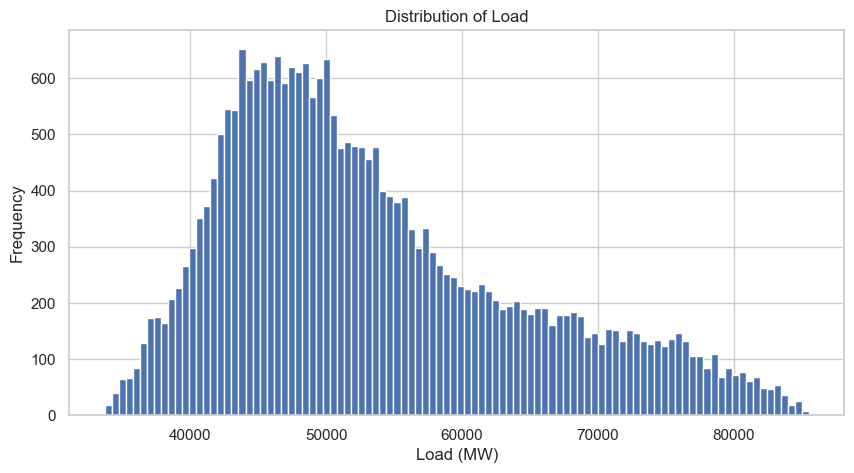

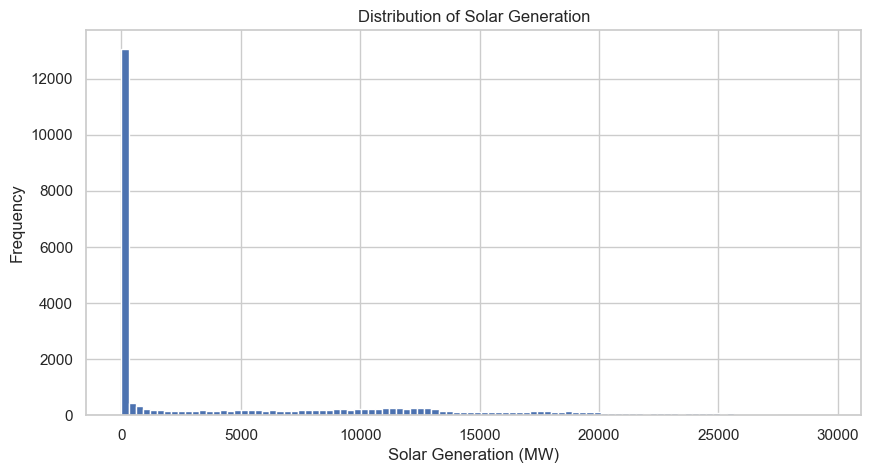

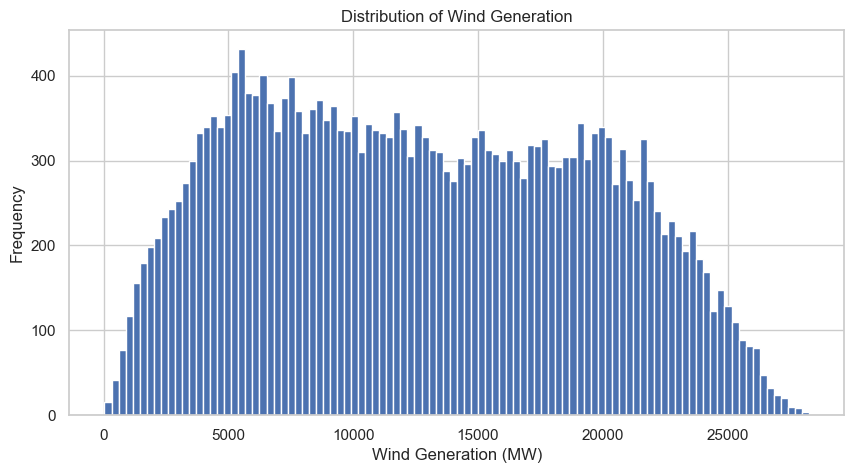

In [32]:
# Plot the distributions of load, solar, and wind generation.

plt.figure(figsize=(10, 5))

plt.hist(
    load_df["Load_MW"],
    bins=100
)

plt.xlabel("Load (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Load")

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    solar_df["Solar_MW"],
    bins=100
)

plt.xlabel("Solar Generation (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Solar Generation")

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    wind_df["Wind_MW"],
    bins=100
)

plt.xlabel("Wind Generation (MW)")
plt.ylabel("Frequency")
plt.title("Distribution of Wind Generation")

plt.show()

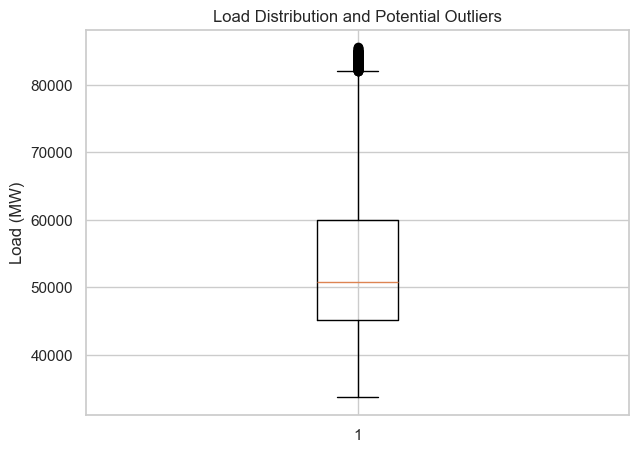

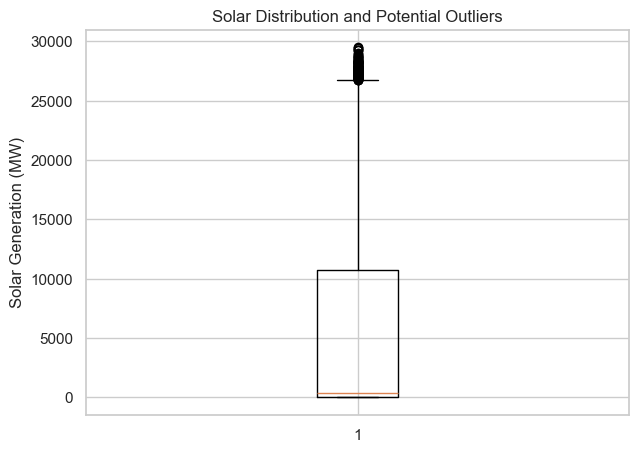

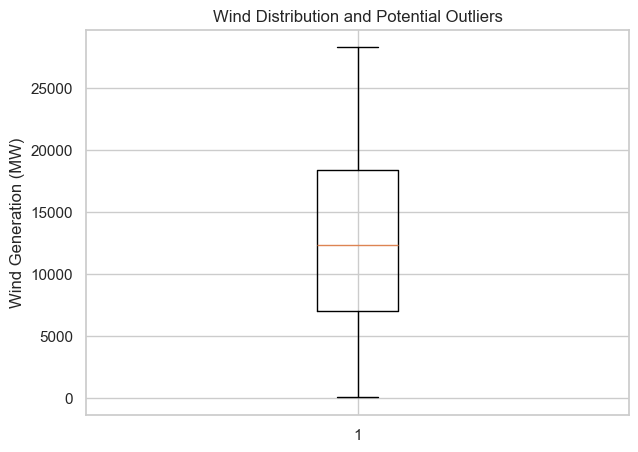

In [33]:
# Plot boxplots to identify potential extreme values.

plt.figure(figsize=(7, 5))

plt.boxplot(load_df["Load_MW"].dropna())

plt.ylabel("Load (MW)")
plt.title("Load Distribution and Potential Outliers")

plt.show()


plt.figure(figsize=(7, 5))

plt.boxplot(solar_df["Solar_MW"].dropna())

plt.ylabel("Solar Generation (MW)")
plt.title("Solar Distribution and Potential Outliers")

plt.show()


plt.figure(figsize=(7, 5))

plt.boxplot(wind_df["Wind_MW"].dropna())

plt.ylabel("Wind Generation (MW)")
plt.title("Wind Distribution and Potential Outliers")

plt.show()

# Correlation analysis

In [34]:
# Calculate correlations between load and its available features.

load_corr = load_df.select_dtypes(include=np.number).corr()["Load_MW"].sort_values(
    ascending=False
)

display(load_corr)

Load_MW      1.000000
T2M          0.621842
Hour         0.402945
Year         0.200987
DayOfYear    0.149664
Month        0.148030
IsHoliday   -0.019744
WS10M       -0.037333
DayOfWeek   -0.066573
IsWeekend   -0.079817
CLOUD_AMT   -0.138521
RH2M        -0.453082
Name: Load_MW, dtype: float64

In [35]:
# Calculate correlations between solar generation and its available features.

solar_corr = solar_df.select_dtypes(include=np.number).corr()["Solar_MW"].sort_values(
    ascending=False
)

display(solar_corr)

Solar_MW              1.000000
ALLSKY_SFC_SW_DWN     0.823454
ALLSKY_SFC_SW_DNI     0.764745
ALLSKY_SFC_SW_DIFF    0.636388
ALLSKY_KT             0.590335
T2M                   0.525200
Hour                  0.256178
Year                  0.223617
Month                 0.068610
DayOfYear             0.068313
WS10M                 0.046805
DayOfWeek            -0.004706
CLOUD_AMT            -0.171030
RH2M                 -0.649881
Name: Solar_MW, dtype: float64

In [36]:
# Calculate correlations between wind generation and its available features.

wind_corr = wind_df.select_dtypes(include=np.number).corr()["Wind_MW"].sort_values(
    ascending=False
)

display(wind_corr)

Wind_MW      1.000000
WS10M        0.570652
RH2M         0.197004
Year         0.048388
CLOUD_AMT    0.045300
DayOfWeek    0.027905
Hour        -0.114540
DayOfYear   -0.138208
Month       -0.138474
T2M         -0.149632
Name: Wind_MW, dtype: float64

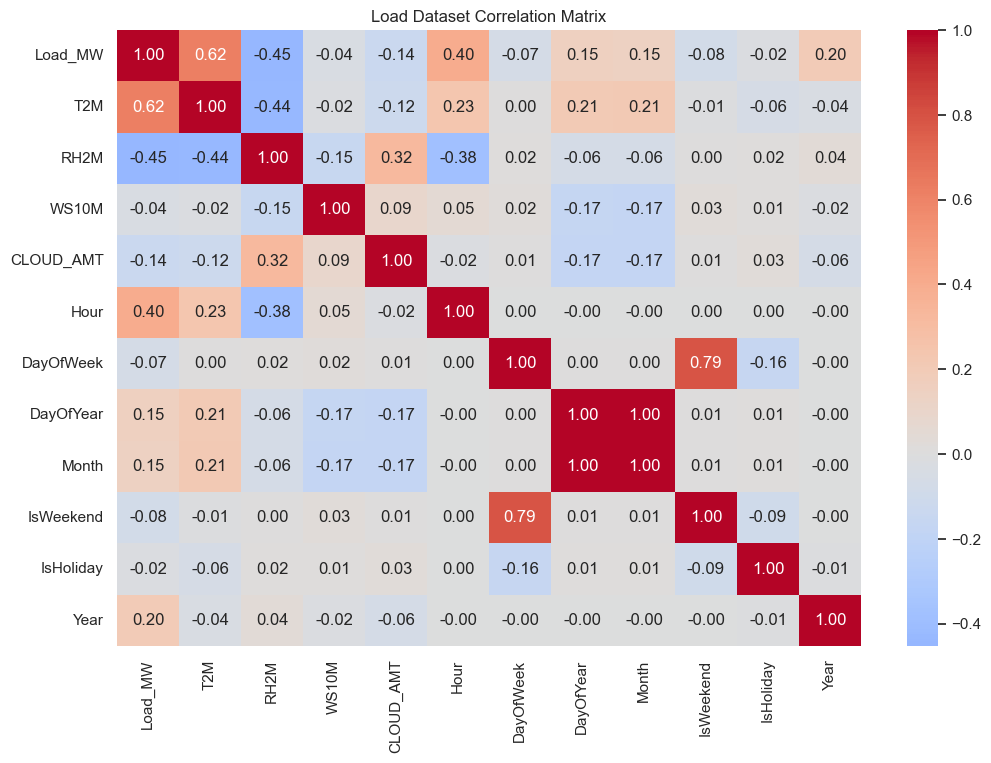

In [37]:
# Visualize correlations between load and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    load_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Load Dataset Correlation Matrix")

plt.show()

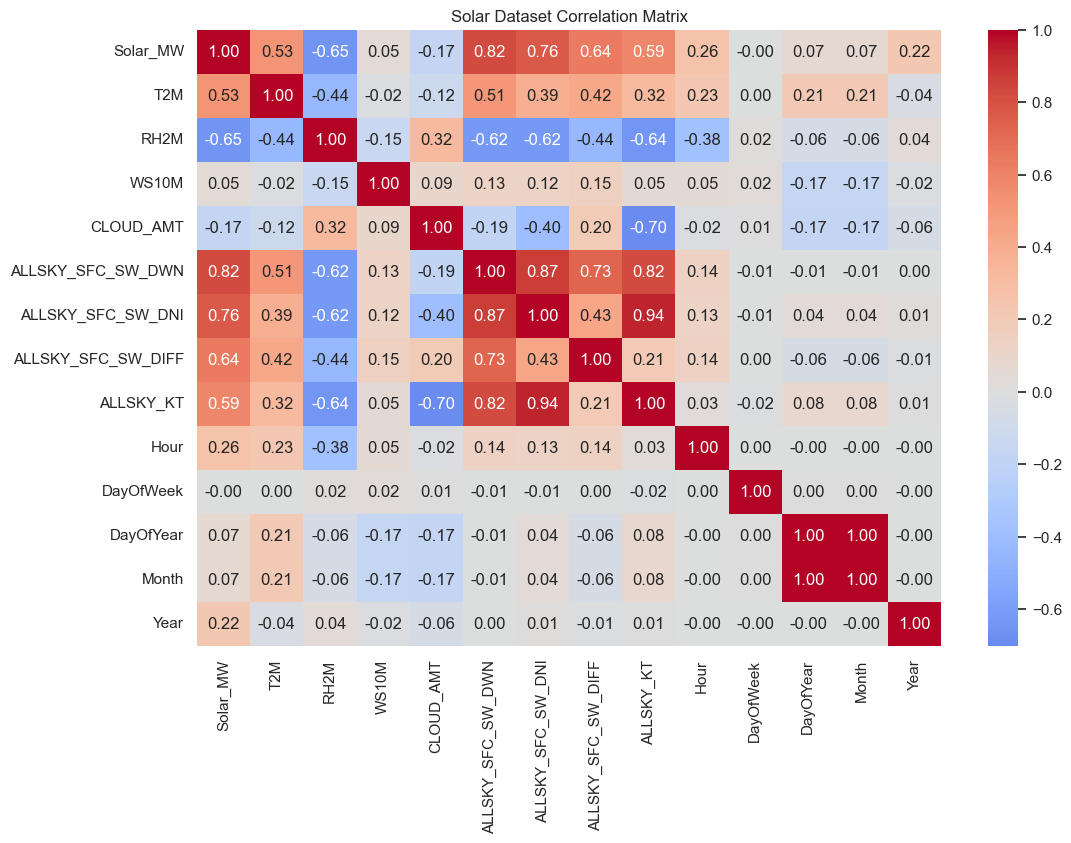

In [38]:
# Visualize correlations between solar generation and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    solar_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Solar Dataset Correlation Matrix")

plt.show()

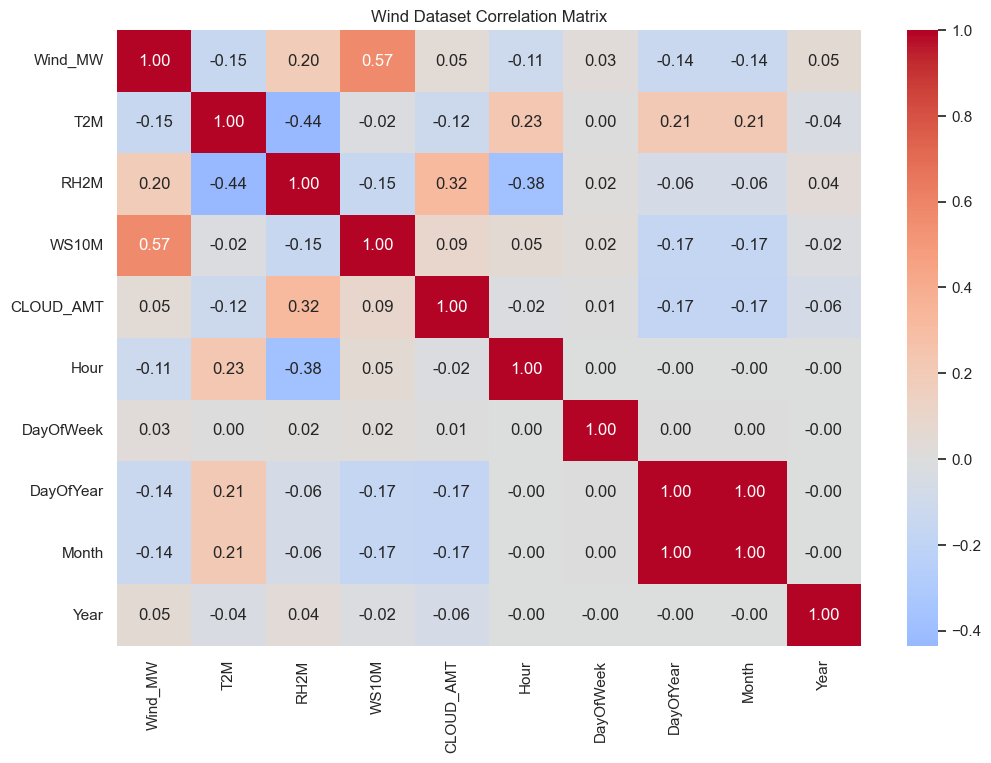

In [39]:
# Visualize correlations between wind generation and its numerical features.

plt.figure(figsize=(12, 8))

sns.heatmap(
    wind_df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Wind Dataset Correlation Matrix")

plt.show()

In [40]:
# Calculate correlations between each target and its previous time steps

def lag_correlations(df, target, max_lag):
    result = {}

    for lag in range(1, max_lag + 1):
        result[lag] = df[target].corr(df[target].shift(lag))

    return pd.Series(result, name=target)


load_lag_corr = lag_correlations(load_df, "Load_MW", 168)
solar_lag_corr = lag_correlations(solar_df, "Solar_MW", 48)
wind_lag_corr = lag_correlations(wind_df, "Wind_MW", 48)

print("Load lag correlations:")
display(load_lag_corr)

print("\nSolar lag correlations:")
display(solar_lag_corr)

print("\nWind lag correlations:")
display(wind_lag_corr)

Load lag correlations:


1      0.985073
2      0.943846
3      0.881620
4      0.803494
5      0.715247
         ...   
164    0.664644
165    0.736853
166    0.793715
167    0.830730
168    0.843508
Name: Load_MW, Length: 168, dtype: float64


Solar lag correlations:


1     0.938030
2     0.794396
3     0.621040
4     0.436987
5     0.249318
6     0.062992
7    -0.115790
8    -0.276502
9    -0.405004
10   -0.492661
11   -0.541351
12   -0.556428
13   -0.541119
14   -0.492463
15   -0.405590
16   -0.279225
17   -0.122191
18    0.051994
19    0.233164
20    0.414982
21    0.592080
22    0.756970
23    0.890920
24    0.946188
25    0.886873
26    0.750594
27    0.584622
28    0.407056
29    0.225068
30    0.043992
31   -0.129632
32   -0.285487
33   -0.410093
34   -0.495095
35   -0.542296
36   -0.556938
37   -0.542017
38   -0.494572
39   -0.409821
40   -0.286445
41   -0.132831
42    0.038255
43    0.216887
44    0.396426
45    0.571053
46    0.733001
47    0.864027
48    0.918685
Name: Solar_MW, dtype: float64


Wind lag correlations:


1     0.982208
2     0.939642
3     0.883215
4     0.818305
5     0.749041
6     0.678971
7     0.611208
8     0.548206
9     0.491817
10    0.443990
11    0.406347
12    0.379609
13    0.363483
14    0.357597
15    0.360352
16    0.369471
17    0.382649
18    0.397822
19    0.413071
20    0.426595
21    0.436585
22    0.441346
23    0.439314
24    0.427181
25    0.402299
26    0.368825
27    0.330739
28    0.289771
29    0.247484
30    0.205517
31    0.165478
32    0.128810
33    0.096878
34    0.071329
35    0.053792
36    0.045108
37    0.045124
38    0.053539
39    0.068917
40    0.089427
41    0.113277
42    0.138952
43    0.164922
44    0.189617
45    0.211255
46    0.228158
47    0.238946
48    0.240741
Name: Wind_MW, dtype: float64

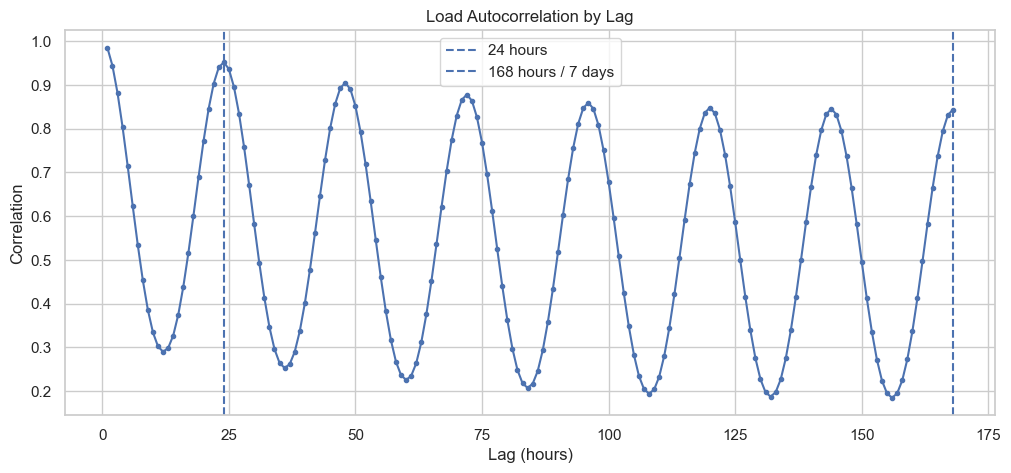

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(
    load_lag_corr.index,
    load_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(24, linestyle="--", label="24 hours")
plt.axvline(168, linestyle="--", label="168 hours / 7 days")

plt.title("Load Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

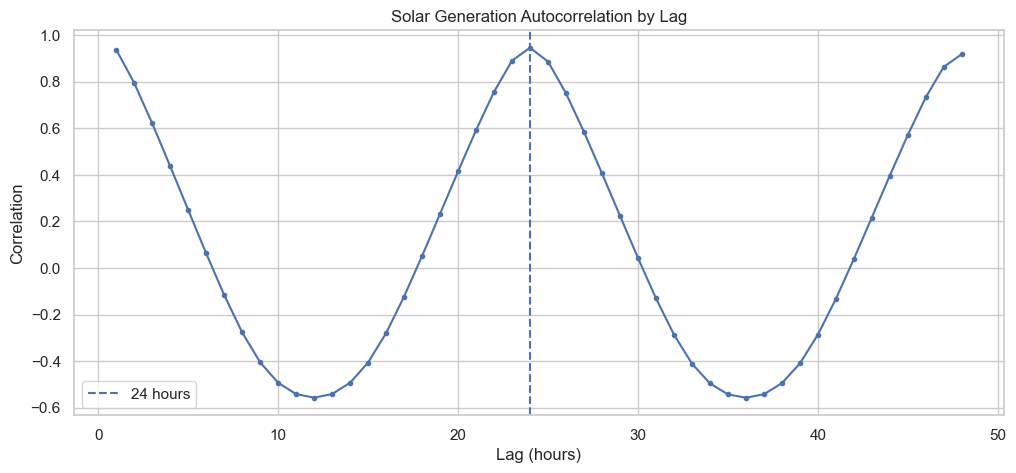

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    solar_lag_corr.index,
    solar_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(24, linestyle="--", label="24 hours")

plt.title("Solar Generation Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

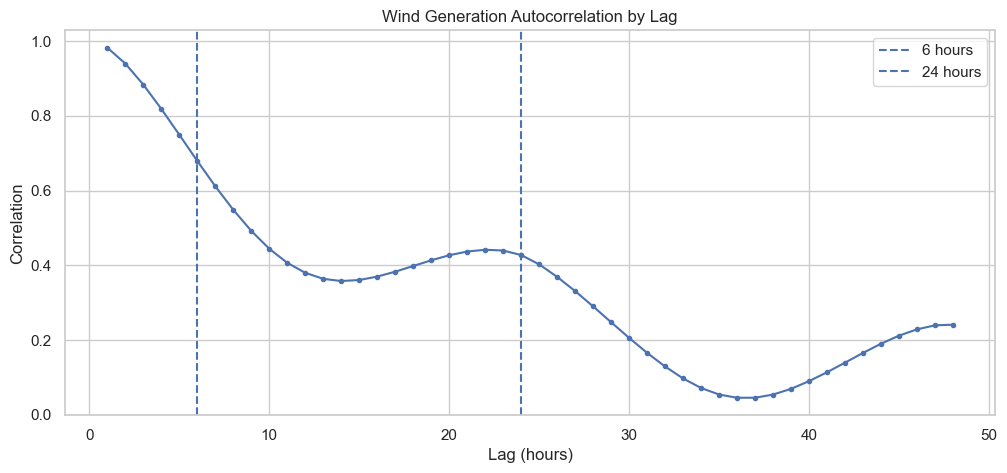

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    wind_lag_corr.index,
    wind_lag_corr.values,
    marker="o",
    markersize=3
)

plt.axvline(6, linestyle="--", label="6 hours")
plt.axvline(24, linestyle="--", label="24 hours")

plt.title("Wind Generation Autocorrelation by Lag")
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
# Create cyclic time features for all three datasets

for df in [load_df, solar_df, wind_df]:

    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

    df["DayOfWeek_sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
    df["DayOfWeek_cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)

    df["DayOfYear_sin"] = np.sin(2 * np.pi * df["DayOfYear"] / 365.25)
    df["DayOfYear_cos"] = np.cos(2 * np.pi * df["DayOfYear"] / 365.25)

In [45]:
print("Load:")
display(load_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

print("Solar:")
display(solar_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

print("Wind:")
display(wind_df[
    [
        "Hour",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "DayOfYear",
        "DayOfYear_sin",
        "DayOfYear_cos"
    ]
].head())

Load:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


Solar:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


Wind:


,Hour,Hour_sin,Hour_cos,DayOfWeek,DayOfWeek_sin,DayOfWeek_cos,DayOfYear,DayOfYear_sin,DayOfYear_cos
0,1,0.258819,0.965926,6,-0.781831,0.62349,1,0.017202,0.999852
1,2,0.500000,0.866025,6,-0.781831,0.62349,1,0.017202,0.999852
2,3,0.707107,0.707107,6,-0.781831,0.62349,1,0.017202,0.999852
3,4,0.866025,0.500000,6,-0.781831,0.62349,1,0.017202,0.999852
4,5,0.965926,0.258819,6,-0.781831,0.62349,1,0.017202,0.999852


In [46]:
# ============================================================
# VERIFY CYCLIC FEATURES
# ============================================================

cyclic_cols = [
    "Hour_sin", "Hour_cos",
    "DayOfWeek_sin", "DayOfWeek_cos",
    "DayOfYear_sin", "DayOfYear_cos"
]

for name, df in [
    ("Load", load_df),
    ("Solar", solar_df),
    ("Wind", wind_df)
]:
    
    print(f"\n{name}")
    print("-" * 50)
    
    print("Missing values:")
    print(df[cyclic_cols].isna().sum())
    
    print("\nRange:")
    print(df[cyclic_cols].agg(["min", "max"]).T)


Load
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos         0
DayOfWeek_sin    0
DayOfWeek_cos    0
DayOfYear_sin    0
DayOfYear_cos    0
dtype: int64

Range:
                    min       max
Hour_sin      -1.000000  1.000000
Hour_cos      -1.000000  1.000000
DayOfWeek_sin -0.974928  0.974928
DayOfWeek_cos -0.900969  1.000000
DayOfYear_sin -0.999999  0.999986
DayOfYear_cos -0.999979  0.999991

Solar
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos         0
DayOfWeek_sin    0
DayOfWeek_cos    0
DayOfYear_sin    0
DayOfYear_cos    0
dtype: int64

Range:
                    min       max
Hour_sin      -1.000000  1.000000
Hour_cos      -1.000000  1.000000
DayOfWeek_sin -0.974928  0.974928
DayOfWeek_cos -0.900969  1.000000
DayOfYear_sin -0.999999  0.999986
DayOfYear_cos -0.999979  0.999991

Wind
--------------------------------------------------
Missing values:
Hour_sin         0
Hour_cos       

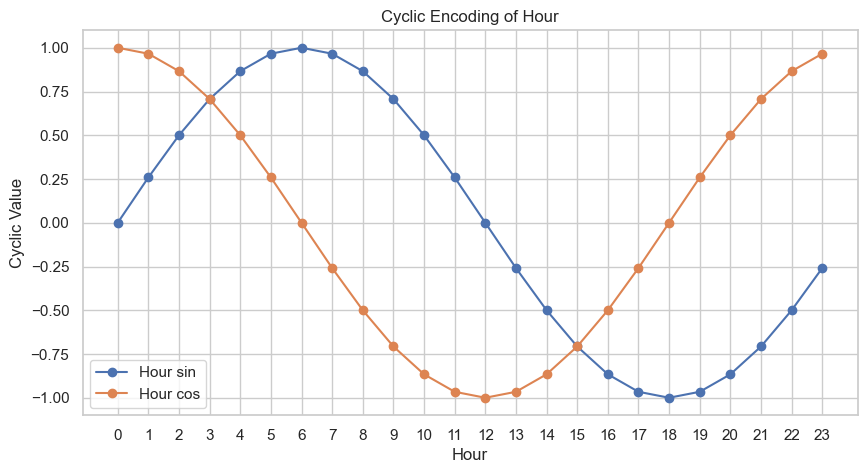

In [47]:
import matplotlib.pyplot as plt
import numpy as np

hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

plt.figure(figsize=(10, 5))

plt.plot(hours, hour_sin, marker="o", label="Hour sin")
plt.plot(hours, hour_cos, marker="o", label="Hour cos")

plt.xlabel("Hour")
plt.ylabel("Cyclic Value")
plt.title("Cyclic Encoding of Hour")
plt.xticks(range(24))
plt.grid(True)
plt.legend()

plt.show()

# Feature selection

In [48]:
# ============================================================
# FEATURE SELECTION — STEP 1
# Define candidate features
# ============================================================

load_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",

    # Calendar indicators
    "IsWeekend",
    "IsHoliday"
]


solar_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Solar radiation features
    "ALLSKY_SFC_SW_DWN",
    "ALLSKY_SFC_SW_DNI",
    "ALLSKY_SFC_SW_DIFF",
    "ALLSKY_KT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


wind_candidates = [
    "T2M",
    "RH2M",
    "WS10M",
    "CLOUD_AMT",

    # Cyclic time features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("LOAD CANDIDATES")
print(load_candidates)

print("\nSOLAR CANDIDATES")
print(solar_candidates)

print("\nWIND CANDIDATES")
print(wind_candidates)

LOAD CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'IsWeekend', 'IsHoliday']

SOLAR CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

WIND CANDIDATES
['T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [49]:
# ============================================================
# FEATURE SELECTION — STEP 2
# Check candidate columns
# ============================================================

for name, df, candidates in [
    ("LOAD", load_df, load_candidates),
    ("SOLAR", solar_df, solar_candidates),
    ("WIND", wind_df, wind_candidates)
]:
    
    missing = [col for col in candidates if col not in df.columns]
    
    print(f"\n{name}")
    print("-" * 60)
    
    if len(missing) == 0:
        print("All candidate features are available.")
    else:
        print("Missing features:")
        print(missing)


LOAD
------------------------------------------------------------
All candidate features are available.

SOLAR
------------------------------------------------------------
All candidate features are available.

WIND
------------------------------------------------------------
All candidate features are available.


In [50]:
# ============================================================
# FEATURE SELECTION — STEP 3
# Target correlations
# ============================================================

load_corr = (
    load_df[["Load_MW"] + load_candidates]
    .corr()["Load_MW"]
    .drop("Load_MW")
    .sort_values(key=abs, ascending=False)
)

solar_corr = (
    solar_df[["Solar_MW"] + solar_candidates]
    .corr()["Solar_MW"]
    .drop("Solar_MW")
    .sort_values(key=abs, ascending=False)
)

wind_corr = (
    wind_df[["Wind_MW"] + wind_candidates]
    .corr()["Wind_MW"]
    .drop("Wind_MW")
    .sort_values(key=abs, ascending=False)
)


print("LOAD — CORRELATION WITH TARGET")
print("=" * 60)
display(load_corr)

print("\nSOLAR — CORRELATION WITH TARGET")
print("=" * 60)
display(solar_corr)

print("\nWIND — CORRELATION WITH TARGET")
print("=" * 60)
display(wind_corr)

LOAD — CORRELATION WITH TARGET


T2M              0.621842
DayOfYear_cos   -0.511291
Hour_sin        -0.467154
RH2M            -0.453082
DayOfYear_sin   -0.318622
Hour_cos        -0.145227
CLOUD_AMT       -0.138521
IsWeekend       -0.079817
DayOfWeek_sin    0.063250
WS10M           -0.037333
IsHoliday       -0.019744
DayOfWeek_cos   -0.016143
Name: Load_MW, dtype: float64


SOLAR — CORRELATION WITH TARGET


ALLSKY_SFC_SW_DWN     0.823454
ALLSKY_SFC_SW_DNI     0.764745
Hour_cos             -0.696547
RH2M                 -0.649881
ALLSKY_SFC_SW_DIFF    0.636388
ALLSKY_KT             0.590335
T2M                   0.525200
Hour_sin             -0.362052
DayOfYear_cos        -0.174812
CLOUD_AMT            -0.171030
DayOfYear_sin        -0.080016
WS10M                 0.046805
DayOfWeek_sin         0.003192
DayOfWeek_cos         0.002482
Name: Solar_MW, dtype: float64


WIND — CORRELATION WITH TARGET


WS10M            0.570652
Hour_cos         0.300083
DayOfYear_sin    0.206317
RH2M             0.197004
T2M             -0.149632
Hour_sin         0.111427
DayOfYear_cos    0.092887
CLOUD_AMT        0.045300
DayOfWeek_sin   -0.028686
DayOfWeek_cos   -0.007819
Name: Wind_MW, dtype: float64

In [51]:
# ============================================================
# FEATURE SELECTION — STEP 4
# Feature-to-feature correlations
# ============================================================

print("LOAD FEATURE CORRELATION")
display(
    load_df[load_candidates]
    .corr()
    .round(2)
)

print("\nSOLAR FEATURE CORRELATION")
display(
    solar_df[solar_candidates]
    .corr()
    .round(2)
)

print("\nWIND FEATURE CORRELATION")
display(
    wind_df[wind_candidates]
    .corr()
    .round(2)
)

LOAD FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos,IsWeekend,IsHoliday
T2M,1.00,-0.44,-0.02,-0.12,-0.31,-0.31,0.00,-0.02,-0.25,-0.72,-0.01,-0.06
RH2M,-0.44,1.00,-0.15,0.32,0.50,0.45,-0.00,-0.03,0.14,0.05,0.00,0.02
WS10M,-0.02,-0.15,1.00,0.09,-0.06,-0.14,-0.03,0.02,0.21,0.11,0.03,0.01
CLOUD_AMT,-0.12,0.32,0.09,1.00,0.03,0.01,0.01,-0.01,0.26,0.06,0.01,0.03
Hour_sin,-0.31,0.50,-0.06,0.03,1.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00
Hour_cos,-0.31,0.45,-0.14,0.01,0.00,1.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00
DayOfWeek_sin,0.00,-0.00,-0.03,0.01,0.00,-0.00,1.00,-0.00,0.00,0.00,-0.79,0.03
DayOfWeek_cos,-0.02,-0.03,0.02,-0.01,-0.00,0.00,-0.00,1.00,-0.00,0.00,0.18,0.10
DayOfYear_sin,-0.25,0.14,0.21,0.26,-0.00,-0.00,0.00,-0.00,1.00,-0.00,-0.00,-0.04
DayOfYear_cos,-0.72,0.05,0.11,0.06,0.00,-0.00,0.00,0.00,-0.00,1.00,-0.00,0.06



SOLAR FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos
T2M,1.00,-0.44,-0.02,-0.12,0.51,0.39,0.42,0.32,-0.31,-0.31,0.00,-0.02,-0.25,-0.72
RH2M,-0.44,1.00,-0.15,0.32,-0.62,-0.62,-0.44,-0.64,0.50,0.45,-0.00,-0.03,0.14,0.05
WS10M,-0.02,-0.15,1.00,0.09,0.13,0.12,0.15,0.05,-0.06,-0.14,-0.03,0.02,0.21,0.11
CLOUD_AMT,-0.12,0.32,0.09,1.00,-0.19,-0.40,0.20,-0.70,0.03,0.01,0.01,-0.01,0.26,0.06
ALLSKY_SFC_SW_DWN,0.51,-0.62,0.13,-0.19,1.00,0.87,0.73,0.82,-0.18,-0.79,0.00,0.00,-0.00,-0.19
ALLSKY_SFC_SW_DNI,0.39,-0.62,0.12,-0.40,0.87,1.00,0.43,0.94,-0.15,-0.71,0.00,0.01,-0.06,-0.05
ALLSKY_SFC_SW_DIFF,0.42,-0.44,0.15,0.20,0.73,0.43,1.00,0.21,-0.16,-0.73,-0.00,-0.00,0.08,-0.20
ALLSKY_KT,0.32,-0.64,0.05,-0.70,0.82,0.94,0.21,1.00,-0.09,-0.47,-0.00,0.02,-0.13,-0.04
Hour_sin,-0.31,0.50,-0.06,0.03,-0.18,-0.15,-0.16,-0.09,1.00,0.00,0.00,-0.00,-0.00,0.00
Hour_cos,-0.31,0.45,-0.14,0.01,-0.79,-0.71,-0.73,-0.47,0.00,1.00,-0.00,0.00,-0.00,-0.00



WIND FEATURE CORRELATION


,T2M,RH2M,WS10M,CLOUD_AMT,Hour_sin,Hour_cos,DayOfWeek_sin,DayOfWeek_cos,DayOfYear_sin,DayOfYear_cos
T2M,1.00,-0.44,-0.02,-0.12,-0.31,-0.31,0.00,-0.02,-0.25,-0.72
RH2M,-0.44,1.00,-0.15,0.32,0.50,0.45,-0.00,-0.03,0.14,0.05
WS10M,-0.02,-0.15,1.00,0.09,-0.06,-0.14,-0.03,0.02,0.21,0.11
CLOUD_AMT,-0.12,0.32,0.09,1.00,0.03,0.01,0.01,-0.01,0.26,0.06
Hour_sin,-0.31,0.50,-0.06,0.03,1.00,0.00,0.00,-0.00,-0.00,0.00
Hour_cos,-0.31,0.45,-0.14,0.01,0.00,1.00,-0.00,0.00,-0.00,-0.00
DayOfWeek_sin,0.00,-0.00,-0.03,0.01,0.00,-0.00,1.00,-0.00,0.00,0.00
DayOfWeek_cos,-0.02,-0.03,0.02,-0.01,-0.00,0.00,-0.00,1.00,-0.00,0.00
DayOfYear_sin,-0.25,0.14,0.21,0.26,-0.00,-0.00,0.00,-0.00,1.00,-0.00
DayOfYear_cos,-0.72,0.05,0.11,0.06,0.00,-0.00,0.00,0.00,-0.00,1.00


In [52]:
# ============================================================
# FEATURE SELECTION — STEP 5
# Find highly correlated feature pairs
# ============================================================

def highly_correlated_pairs(df, features, threshold=0.80):
    
    corr_matrix = df[features].corr().abs()
    
    pairs = []
    
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            
            corr_value = corr_matrix.iloc[i, j]
            
            if corr_value >= threshold:
                pairs.append(
                    (
                        features[i],
                        features[j],
                        corr_value
                    )
                )
    
    return sorted(
        pairs,
        key=lambda x: x[2],
        reverse=True
    )


print("LOAD — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(load_df, load_candidates):
    print(pair)


print("\nSOLAR — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(solar_df, solar_candidates):
    print(pair)


print("\nWIND — HIGH CORRELATION PAIRS")
for pair in highly_correlated_pairs(wind_df, wind_candidates):
    print(pair)

LOAD — HIGH CORRELATION PAIRS

SOLAR — HIGH CORRELATION PAIRS
('ALLSKY_SFC_SW_DNI', 'ALLSKY_KT', np.float64(0.9383538630125388))
('ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', np.float64(0.8734349113448012))
('ALLSKY_SFC_SW_DWN', 'ALLSKY_KT', np.float64(0.8216159847236312))

WIND — HIGH CORRELATION PAIRS


In [53]:
# ============================================================
# FEATURE SELECTION — STEP 6
# Missing-value percentage
# ============================================================

def missing_percentage(df, features):
    
    return (
        df[features]
        .isna()
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )


print("LOAD")
display(missing_percentage(load_df, load_candidates))

print("\nSOLAR")
display(missing_percentage(solar_df, solar_candidates))

print("\nWIND")
display(missing_percentage(wind_df, wind_candidates))

LOAD


T2M              0.0
RH2M             0.0
WS10M            0.0
CLOUD_AMT        0.0
Hour_sin         0.0
Hour_cos         0.0
DayOfWeek_sin    0.0
DayOfWeek_cos    0.0
DayOfYear_sin    0.0
DayOfYear_cos    0.0
IsWeekend        0.0
IsHoliday        0.0
dtype: float64


SOLAR


ALLSKY_KT             47.552953
T2M                    0.000000
WS10M                  0.000000
CLOUD_AMT              0.000000
ALLSKY_SFC_SW_DWN      0.000000
RH2M                   0.000000
ALLSKY_SFC_SW_DNI      0.000000
ALLSKY_SFC_SW_DIFF     0.000000
Hour_sin               0.000000
Hour_cos               0.000000
DayOfWeek_sin          0.000000
DayOfWeek_cos          0.000000
DayOfYear_sin          0.000000
DayOfYear_cos          0.000000
dtype: float64


WIND


T2M              0.0
RH2M             0.0
WS10M            0.0
CLOUD_AMT        0.0
Hour_sin         0.0
Hour_cos         0.0
DayOfWeek_sin    0.0
DayOfWeek_cos    0.0
DayOfYear_sin    0.0
DayOfYear_cos    0.0
dtype: float64

In [54]:
# ============================================================
# STEP 1 — DEFINE TARGETS AND FEATURES
# ============================================================

# -------------------------
# LOAD
# -------------------------

load_target = "Load_MW"

load_features = [
    # Past load
    "Load_MW_lag1",
    "Load_MW_lag24",
    "Load_MW_lag168",

    # Weather
    "T2M",
    "RH2M",
    "CLOUD_AMT",
    "WS10M",

    # Calendar
    "IsWeekend",
    "IsHoliday",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# -------------------------
# SOLAR
# -------------------------

solar_target = "Solar_MW"

solar_features = [
    # Past solar generation
    "Solar_MW_lag1",
    "Solar_MW_lag24",

    # Weather
    "CLOUD_AMT",
    "WS10M",
    "RH2M",

    # Solar radiation / insolation
    "ALLSKY_SFC_SW_DWN",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# -------------------------
# WIND
# -------------------------

wind_target = "Wind_MW"

wind_features = [
    # Past wind generation
    "Wind_MW_lag1",
    "Wind_MW_lag6",
    "Wind_MW_lag24",

    # Weather
    "WS10M",
    "T2M",

    # Wind direction
    "WindDirection",

    # Cyclic features
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("LOAD FEATURES:")
print(load_features)

print("\nSOLAR FEATURES:")
print(solar_features)

print("\nWIND FEATURES:")
print(wind_features)

LOAD FEATURES:
['Load_MW_lag1', 'Load_MW_lag24', 'Load_MW_lag168', 'T2M', 'RH2M', 'CLOUD_AMT', 'WS10M', 'IsWeekend', 'IsHoliday', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

SOLAR FEATURES:
['Solar_MW_lag1', 'Solar_MW_lag24', 'CLOUD_AMT', 'WS10M', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']

WIND FEATURES:
['Wind_MW_lag1', 'Wind_MW_lag6', 'Wind_MW_lag24', 'WS10M', 'T2M', 'WindDirection', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [55]:
print(wind_df.columns.tolist())

['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'Datetime_Local', 'Year', 'DayName', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


# test/train split

In [56]:
# ===========================================================
# STEP 1 — 2-YEAR TRAINING / 1-YEAR TESTING SPLIT
# ============================================================

train_end = pd.Timestamp("2024-12-31 23:00:00+00:00")
test_start = pd.Timestamp("2025-01-01 00:00:00+00:00")


def split_train_test(df):
    
    train = df[df["Datetime_UTC"] <= train_end].copy()
    test = df[df["Datetime_UTC"] >= test_start].copy()
    
    return train, test


load_train, load_test = split_train_test(load_df)

solar_train, solar_test = split_train_test(solar_df)

wind_train, wind_test = split_train_test(wind_df)

In [57]:
# ============================================================
# STEP 3 — VERIFY TRAIN / TEST SPLIT
# ============================================================

datasets = {
    "LOAD": (load_train, load_test),
    "SOLAR": (solar_train, solar_test),
    "WIND": (wind_train, wind_test)
}

for name, (train, test) in datasets.items():
    
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    
    print("\nTRAINING DATA")
    print("Start :", train["Datetime_UTC"].min())
    print("End   :", train["Datetime_UTC"].max())
    print("Rows  :", len(train))
    
    print("\nTESTING DATA")
    print("Start :", test["Datetime_UTC"].min())
    print("End   :", test["Datetime_UTC"].max())
    print("Rows  :", len(test))


LOAD

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760

SOLAR

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760

WIND

TRAINING DATA
Start : 2023-01-01 07:00:00+00:00
End   : 2024-12-31 23:00:00+00:00
Rows  : 17537

TESTING DATA
Start : 2025-01-01 00:00:00+00:00
End   : 2025-12-31 23:00:00+00:00
Rows  : 8760


In [58]:
# ============================================================
# STEP 4 — CHECK FOR TRAIN / TEST OVERLAP
# ============================================================

for name, train, test in [
    ("LOAD", load_train, load_test),
    ("SOLAR", solar_train, solar_test),
    ("WIND", wind_train, wind_test)
]:
    
    overlap = set(train["Datetime_UTC"]).intersection(
        set(test["Datetime_UTC"])
    )
    
    print(f"{name}: {len(overlap)} overlapping timestamps")

LOAD: 0 overlapping timestamps
SOLAR: 0 overlapping timestamps
WIND: 0 overlapping timestamps


In [59]:
# ============================================================
# STEP 5 — FINAL FEATURE DEFINITIONS
# ============================================================

load_features = [
    "Load_MW",
    "RH2M",
    "IsWeekend",
    "IsHoliday",
    "T2M",
    "CLOUD_AMT",
    "WS10M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


solar_features = [
    "Solar_MW",
    "ALLSKY_SFC_SW_DWN",
    "CLOUD_AMT",
    "WS10M",
    "RH2M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


wind_features = [
    "Wind_MW",
    "WS10M",
    "WindDirection",
    "T2M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


print("Load features :", len(load_features))
print("Solar features:", len(solar_features))
print("Wind features :", len(wind_features))

Load features : 13
Solar features: 11
Wind features : 10


In [60]:
print("WIND TRAIN COLUMNS:")
print(wind_train.columns.tolist())

WIND TRAIN COLUMNS:
['Datetime_UTC', 'Wind_MW', 'T2M', 'RH2M', 'WS10M', 'CLOUD_AMT', 'Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'Datetime_Local', 'Year', 'DayName', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [61]:
# ============================================================
# STEP 6.1 — VERIFY FINAL FEATURES
# ============================================================

# ------------------------------------------------------------
# LOAD FEATURES
# ------------------------------------------------------------

load_features = [
    "Load_MW",          # past load through LSTM sequence
    "RH2M",             # Humidity
    "IsWeekend",
    "IsHoliday",
    "T2M",              # Temperature
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",
    "CLOUD_AMT",        # Cloud cover
    "WS10M"             # Wind speed
]


# ------------------------------------------------------------
# SOLAR FEATURES
# ------------------------------------------------------------

solar_features = [
    "Solar_MW",         # past generation through LSTM sequence
    "ALLSKY_SFC_SW_DWN", # Insolation / solar radiation
    "CLOUD_AMT",        # Cloud cover
    "WS10M",             # Wind speed
    "RH2M",              # Humidity
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# ------------------------------------------------------------
# WIND FEATURES
# ------------------------------------------------------------

wind_features = [
    "WS10M",             # Wind speed
    "T2M",               # Temperature
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]


# ============================================================
# CHECK WHETHER EVERY FEATURE EXISTS
# ============================================================

def check_features(df, features, dataset_name):

    missing = [f for f in features if f not in df.columns]

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)

    print("Selected features:")
    for f in features:
        print("  ✓", f)

    if missing:
        print("\n❌ MISSING FEATURES:")
        for f in missing:
            print("  ✗", f)
    else:
        print("\n✅ ALL SELECTED FEATURES EXIST")


check_features(
    load_train,
    load_features,
    "LOAD"
)

check_features(
    solar_train,
    solar_features,
    "SOLAR"
)

check_features(
    wind_train,
    wind_features,
    "WIND"
)

LOAD
Selected features:
  ✓ Load_MW
  ✓ RH2M
  ✓ IsWeekend
  ✓ IsHoliday
  ✓ T2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos
  ✓ CLOUD_AMT
  ✓ WS10M

✅ ALL SELECTED FEATURES EXIST
SOLAR
Selected features:
  ✓ Solar_MW
  ✓ ALLSKY_SFC_SW_DWN
  ✓ CLOUD_AMT
  ✓ WS10M
  ✓ RH2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos

✅ ALL SELECTED FEATURES EXIST
WIND
Selected features:
  ✓ WS10M
  ✓ T2M
  ✓ Hour_sin
  ✓ Hour_cos
  ✓ DayOfWeek_sin
  ✓ DayOfWeek_cos
  ✓ DayOfYear_sin
  ✓ DayOfYear_cos

✅ ALL SELECTED FEATURES EXIST


In [62]:
# ============================================================
# STEP 7 — FEATURE AND TARGET SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np


# ============================================================
# 1. CREATE SCALERS
# ============================================================

load_X_scaler = StandardScaler()
solar_X_scaler = StandardScaler()
wind_X_scaler = StandardScaler()

load_y_scaler = StandardScaler()
solar_y_scaler = StandardScaler()
wind_y_scaler = StandardScaler()


# ============================================================
# 2. FIT FEATURE SCALERS ONLY ON TRAINING DATA
# ============================================================

load_X_scaler.fit(load_train[load_features])

solar_X_scaler.fit(solar_train[solar_features])

wind_X_scaler.fit(wind_train[wind_features])


# ============================================================
# 3. TRANSFORM TRAINING FEATURES
# ============================================================

load_train_X = load_X_scaler.transform(
    load_train[load_features]
)

solar_train_X = solar_X_scaler.transform(
    solar_train[solar_features]
)

wind_train_X = wind_X_scaler.transform(
    wind_train[wind_features]
)


# ============================================================
# 4. TRANSFORM TESTING FEATURES
#    IMPORTANT: SAME TRAINING SCALER
# ============================================================

load_test_X = load_X_scaler.transform(
    load_test[load_features]
)

solar_test_X = solar_X_scaler.transform(
    solar_test[solar_features]
)

wind_test_X = wind_X_scaler.transform(
    wind_test[wind_features]
)


# ============================================================
# 5. FIT TARGET SCALERS ONLY ON TRAINING TARGET
# ============================================================

load_y_scaler.fit(
    load_train[["Load_MW"]]
)

solar_y_scaler.fit(
    solar_train[["Solar_MW"]]
)

wind_y_scaler.fit(
    wind_train[["Wind_MW"]]
)


# ============================================================
# 6. TRANSFORM TRAINING TARGETS
# ============================================================

load_train_y = load_y_scaler.transform(
    load_train[["Load_MW"]]
).flatten()

solar_train_y = solar_y_scaler.transform(
    solar_train[["Solar_MW"]]
).flatten()

wind_train_y = wind_y_scaler.transform(
    wind_train[["Wind_MW"]]
).flatten()


# ============================================================
# 7. TRANSFORM TESTING TARGETS
# ============================================================

load_test_y = load_y_scaler.transform(
    load_test[["Load_MW"]]
).flatten()

solar_test_y = solar_y_scaler.transform(
    solar_test[["Solar_MW"]]
).flatten()

wind_test_y = wind_y_scaler.transform(
    wind_test[["Wind_MW"]]
).flatten()


print("✅ SCALING COMPLETED")

✅ SCALING COMPLETED


In [63]:
# ============================================================
# STEP 7.1 — CHECK SCALED DATA SHAPES
# ============================================================

print("LOAD")
print("Train X:", load_train_X.shape)
print("Train y:", load_train_y.shape)
print("Test X :", load_test_X.shape)
print("Test y :", load_test_y.shape)


print("\nSOLAR")
print("Train X:", solar_train_X.shape)
print("Train y:", solar_train_y.shape)
print("Test X :", solar_test_X.shape)
print("Test y :", solar_test_y.shape)


print("\nWIND")
print("Train X:", wind_train_X.shape)
print("Train y:", wind_train_y.shape)
print("Test X :", wind_test_X.shape)
print("Test y :", wind_test_y.shape)

LOAD
Train X: (17537, 13)
Train y: (17537,)
Test X : (8760, 13)
Test y : (8760,)

SOLAR
Train X: (17537, 11)
Train y: (17537,)
Test X : (8760, 11)
Test y : (8760,)

WIND
Train X: (17537, 8)
Train y: (17537,)
Test X : (8760, 8)
Test y : (8760,)


In [64]:
# ============================================================
# STEP 8 — CREATE LSTM SEQUENCES
# ============================================================

def create_sequences(X, y, lookback):
    
    X_sequences = []
    y_sequences = []
    
    for i in range(lookback, len(X)):
        
        X_sequences.append(
            X[i - lookback:i]
        )
        
        y_sequences.append(
            y[i]
        )
    
    return np.array(X_sequences), np.array(y_sequences)

In [65]:
# ============================================================
# STEP 8.1 — TRAINING SEQUENCES
# ============================================================

# Load: 1 week
LOAD_LOOKBACK = 168

# Solar: 24 hours
SOLAR_LOOKBACK = 24

# Wind: 1 hour
WIND_LOOKBACK = 1


load_X_train_seq, load_y_train_seq = create_sequences(
    load_train_X,
    load_train_y,
    LOAD_LOOKBACK
)


solar_X_train_seq, solar_y_train_seq = create_sequences(
    solar_train_X,
    solar_train_y,
    SOLAR_LOOKBACK
)


wind_X_train_seq, wind_y_train_seq = create_sequences(
    wind_train_X,
    wind_train_y,
    WIND_LOOKBACK
)


print("Training sequences created.")

Training sequences created.


In [66]:
# ============================================================
# STEP 8.2 — TESTING SEQUENCES
# ============================================================

def create_test_sequences(
    train_X,
    train_y,
    test_X,
    test_y,
    lookback
):
    
    # Take enough historical training data
    # to provide context for the first test prediction
    history_X = train_X[-lookback:]
    history_y = train_y[-lookback:]
    
    # Combine historical context with test period
    combined_X = np.concatenate(
        [history_X, test_X],
        axis=0
    )
    
    combined_y = np.concatenate(
        [history_y, test_y],
        axis=0
    )
    
    X_sequences = []
    y_sequences = []
    
    # Start predicting from the first test observation
    for i in range(lookback, len(combined_X)):
        
        X_sequences.append(
            combined_X[i - lookback:i]
        )
        
        y_sequences.append(
            combined_y[i]
        )
    
    return np.array(X_sequences), np.array(y_sequences)

In [67]:
# ============================================================
# STEP 8.3 — CREATE TEST SEQUENCES
# ============================================================

load_X_test_seq, load_y_test_seq = create_test_sequences(
    load_train_X,
    load_train_y,
    load_test_X,
    load_test_y,
    LOAD_LOOKBACK
)


solar_X_test_seq, solar_y_test_seq = create_test_sequences(
    solar_train_X,
    solar_train_y,
    solar_test_X,
    solar_test_y,
    SOLAR_LOOKBACK
)


wind_X_test_seq, wind_y_test_seq = create_test_sequences(
    wind_train_X,
    wind_train_y,
    wind_test_X,
    wind_test_y,
    WIND_LOOKBACK
)


print("Testing sequences created.")

Testing sequences created.


In [68]:
# ============================================================
# STEP 8.4 — VERIFY SEQUENCE SHAPES
# ============================================================

print("=" * 60)
print("LOAD")
print("=" * 60)

print("X train:", load_X_train_seq.shape)
print("y train:", load_y_train_seq.shape)
print("X test :", load_X_test_seq.shape)
print("y test :", load_y_test_seq.shape)


print("\n" + "=" * 60)
print("SOLAR")
print("=" * 60)

print("X train:", solar_X_train_seq.shape)
print("y train:", solar_y_train_seq.shape)
print("X test :", solar_X_test_seq.shape)
print("y test :", solar_y_test_seq.shape)


print("\n" + "=" * 60)
print("WIND")
print("=" * 60)

print("X train:", wind_X_train_seq.shape)
print("y train:", wind_y_train_seq.shape)
print("X test :", wind_X_test_seq.shape)
print("y test :", wind_y_test_seq.shape)

LOAD
X train: (17369, 168, 13)
y train: (17369,)
X test : (8760, 168, 13)
y test : (8760,)

SOLAR
X train: (17513, 24, 11)
y train: (17513,)
X test : (8760, 24, 11)
y test : (8760,)

WIND
X train: (17536, 1, 8)
y train: (17536,)
X test : (8760, 1, 8)
y test : (8760,)


In [69]:
# ============================================================
# STEP 9 — CONVERT SEQUENCES TO PYTORCH TENSORS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader


# Convert NumPy arrays to float32 tensors

load_X_train_tensor = torch.tensor(
    load_X_train_seq,
    dtype=torch.float32
)

load_y_train_tensor = torch.tensor(
    load_y_train_seq,
    dtype=torch.float32
)

load_X_test_tensor = torch.tensor(
    load_X_test_seq,
    dtype=torch.float32
)

load_y_test_tensor = torch.tensor(
    load_y_test_seq,
    dtype=torch.float32
)


solar_X_train_tensor = torch.tensor(
    solar_X_train_seq,
    dtype=torch.float32
)

solar_y_train_tensor = torch.tensor(
    solar_y_train_seq,
    dtype=torch.float32
)

solar_X_test_tensor = torch.tensor(
    solar_X_test_seq,
    dtype=torch.float32
)

solar_y_test_tensor = torch.tensor(
    solar_y_test_seq,
    dtype=torch.float32
)


wind_X_train_tensor = torch.tensor(
    wind_X_train_seq,
    dtype=torch.float32
)

wind_y_train_tensor = torch.tensor(
    wind_y_train_seq,
    dtype=torch.float32
)

wind_X_test_tensor = torch.tensor(
    wind_X_test_seq,
    dtype=torch.float32
)

wind_y_test_tensor = torch.tensor(
    wind_y_test_seq,
    dtype=torch.float32
)


print("PyTorch tensors created successfully.")

PyTorch tensors created successfully.


In [70]:
# ============================================================
# STEP 9.1 — PYTORCH DATASET
# ============================================================

class ForecastDataset(Dataset):
    
    def __init__(self, X, y):
        self.X = X
        self.y = y
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [71]:
# ============================================================
# STEP 9.2 — CREATE PYTORCH DATASETS
# ============================================================

load_train_dataset = ForecastDataset(
    load_X_train_tensor,
    load_y_train_tensor
)

load_test_dataset = ForecastDataset(
    load_X_test_tensor,
    load_y_test_tensor
)


solar_train_dataset = ForecastDataset(
    solar_X_train_tensor,
    solar_y_train_tensor
)

solar_test_dataset = ForecastDataset(
    solar_X_test_tensor,
    solar_y_test_tensor
)


wind_train_dataset = ForecastDataset(
    wind_X_train_tensor,
    wind_y_train_tensor
)

wind_test_dataset = ForecastDataset(
    wind_X_test_tensor,
    wind_y_test_tensor
)


print("PyTorch datasets created.")

PyTorch datasets created.


In [72]:
# ============================================================
# STEP 9.3 — CREATE PYTORCH DATALOADERS
# ============================================================

BATCH_SIZE = 64


load_train_loader = DataLoader(
    load_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

load_test_loader = DataLoader(
    load_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


solar_train_loader = DataLoader(
    solar_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

solar_test_loader = DataLoader(
    solar_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


wind_train_loader = DataLoader(
    wind_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

wind_test_loader = DataLoader(
    wind_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("DataLoaders created successfully.")

DataLoaders created successfully.


In [73]:
# ============================================================
# STEP 9.4 — VERIFY DATALOADER BATCHES
# ============================================================

load_X_batch, load_y_batch = next(iter(load_train_loader))

solar_X_batch, solar_y_batch = next(iter(solar_train_loader))

wind_X_batch, wind_y_batch = next(iter(wind_train_loader))


print("LOAD")
print("X batch shape:", load_X_batch.shape)
print("y batch shape:", load_y_batch.shape)


print("\nSOLAR")
print("X batch shape:", solar_X_batch.shape)
print("y batch shape:", solar_y_batch.shape)


print("\nWIND")
print("X batch shape:", wind_X_batch.shape)
print("y batch shape:", wind_y_batch.shape)

LOAD
X batch shape: torch.Size([64, 168, 13])
y batch shape: torch.Size([64])

SOLAR
X batch shape: torch.Size([64, 24, 11])
y batch shape: torch.Size([64])

WIND
X batch shape: torch.Size([64, 1, 8])
y batch shape: torch.Size([64])


In [74]:
# ============================================================
# STEP 9.5 — SELECT COMPUTATION DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


# LOAD FORECASTING

In [75]:
# ============================================================
# STEP 10 — DEFINE LSTM MODEL
# ============================================================

import torch
import torch.nn as nn


class LSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        # x shape:
        # [batch_size, sequence_length, input_size]

        output, (hidden, cell) = self.lstm(x)

        # Take the output from the final timestep
        last_output = output[:, -1, :]

        last_output = self.dropout(last_output)

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [76]:
# ============================================================
# STEP 10.1 — CREATE LOAD LSTM
# ============================================================

load_input_size = len(load_features)

load_model = LSTMForecaster(
    input_size=load_input_size,
    hidden_size=64,
    num_layers=2,
    dropout=0.2
)

load_model = load_model.to(device)

print(load_model)

LSTMForecaster(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [77]:
# ============================================================
# STEP 10.2 — MODEL PARAMETERS
# ============================================================

total_parameters = sum(
    p.numel()
    for p in load_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 53569


In [78]:
# ============================================================
# STEP 10.3 — TEST MODEL FORWARD PASS
# ============================================================

load_X_batch, load_y_batch = next(
    iter(load_train_loader)
)

load_X_batch = load_X_batch.to(device)
load_y_batch = load_y_batch.to(device)


with torch.no_grad():

    output = load_model(load_X_batch)


print("Input shape :", load_X_batch.shape)
print("Target shape:", load_y_batch.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [79]:
# ============================================================
# STEP 10.4 — LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    load_model.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [80]:
# ============================================================
# STEP 10.5 — TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs,
    device
):

    model.train()

    history = []

    for epoch in range(epochs):

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        epoch_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        history.append(epoch_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.6f}"
        )

    return history

In [81]:
# ============================================================
# STEP 10.6 — TRAIN LOAD LSTM
# ============================================================

EPOCHS = 30

load_history = train_model(
    model=load_model,
    train_loader=load_train_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)

Epoch [1/30] Loss: 0.125828
Epoch [2/30] Loss: 0.022748


KeyboardInterrupt: 

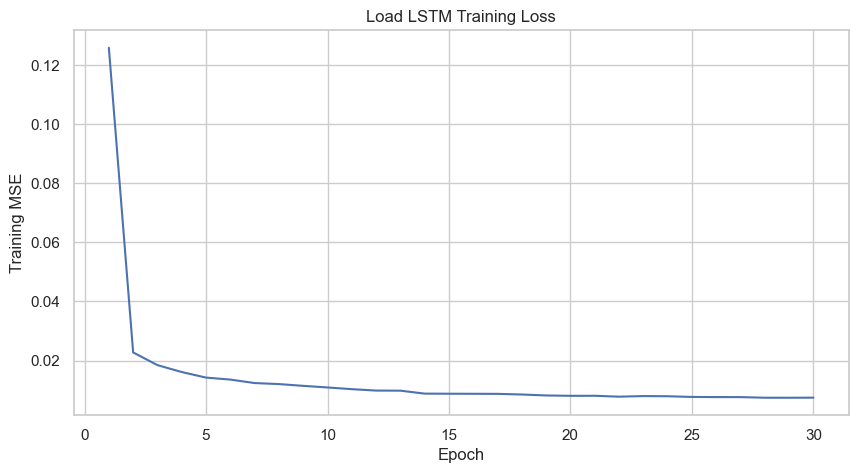

In [ ]:
# ============================================================
# STEP 10.7 — PLOT TRAINING LOSS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(load_history) + 1),
    load_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load LSTM Training Loss")

plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# STEP 11 — GENERATE LOAD TEST PREDICTIONS
# ============================================================

def predict_model(model, data_loader, device):

    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)

            output = model(X_batch)

            predictions.extend(
                output.cpu().numpy()
            )

            actuals.extend(
                y_batch.numpy()
            )

    return np.array(predictions), np.array(actuals)


# Generate predictions
load_predictions_scaled, load_actual_scaled = predict_model(
    load_model,
    load_test_loader,
    device
)


print("Prediction shape:", load_predictions_scaled.shape)
print("Actual shape    :", load_actual_scaled.shape)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# ============================================================
# STEP 11.1 — INVERSE TRANSFORM PREDICTIONS
# ============================================================

load_predictions = load_y_scaler.inverse_transform(
    load_predictions_scaled.reshape(-1, 1)
).flatten()

load_actual = load_y_scaler.inverse_transform(
    load_actual_scaled.reshape(-1, 1)
).flatten()


print("Prediction range:")
print(
    load_predictions.min(),
    "to",
    load_predictions.max(),
    "MW"
)

print("\nActual range:")
print(
    load_actual.min(),
    "to",
    load_actual.max(),
    "MW"
)

Prediction range:
37281.81 to 83840.91 MW

Actual range:
38617.902 to 83876.46 MW


In [ ]:
# ============================================================
# STEP 11.2 — LOAD TEST METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

load_mae = mean_absolute_error(
    load_actual,
    load_predictions
)

load_rmse = np.sqrt(
    mean_squared_error(
        load_actual,
        load_predictions
    )
)

load_r2 = r2_score(
    load_actual,
    load_predictions
)


print("=" * 50)
print("LOAD LSTM — 2025 TEST RESULTS")
print("=" * 50)

print(f"MAE  : {load_mae:.4f} MW")
print(f"RMSE : {load_rmse:.4f} MW")
print(f"R²   : {load_r2:.4f}")

LOAD LSTM — 2025 TEST RESULTS
MAE  : 619.3125 MW
RMSE : 814.2667 MW
R²   : 0.9935


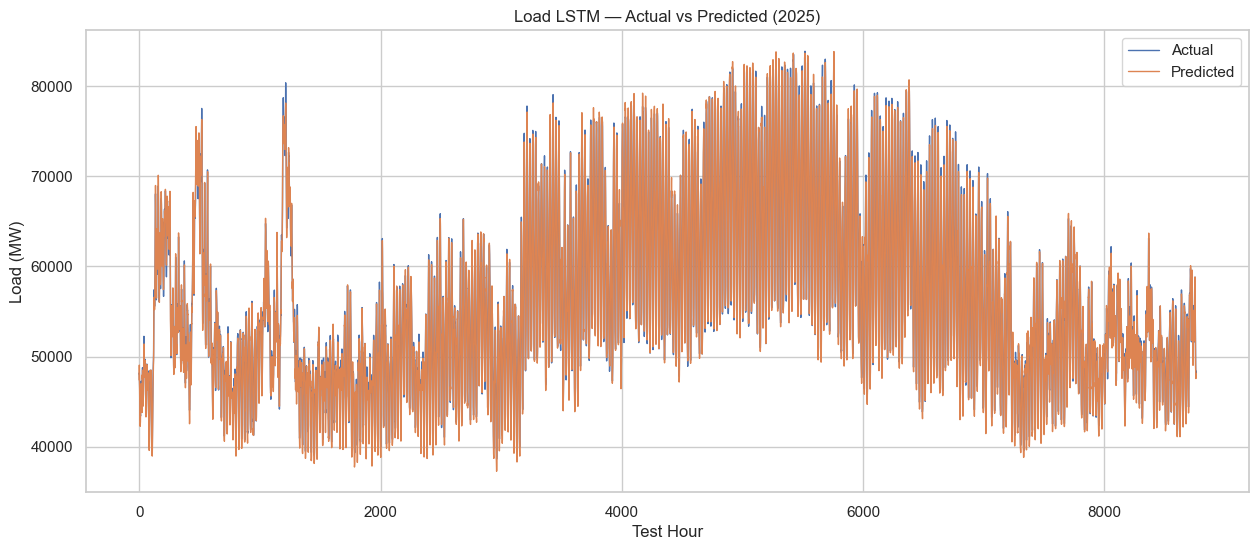

In [ ]:
# ============================================================
# STEP 12 — ACTUAL VS PREDICTED LOAD
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual,
    label="Actual",
    linewidth=1
)

plt.plot(
    load_predictions,
    label="Predicted",
    linewidth=1
)

plt.xlabel("Test Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — Actual vs Predicted (2025)")
plt.legend()
plt.grid(True)

plt.show()

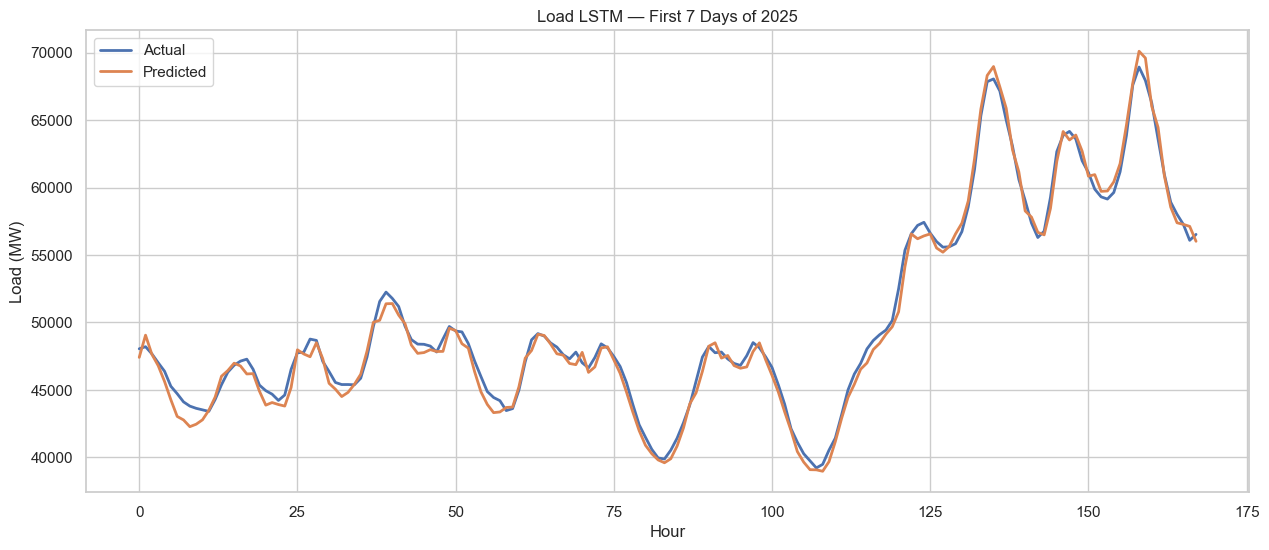

In [ ]:
# ============================================================
# STEP 12.1 — FIRST 7 DAYS
# ============================================================

hours_to_plot = 24 * 7

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual[:hours_to_plot],
    label="Actual",
    linewidth=2
)

plt.plot(
    load_predictions[:hours_to_plot],
    label="Predicted",
    linewidth=2
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — First 7 Days of 2025")
plt.legend()
plt.grid(True)

plt.show()

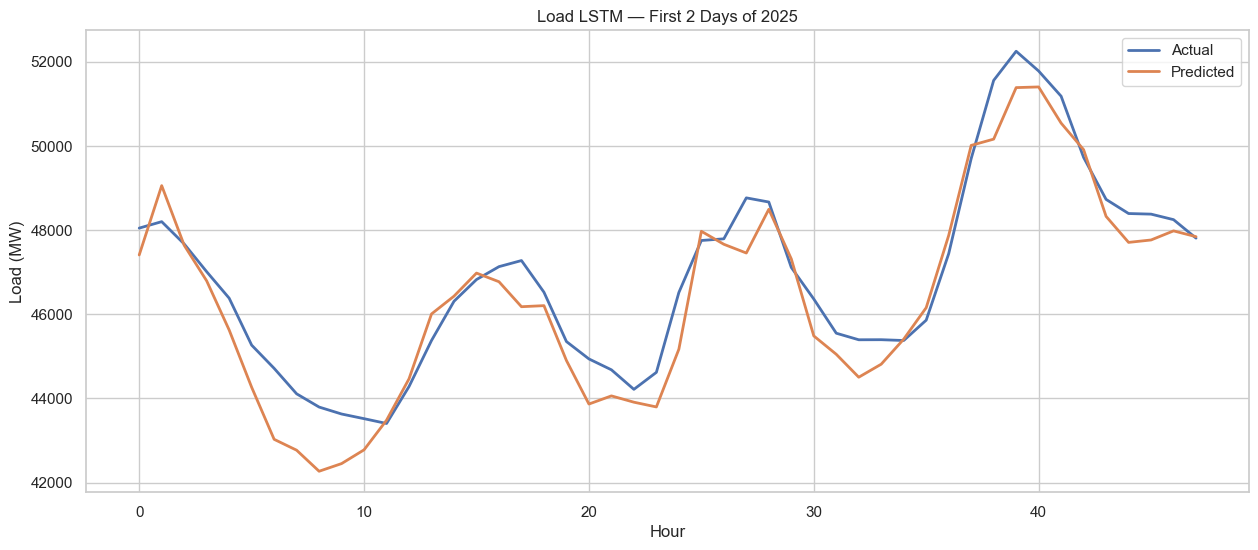

In [ ]:
# ============================================================
# STEP 12.2 — FIRST 2 DAYS OF 2025
# ============================================================

hours_to_plot = 24 * 2

plt.figure(figsize=(15, 6))

plt.plot(
    load_actual[:hours_to_plot],
    label="Actual",
    linewidth=2
)

plt.plot(
    load_predictions[:hours_to_plot],
    label="Predicted",
    linewidth=2
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load LSTM — First 2 Days of 2025")
plt.legend()
plt.grid(True)

plt.show()

# 6 hour forecasting

In [ ]:
# ============================================================
# 6-HOUR DIRECT MULTI-OUTPUT LOAD FORECASTING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

PyTorch version: 2.11.0+cpu
Device: cpu


In [ ]:
# ============================================================
# LOAD FEATURES — SAME AS BASELINE
# ============================================================

load_features = [
    "Load_MW",
    "RH2M",
    "IsWeekend",
    "IsHoliday",
    "T2M",
    "CLOUD_AMT",
    "WS10M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos"
]

load_target = "Load_MW"

print("Number of input features:", len(load_features))
print(load_features)

Number of input features: 13
['Load_MW', 'RH2M', 'IsWeekend', 'IsHoliday', 'T2M', 'CLOUD_AMT', 'WS10M', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos']


In [ ]:
# ============================================================
# 2-YEAR TRAIN / 1-YEAR TEST SPLIT
# SAME AS BASELINE
# ============================================================

train_end = pd.Timestamp(
    "2024-12-31 23:00:00+00:00"
)

test_start = pd.Timestamp(
    "2025-01-01 00:00:00+00:00"
)

load_train = load_df[
    load_df["Datetime_UTC"] <= train_end
].copy()

load_test = load_df[
    load_df["Datetime_UTC"] >= test_start
].copy()

print("Training shape:", load_train.shape)
print("Testing shape :", load_test.shape)

print("\nTraining period:")
print(load_train["Datetime_UTC"].min())
print(load_train["Datetime_UTC"].max())

print("\nTesting period:")
print(load_test["Datetime_UTC"].min())
print(load_test["Datetime_UTC"].max())

Training shape: (17537, 21)
Testing shape : (8760, 21)

Training period:
2023-01-01 07:00:00+00:00
2024-12-31 23:00:00+00:00

Testing period:
2025-01-01 00:00:00+00:00
2025-12-31 23:00:00+00:00


In [ ]:
# ============================================================
# PREPARE TRAINING AND TESTING DATA
# ============================================================

X_train_raw = load_train[load_features].values
y_train_raw = load_train[[load_target]].values

X_test_raw = load_test[load_features].values
y_test_raw = load_test[[load_target]].values

print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)

print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

X_train: (17537, 13)
y_train: (17537, 1)
X_test : (8760, 13)
y_test : (8760, 1)


In [ ]:
# ============================================================
# SCALING
# ============================================================

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(
    X_train_raw
)

y_train_scaled = y_scaler.fit_transform(
    y_train_raw
)

X_test_scaled = X_scaler.transform(
    X_test_raw
)

y_test_scaled = y_scaler.transform(
    y_test_raw
)

print("Scaling completed.")

Scaling completed.


In [ ]:
# ============================================================
# MULTI-OUTPUT SEQUENCE CREATION
# ============================================================

LOOKBACK = 168
FORECAST_HORIZON = 6


def create_multi_output_sequences(
    X,
    y,
    lookback,
    horizon
):

    X_sequences = []
    y_sequences = []

    # We need enough data for:
    # lookback historical observations
    # +
    # horizon future observations

    for i in range(
        len(X) - lookback - horizon + 1
    ):

        X_seq = X[
            i : i + lookback
        ]

        y_seq = y[
            i + lookback :
            i + lookback + horizon
        ]

        X_sequences.append(
            X_seq
        )

        y_sequences.append(
            y_seq.flatten()
        )

    return (
        np.array(X_sequences),
        np.array(y_sequences)
    )

In [ ]:
# ============================================================
# TRAINING SEQUENCES
# ============================================================

X_train_seq, y_train_seq = create_multi_output_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK,
    FORECAST_HORIZON
)

print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

X_train_seq shape: (17364, 168, 13)
y_train_seq shape: (17364, 6)


In [ ]:
# ============================================================
# TEST SEQUENCES
#
# Include the final 168 hours of training data as historical
# context for the beginning of the 2025 test period.
# ============================================================

X_test_context = np.vstack([
    X_train_scaled[-LOOKBACK:],
    X_test_scaled
])

y_test_context = np.vstack([
    y_train_scaled[-LOOKBACK:],
    y_test_scaled
])

print(
    "Test context shape:",
    X_test_context.shape
)

Test context shape: (8928, 13)


In [ ]:
# ============================================================
# CREATE TEST SEQUENCES
# ============================================================

X_test_seq = []
y_test_seq = []

for i in range(
    len(X_test_scaled) - FORECAST_HORIZON + 1
):

    # Historical sequence ending at test time i
    X_seq = X_test_context[
        i : i + LOOKBACK
    ]

    # Future six-hour target
    # Starts from the corresponding test position
    target_start = LOOKBACK + i

    y_seq = y_test_context[
        target_start :
        target_start + FORECAST_HORIZON
    ]

    X_test_seq.append(X_seq)
    y_test_seq.append(y_seq.flatten())

X_test_seq = np.array(X_test_seq)
y_test_seq = np.array(y_test_seq)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

X_test_seq shape: (8755, 168, 13)
y_test_seq shape: (8755, 6)


In [ ]:
# ============================================================
# SHAPE VERIFICATION
# ============================================================

print("\n==============================")
print("SEQUENCE SHAPES")
print("==============================")

print(
    "Training X:",
    X_train_seq.shape
)

print(
    "Training y:",
    y_train_seq.shape
)

print(
    "Testing X :",
    X_test_seq.shape
)

print(
    "Testing y :",
    y_test_seq.shape
)

assert X_train_seq.shape[1] == 168
assert X_train_seq.shape[2] == 13

assert y_train_seq.shape[1] == 6
assert y_test_seq.shape[1] == 6

print("\nAll shape checks passed.")


SEQUENCE SHAPES
Training X: (17364, 168, 13)
Training y: (17364, 6)
Testing X : (8755, 168, 13)
Testing y : (8755, 6)

All shape checks passed.


In [ ]:
# ============================================================
# CONVERT TO PYTORCH TENSORS
# ============================================================

X_train_tensor = torch.tensor(
    X_train_seq,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_seq,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_seq,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_seq,
    dtype=torch.float32
)

print("Tensor shapes:")
print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

Tensor shapes:
X_train: torch.Size([17364, 168, 13])
y_train: torch.Size([17364, 6])
X_test : torch.Size([8755, 168, 13])
y_test : torch.Size([8755, 6])


In [ ]:
# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 64

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches :", len(test_loader))

Training batches: 272
Testing batches : 137


In [ ]:
# ============================================================
# 6-HOUR MULTI-OUTPUT LSTM
# ============================================================

class LSTMForecaster6H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        output_size=6
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        # x:
        # [batch, 168, 13]

        output, (hidden, cell) = self.lstm(x)

        # Last timestep
        last_output = output[:, -1, :]

        last_output = self.dropout(
            last_output
        )

        # [batch, 6]
        prediction = self.fc(
            last_output
        )

        return prediction

In [ ]:
# ============================================================
# CREATE MODEL
# ============================================================

load_input_size = len(load_features)

load_model_6h = LSTMForecaster6H(
    input_size=load_input_size,
    hidden_size=64,
    num_layers=2,
    dropout=0.2,
    output_size=6
)

load_model_6h = load_model_6h.to(device)

print(load_model_6h)

LSTMForecaster6H(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [ ]:
# ============================================================
# MODEL PARAMETERS
# ============================================================

total_parameters = sum(
    p.numel()
    for p in load_model_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    total_parameters
)

Trainable parameters: 53894


In [ ]:
# ============================================================
# LOSS FUNCTION AND OPTIMIZER
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    load_model_6h.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_model_multi_output(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs,
    device
):

    model.train()

    history = []

    for epoch in range(epochs):

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(
                X_batch
            )

            # predictions:
            # [batch, 6]

            # y_batch:
            # [batch, 6]

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

        epoch_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        history.append(
            epoch_loss
        )

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.6f}"
        )

    return history

In [ ]:
# ============================================================
# TRAIN 6-HOUR MODEL
# ============================================================

EPOCHS = 20

history_6h = train_model_multi_output(
    model=load_model_6h,
    train_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.064166
Epoch [2/20] Loss: 0.037849
Epoch [3/20] Loss: 0.031259
Epoch [4/20] Loss: 0.027823
Epoch [5/20] Loss: 0.025469
Epoch [6/20] Loss: 0.024779
Epoch [7/20] Loss: 0.023075
Epoch [8/20] Loss: 0.022014
Epoch [9/20] Loss: 0.021649
Epoch [10/20] Loss: 0.020848
Epoch [11/20] Loss: 0.020433
Epoch [12/20] Loss: 0.020390
Epoch [13/20] Loss: 0.019796
Epoch [14/20] Loss: 0.019034
Epoch [15/20] Loss: 0.018803
Epoch [16/20] Loss: 0.018550
Epoch [17/20] Loss: 0.018070
Epoch [18/20] Loss: 0.018426
Epoch [19/20] Loss: 0.017513
Epoch [20/20] Loss: 0.017395


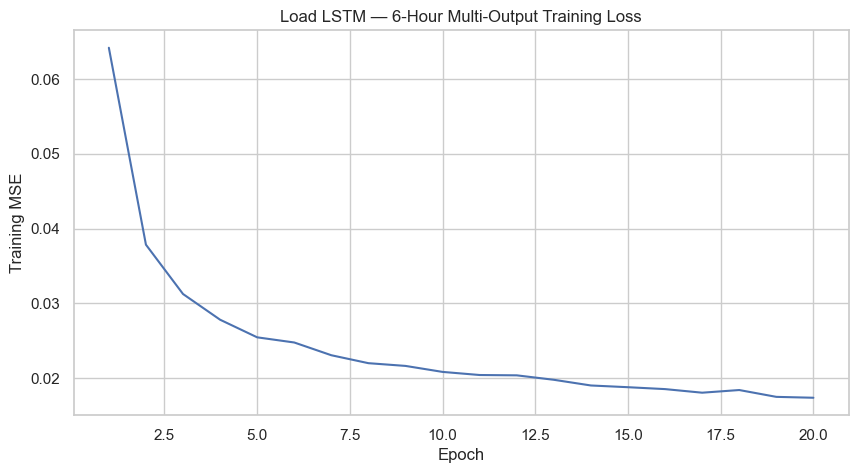

In [ ]:
# ============================================================
# TRAINING LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    history_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title(
    "Load LSTM — 6-Hour Multi-Output Training Loss"
)

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# GENERATE PREDICTIONS
# ============================================================

load_model_6h.eval()

predictions_scaled = []
actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = load_model_6h(
            X_batch
        )

        predictions_scaled.append(
            predictions.cpu().numpy()
        )

        actual_scaled.append(
            y_batch.numpy()
        )

predictions_scaled = np.vstack(
    predictions_scaled
)

actual_scaled = np.vstack(
    actual_scaled
)

print(
    "Predictions shape:",
    predictions_scaled.shape
)

print(
    "Actual shape:",
    actual_scaled.shape
)

Predictions shape: (8755, 6)
Actual shape: (8755, 6)


In [ ]:
# ============================================================
# INVERSE SCALING
# ============================================================

predictions_original = y_scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(
    predictions_scaled.shape
)

actual_original = y_scaler.inverse_transform(
    actual_scaled.reshape(-1, 1)
).reshape(
    actual_scaled.shape
)

print(
    "Prediction range:",
    predictions_original.min(),
    "to",
    predictions_original.max(),
    "MW"
)

print(
    "Actual range:",
    actual_original.min(),
    "to",
    actual_original.max(),
    "MW"
)

Prediction range: 36681.594 to 83535.9 MW
Actual range: 38617.902 to 83876.46 MW


In [ ]:
# ============================================================
# METRICS FOR EACH FORECAST HORIZON
# ============================================================

results = []

for h in range(FORECAST_HORIZON):

    actual_h = actual_original[:, h]
    pred_h = predictions_original[:, h]

    mae = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2 = r2_score(
        actual_h,
        pred_h
    )

    results.append({
        "Horizon": f"t+{h+1}",
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(
    results
)

results_df

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1002.326233,1300.223298,0.983493
1,t+2,1150.808228,1504.888617,0.977887
2,t+3,1286.762817,1689.112415,0.972141
3,t+4,1416.933350,1858.856436,0.966260
4,t+5,1538.448242,2013.275316,0.960421
5,t+6,1655.123413,2170.362182,0.954002


In [ ]:
# ============================================================
# OVERALL 6-HOUR PERFORMANCE
# ============================================================

overall_actual = actual_original.flatten()
overall_pred = predictions_original.flatten()

overall_mae = mean_absolute_error(
    overall_actual,
    overall_pred
)

overall_rmse = np.sqrt(
    mean_squared_error(
        overall_actual,
        overall_pred
    )
)

overall_r2 = r2_score(
    overall_actual,
    overall_pred
)

print("=" * 55)
print("LOAD LSTM — 6-HOUR DIRECT MULTI-OUTPUT RESULTS")
print("=" * 55)

print(
    f"Overall MAE  : {overall_mae:.4f} MW"
)

print(
    f"Overall RMSE : {overall_rmse:.4f} MW"
)

print(
    f"Overall R²   : {overall_r2:.4f}"
)

LOAD LSTM — 6-HOUR DIRECT MULTI-OUTPUT RESULTS
Overall MAE  : 1341.7338 MW
Overall RMSE : 1780.7989 MW
Overall R²   : 0.9690


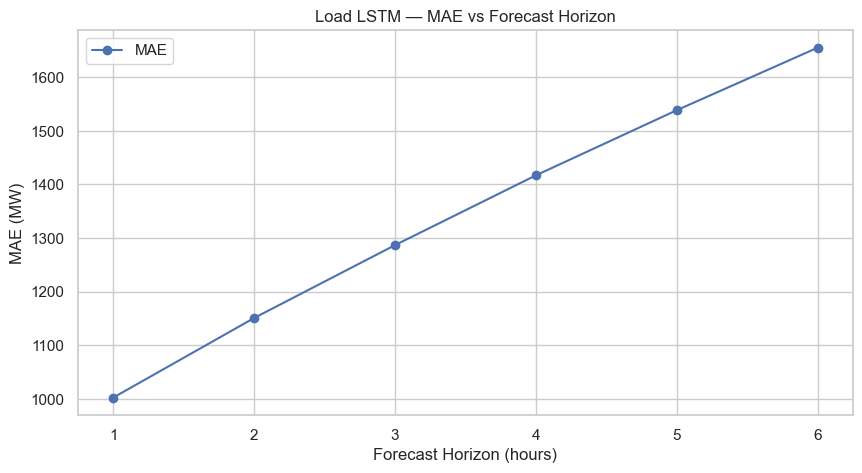

In [ ]:
# ============================================================
# ERROR VS FORECAST HORIZON
# ============================================================

horizons = np.arange(
    1,
    FORECAST_HORIZON + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["MAE_MW"],
    marker="o",
    label="MAE"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("MAE (MW)")
plt.title(
    "Load LSTM — MAE vs Forecast Horizon"
)

plt.xticks(horizons)
plt.grid(True)
plt.legend()

plt.show()

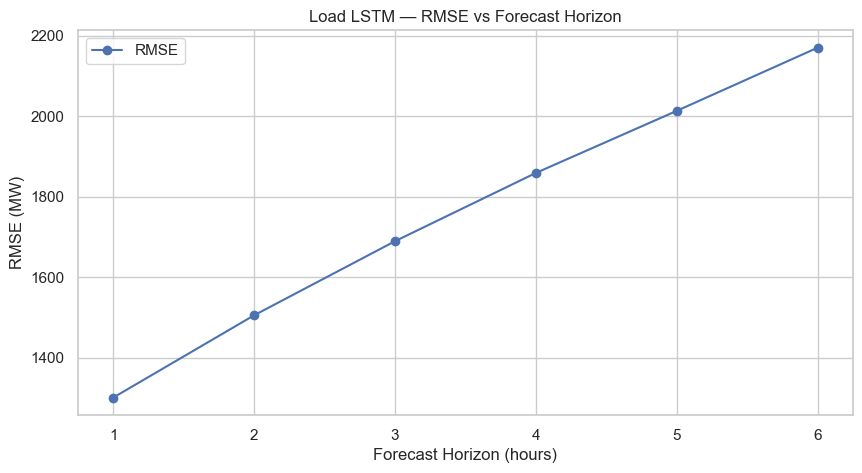

In [ ]:
# ============================================================
# RMSE VS FORECAST HORIZON
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["RMSE_MW"],
    marker="o",
    label="RMSE"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("RMSE (MW)")
plt.title(
    "Load LSTM — RMSE vs Forecast Horizon"
)

plt.xticks(horizons)
plt.grid(True)
plt.legend()

plt.show()

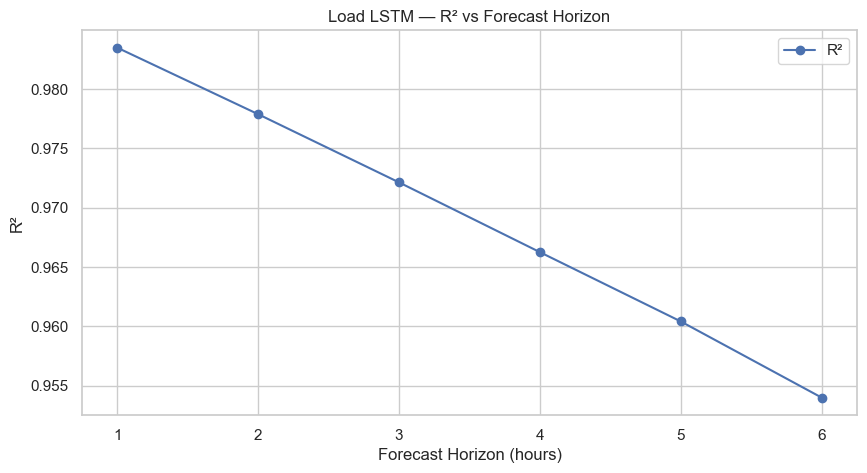

In [ ]:
# ============================================================
# R² VS FORECAST HORIZON
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["R2"],
    marker="o",
    label="R²"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("R²")
plt.title(
    "Load LSTM — R² vs Forecast Horizon"
)

plt.xticks(horizons)
plt.grid(True)
plt.legend()

plt.show()

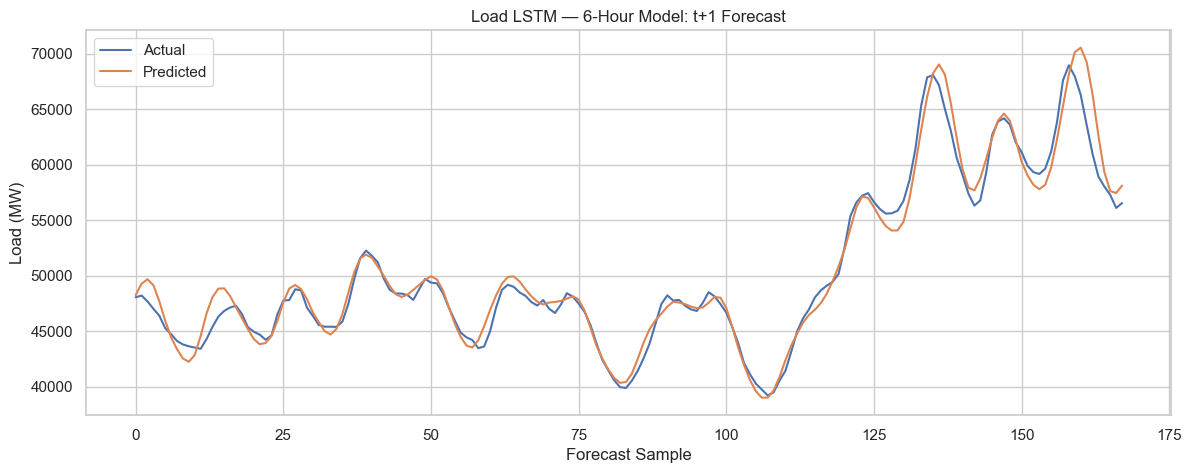

In [ ]:
# ============================================================
# T+1 ACTUAL VS PREDICTED
# ============================================================

N = 168

plt.figure(figsize=(14, 5))

plt.plot(
    actual_original[:N, 0],
    label="Actual"
)

plt.plot(
    predictions_original[:N, 0],
    label="Predicted"
)

plt.xlabel("Forecast Sample")
plt.ylabel("Load (MW)")

plt.title(
    "Load LSTM — 6-Hour Model: t+1 Forecast"
)

plt.legend()
plt.grid(True)

plt.show()

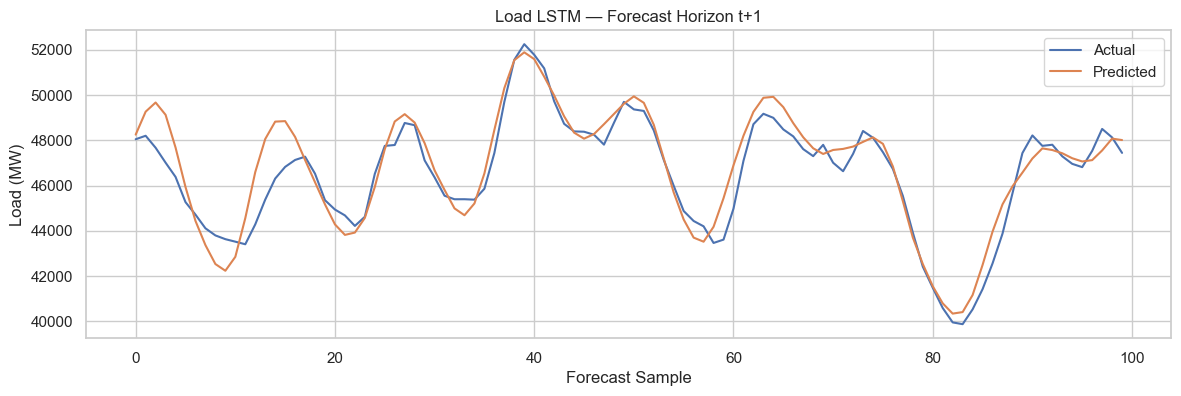

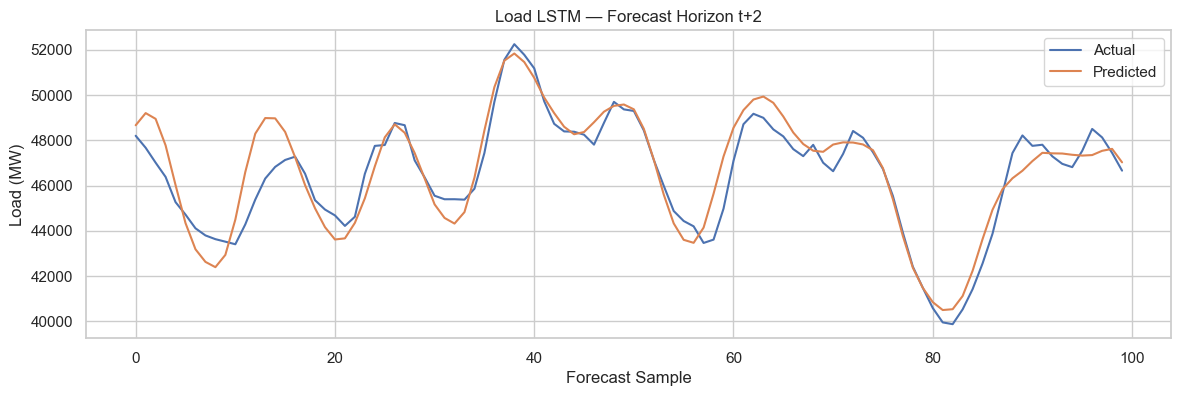

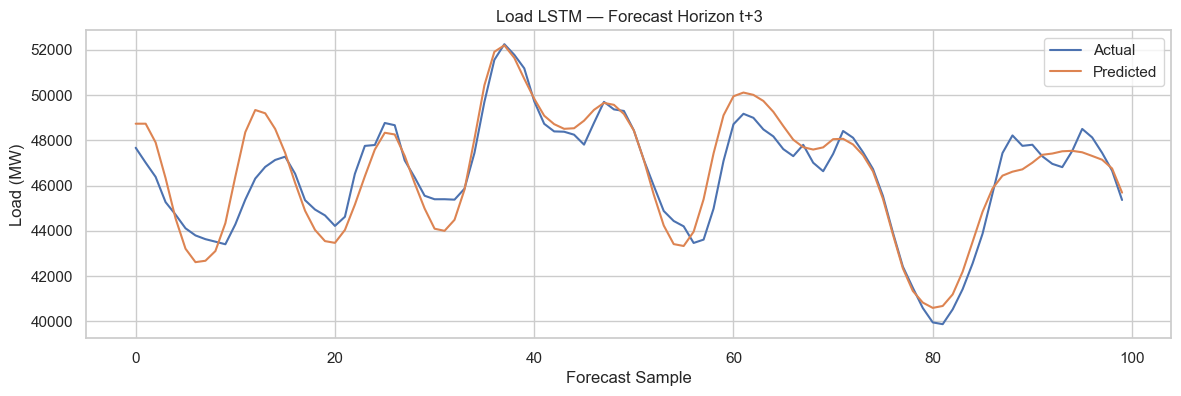

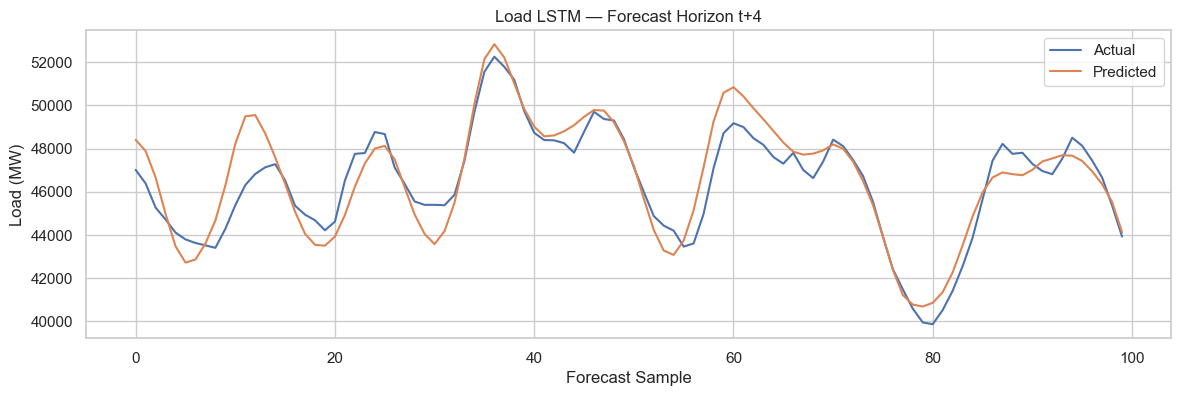

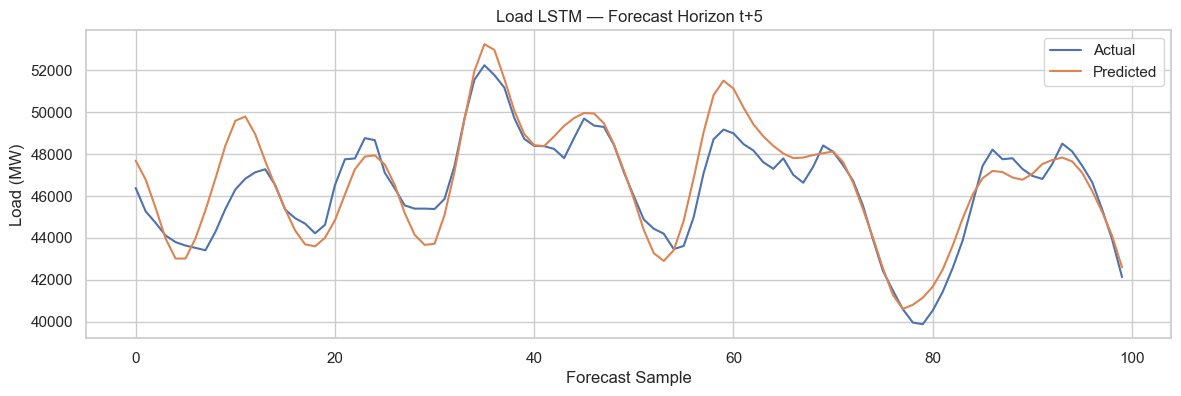

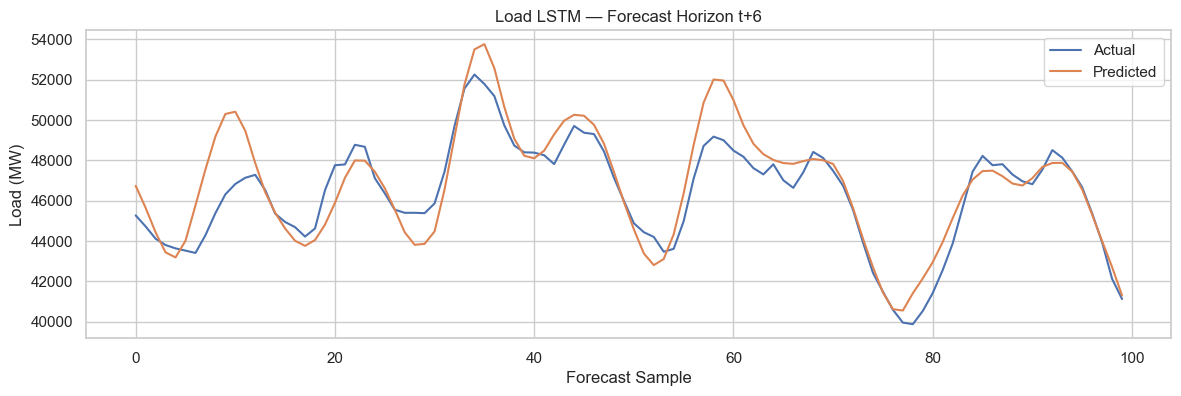

In [ ]:
# ============================================================
# ACTUAL VS PREDICTED FOR ALL 6 HORIZONS
# ============================================================

N = 100

for h in range(FORECAST_HORIZON):

    plt.figure(figsize=(14, 4))

    plt.plot(
        actual_original[:N, h],
        label="Actual"
    )

    plt.plot(
        predictions_original[:N, h],
        label="Predicted"
    )

    plt.xlabel("Forecast Sample")
    plt.ylabel("Load (MW)")

    plt.title(
        f"Load LSTM — Forecast Horizon t+{h+1}"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

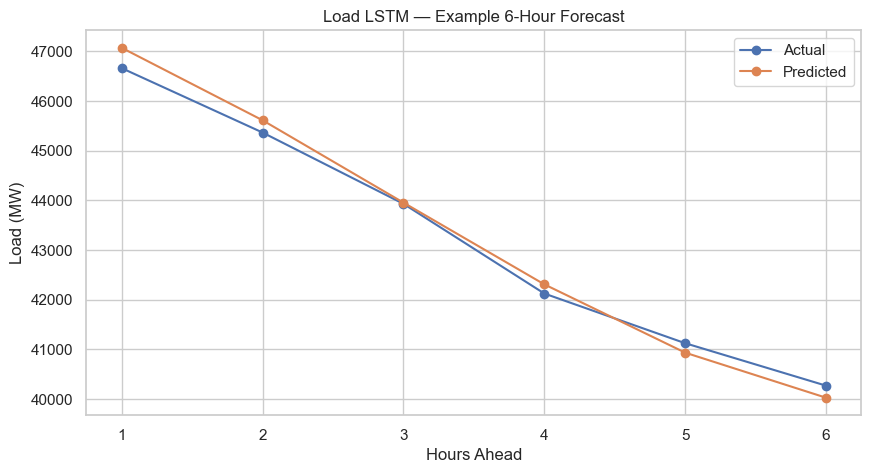

In [ ]:
# ============================================================
# SINGLE 6-HOUR FORECAST EXAMPLE
# ============================================================

sample_index = 100

actual_6h = actual_original[
    sample_index
]

predicted_6h = predictions_original[
    sample_index
]

hours_ahead = np.arange(
    1,
    FORECAST_HORIZON + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    hours_ahead,
    actual_6h,
    marker="o",
    label="Actual"
)

plt.plot(
    hours_ahead,
    predicted_6h,
    marker="o",
    label="Predicted"
)

plt.xlabel("Hours Ahead")
plt.ylabel("Load (MW)")

plt.title(
    "Load LSTM — Example 6-Hour Forecast"
)

plt.xticks(hours_ahead)

plt.grid(True)
plt.legend()

plt.show()

# CNN-LSTM Hybrid

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Check the existing 1-hour forecasting pipeline

print("Features:", load_features)
print("Number of features:", len(load_features))

X_batch, y_batch = next(iter(load_train_loader))

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Device      :", device)

Features: ['Load_MW', 'RH2M', 'IsWeekend', 'IsHoliday', 'T2M', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'CLOUD_AMT', 'WS10M']
Number of features: 13
Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Device      : cpu


In [ ]:
# Define the 1-hour CNN-LSTM model

class CNNLSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_channels=32,
        kernel_size=3,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.cnn = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_channels,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.relu = nn.ReLU()

        self.lstm = nn.LSTM(
            input_size=cnn_channels,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        x = x.transpose(1, 2)

        x = self.cnn(x)

        x = self.relu(x)

        x = x.transpose(1, 2)

        output, (hidden, cell) = self.lstm(x)

        last_output = output[:, -1, :]

        last_output = self.dropout(last_output)

        prediction = self.fc(last_output)

        return prediction.squeeze(1)

In [ ]:
# Create the CNN-LSTM model

cnn_load_model = CNNLSTMForecaster(
    input_size=len(load_features),
    cnn_channels=32,
    kernel_size=3,
    hidden_size=64,
    num_layers=2,
    dropout=0.2
)

cnn_load_model = cnn_load_model.to(device)

print(cnn_load_model)

CNNLSTMForecaster(
  (cnn): Conv1d(13, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# Count trainable parameters

cnn_parameters = sum(
    p.numel()
    for p in cnn_load_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", cnn_parameters)

Trainable parameters: 59713


In [ ]:
# Test the CNN-LSTM forward pass

X_batch, y_batch = next(
    iter(load_train_loader)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    cnn_output = cnn_load_model(X_batch)

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Output shape:", cnn_output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [ ]:
# Define CNN-LSTM loss and optimizer

cnn_load_criterion = nn.MSELoss()

cnn_load_optimizer = torch.optim.Adam(
    cnn_load_model.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
# Define the CNN-LSTM training function

def train_cnn_lstm(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs,
    device
):

    history = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

        epoch_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        history.append(epoch_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.6f}"
        )

    return history

In [ ]:
# Train the CNN-LSTM

CNN_LSTM_EPOCHS = 20

cnn_load_history = train_cnn_lstm(
    model=cnn_load_model,
    train_loader=load_train_loader,
    criterion=cnn_load_criterion,
    optimizer=cnn_load_optimizer,
    epochs=CNN_LSTM_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.105757
Epoch [2/20] Loss: 0.020216
Epoch [3/20] Loss: 0.015119
Epoch [4/20] Loss: 0.013277
Epoch [5/20] Loss: 0.011912
Epoch [6/20] Loss: 0.011816
Epoch [7/20] Loss: 0.010186
Epoch [8/20] Loss: 0.010653
Epoch [9/20] Loss: 0.010395
Epoch [10/20] Loss: 0.009508
Epoch [11/20] Loss: 0.009884
Epoch [12/20] Loss: 0.009351
Epoch [13/20] Loss: 0.008996
Epoch [14/20] Loss: 0.008670
Epoch [15/20] Loss: 0.008725
Epoch [16/20] Loss: 0.008378
Epoch [17/20] Loss: 0.008622
Epoch [18/20] Loss: 0.008666
Epoch [19/20] Loss: 0.008419
Epoch [20/20] Loss: 0.007956


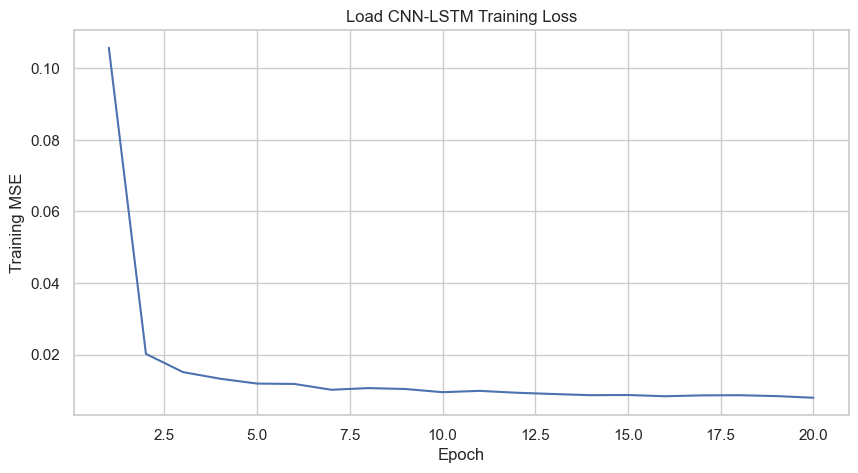

In [ ]:
# Plot CNN-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, CNN_LSTM_EPOCHS + 1),
    cnn_load_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load CNN-LSTM Training Loss")

plt.grid(True)
plt.show()

In [ ]:
# Generate CNN-LSTM test predictions

cnn_load_model.eval()

cnn_load_predictions_scaled = []
cnn_load_actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in load_test_loader:

        X_batch = X_batch.to(device)

        predictions = cnn_load_model(
            X_batch
        )

        cnn_load_predictions_scaled.extend(
            predictions.cpu().numpy()
        )

        cnn_load_actual_scaled.extend(
            y_batch.numpy()
        )

cnn_load_predictions_scaled = np.array(
    cnn_load_predictions_scaled
)

cnn_load_actual_scaled = np.array(
    cnn_load_actual_scaled
)

print(
    "Prediction shape:",
    cnn_load_predictions_scaled.shape
)

print(
    "Actual shape    :",
    cnn_load_actual_scaled.shape
)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# Convert CNN-LSTM predictions back to MW

cnn_load_predictions = load_y_scaler.inverse_transform(
    cnn_load_predictions_scaled.reshape(-1, 1)
).flatten()

cnn_load_actual = load_y_scaler.inverse_transform(
    cnn_load_actual_scaled.reshape(-1, 1)
).flatten()

print(
    "Prediction range:",
    cnn_load_predictions.min(),
    cnn_load_predictions.max()
)

print(
    "Actual range:",
    cnn_load_actual.min(),
    cnn_load_actual.max()
)

Prediction range: 37763.004 82748.56
Actual range: 38617.902 83876.46


In [ ]:
# Calculate CNN-LSTM test metrics

cnn_load_mae = mean_absolute_error(
    cnn_load_actual,
    cnn_load_predictions
)

cnn_load_rmse = np.sqrt(
    mean_squared_error(
        cnn_load_actual,
        cnn_load_predictions
    )
)

cnn_load_r2 = r2_score(
    cnn_load_actual,
    cnn_load_predictions
)


print("LOAD CNN-LSTM — 2025 TEST RESULTS")


print(f"MAE  : {cnn_load_mae:.4f} MW")
print(f"RMSE : {cnn_load_rmse:.4f} MW")
print(f"R²   : {cnn_load_r2:.4f}")

LOAD CNN-LSTM — 2025 TEST RESULTS
MAE  : 753.2708 MW
RMSE : 992.0685 MW
R²   : 0.9904


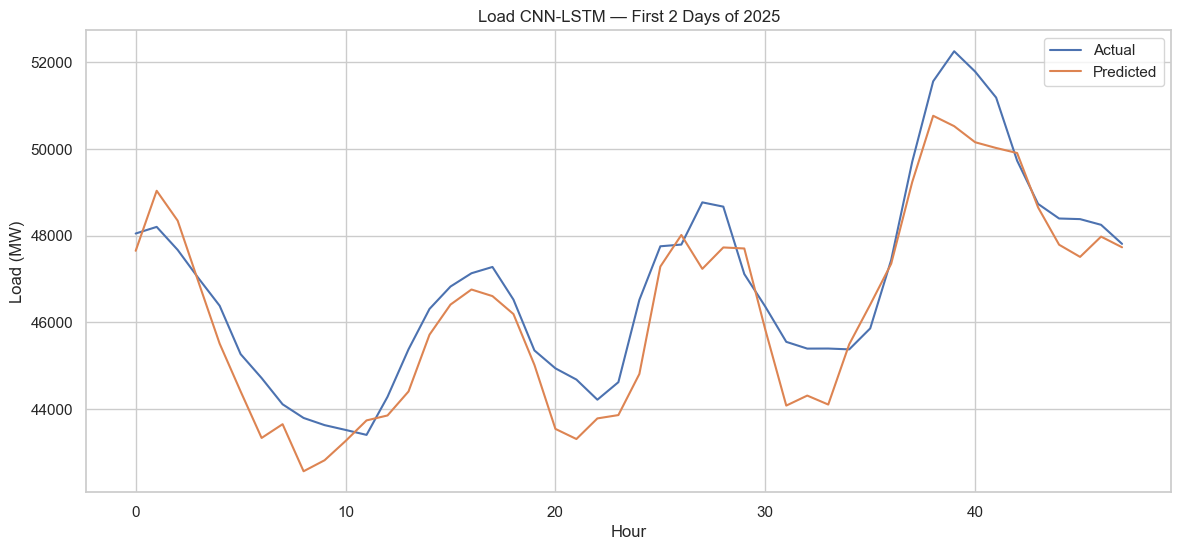

In [ ]:
# Plot the first two days of CNN-LSTM predictions

hours = 48

plt.figure(figsize=(14, 6))

plt.plot(
    cnn_load_actual[:hours],
    label="Actual"
)

plt.plot(
    cnn_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load CNN-LSTM — First 2 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

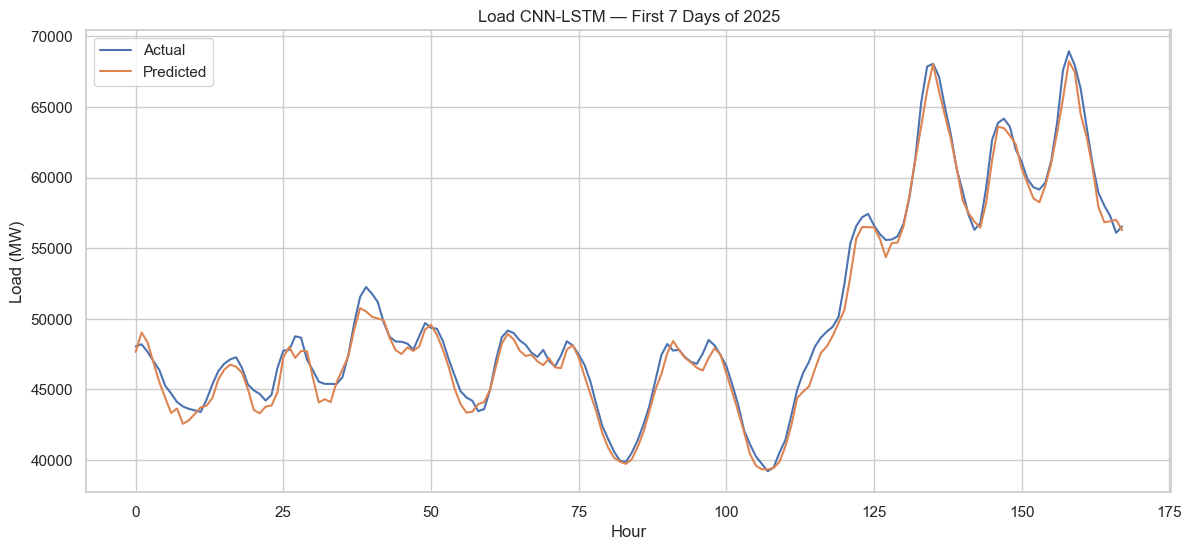

In [ ]:
# Plot the first seven days of CNN-LSTM predictions

hours = 168

plt.figure(figsize=(14, 6))

plt.plot(
    cnn_load_actual[:hours],
    label="Actual"
)

plt.plot(
    cnn_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load CNN-LSTM — First 7 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

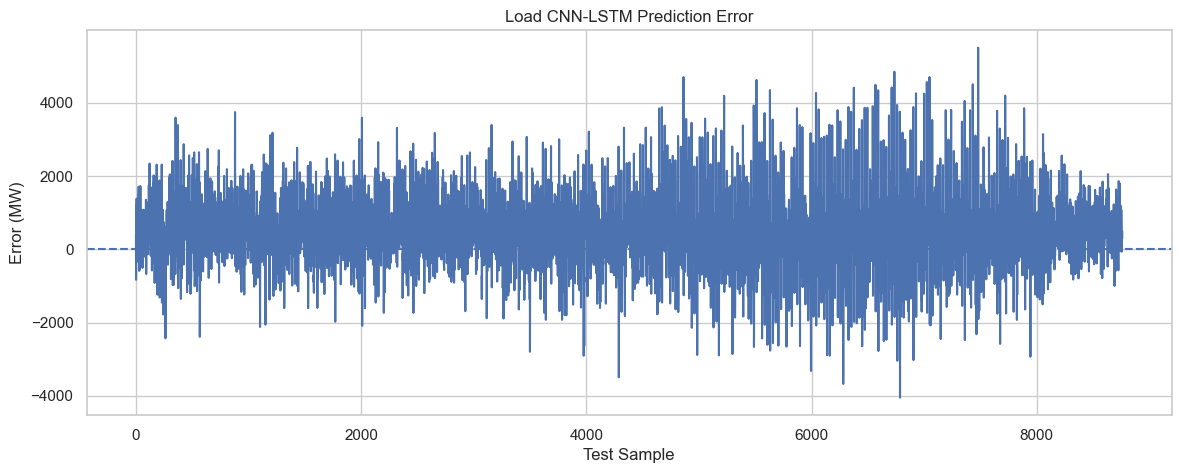

In [ ]:
# Plot CNN-LSTM prediction error

cnn_load_error = (
    cnn_load_actual -
    cnn_load_predictions
)

plt.figure(figsize=(14, 5))

plt.plot(
    cnn_load_error
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Test Sample")
plt.ylabel("Error (MW)")
plt.title("Load CNN-LSTM Prediction Error")

plt.grid(True)
plt.show()

In [ ]:
# Compare CNN-LSTM with the baseline LSTM

load_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "CNN-LSTM"
    ],
    "MAE_MW": [
        619.3125,
        cnn_load_mae
    ],
    "RMSE_MW": [
        814.2667,
        cnn_load_rmse
    ],
    "R2": [
        0.9935,
        cnn_load_r2
    ]
})

load_model_comparison

,Model,MAE_MW,RMSE_MW,R2
0,Baseline LSTM,619.312500,814.266700,0.993500
1,CNN-LSTM,753.270752,992.068515,0.990388


In [ ]:
# Calculate CNN-LSTM improvement over LSTM

mae_improvement = (
    (619.3125 - cnn_load_mae)
    / 619.3125
) * 100

rmse_improvement = (
    (814.2667 - cnn_load_rmse)
    / 814.2667
) * 100

r2_improvement = (
    (cnn_load_r2 - 0.9935)
    / 0.9935
) * 100

print(f"MAE improvement : {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(f"R² improvement  : {r2_improvement:.2f}%")


MAE improvement : -21.63%
RMSE improvement: -21.84%
R² improvement  : -0.31%


# LSTM-Attention

In [ ]:
# Define the 1-hour Attention-LSTM model

class AttentionLSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.attention = nn.Linear(
            hidden_size,
            1
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        attention_scores = self.attention(output)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context = torch.sum(
            attention_weights * output,
            dim=1
        )

        context = self.dropout(context)

        prediction = self.fc(context)

        return prediction.squeeze(1)

In [ ]:
# Create the Attention-LSTM model

attention_load_model = AttentionLSTMForecaster(
    input_size=len(load_features),
    hidden_size=64,
    num_layers=2,
    dropout=0.2
)

attention_load_model = attention_load_model.to(device)

print(attention_load_model)

AttentionLSTMForecaster(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): Linear(in_features=64, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# Count trainable parameters

attention_parameters = sum(
    p.numel()
    for p in attention_load_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", attention_parameters)

Trainable parameters: 53634


In [ ]:
# Test the Attention-LSTM forward pass

X_batch, y_batch = next(
    iter(load_train_loader)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    attention_output = attention_load_model(
        X_batch
    )

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Output shape:", attention_output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [ ]:
# Define Attention-LSTM loss and optimizer

attention_load_criterion = nn.MSELoss()

attention_load_optimizer = torch.optim.Adam(
    attention_load_model.parameters(),
    lr=0.001
)

In [ ]:
# Train the Attention-LSTM

ATTENTION_EPOCHS = 20

attention_load_history = train_cnn_lstm(
    model=attention_load_model,
    train_loader=load_train_loader,
    criterion=attention_load_criterion,
    optimizer=attention_load_optimizer,
    epochs=ATTENTION_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.364947
Epoch [2/20] Loss: 0.131019
Epoch [3/20] Loss: 0.105999
Epoch [4/20] Loss: 0.094844
Epoch [5/20] Loss: 0.083868
Epoch [6/20] Loss: 0.075503
Epoch [7/20] Loss: 0.065459
Epoch [8/20] Loss: 0.060119
Epoch [9/20] Loss: 0.056882
Epoch [10/20] Loss: 0.051929
Epoch [11/20] Loss: 0.050255
Epoch [12/20] Loss: 0.051894
Epoch [13/20] Loss: 0.046603
Epoch [14/20] Loss: 0.041105
Epoch [15/20] Loss: 0.041412
Epoch [16/20] Loss: 0.038729
Epoch [17/20] Loss: 0.036325
Epoch [18/20] Loss: 0.035748
Epoch [19/20] Loss: 0.035041
Epoch [20/20] Loss: 0.034110


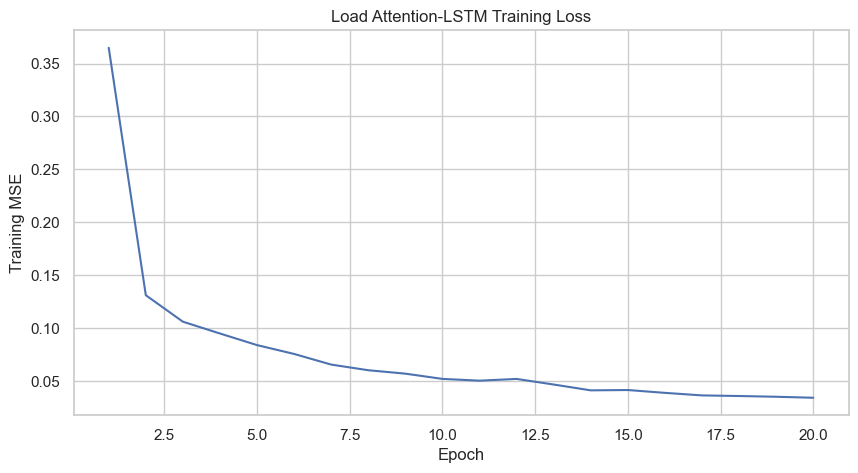

In [ ]:
# Plot Attention-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, ATTENTION_EPOCHS + 1),
    attention_load_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load Attention-LSTM Training Loss")

plt.grid(True)
plt.show()

In [ ]:
# Generate Attention-LSTM test predictions

attention_load_model.eval()

attention_load_predictions_scaled = []
attention_load_actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in load_test_loader:

        X_batch = X_batch.to(device)

        predictions = attention_load_model(
            X_batch
        )

        attention_load_predictions_scaled.extend(
            predictions.cpu().numpy()
        )

        attention_load_actual_scaled.extend(
            y_batch.numpy()
        )

attention_load_predictions_scaled = np.array(
    attention_load_predictions_scaled
)

attention_load_actual_scaled = np.array(
    attention_load_actual_scaled
)

print(
    "Prediction shape:",
    attention_load_predictions_scaled.shape
)

print(
    "Actual shape    :",
    attention_load_actual_scaled.shape
)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# Convert Attention-LSTM predictions back to MW

attention_load_predictions = load_y_scaler.inverse_transform(
    attention_load_predictions_scaled.reshape(-1, 1)
).flatten()

attention_load_actual = load_y_scaler.inverse_transform(
    attention_load_actual_scaled.reshape(-1, 1)
).flatten()

In [ ]:
# Calculate Attention-LSTM test metrics

attention_load_mae = mean_absolute_error(
    attention_load_actual,
    attention_load_predictions
)

attention_load_rmse = np.sqrt(
    mean_squared_error(
        attention_load_actual,
        attention_load_predictions
    )
)

attention_load_r2 = r2_score(
    attention_load_actual,
    attention_load_predictions
)

print("=" * 50)
print("LOAD ATTENTION-LSTM — 2025 TEST RESULTS")
print("=" * 50)

print(f"MAE  : {attention_load_mae:.4f} MW")
print(f"RMSE : {attention_load_rmse:.4f} MW")
print(f"R²   : {attention_load_r2:.4f}")

LOAD ATTENTION-LSTM — 2025 TEST RESULTS
MAE  : 4231.4595 MW
RMSE : 5709.7517 MW
R²   : 0.6816


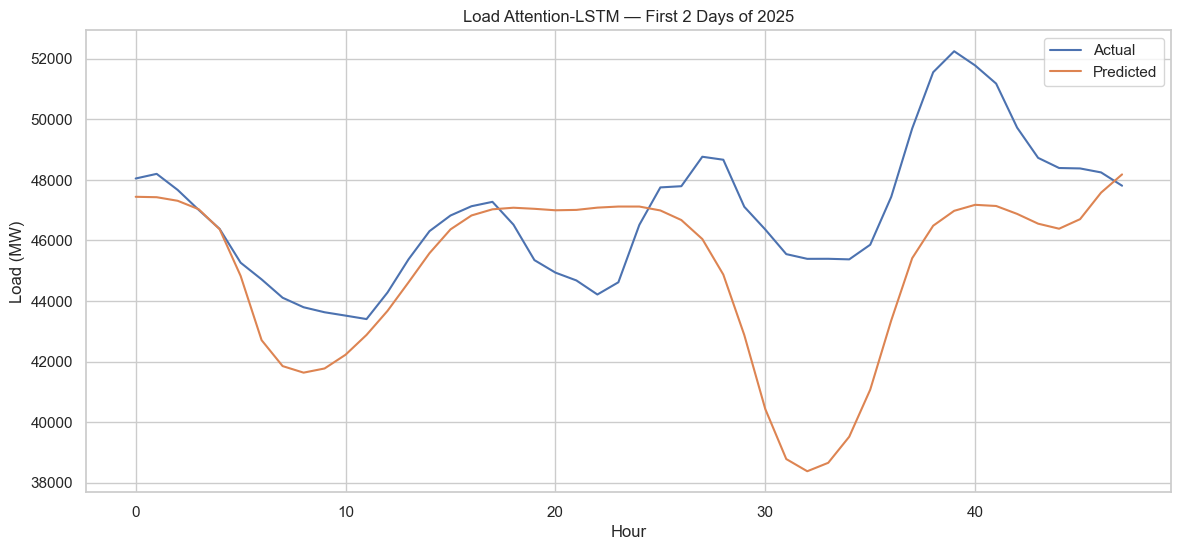

In [ ]:
# Plot the first two days of Attention-LSTM predictions

hours = 48

plt.figure(figsize=(14, 6))

plt.plot(
    attention_load_actual[:hours],
    label="Actual"
)

plt.plot(
    attention_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load Attention-LSTM — First 2 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

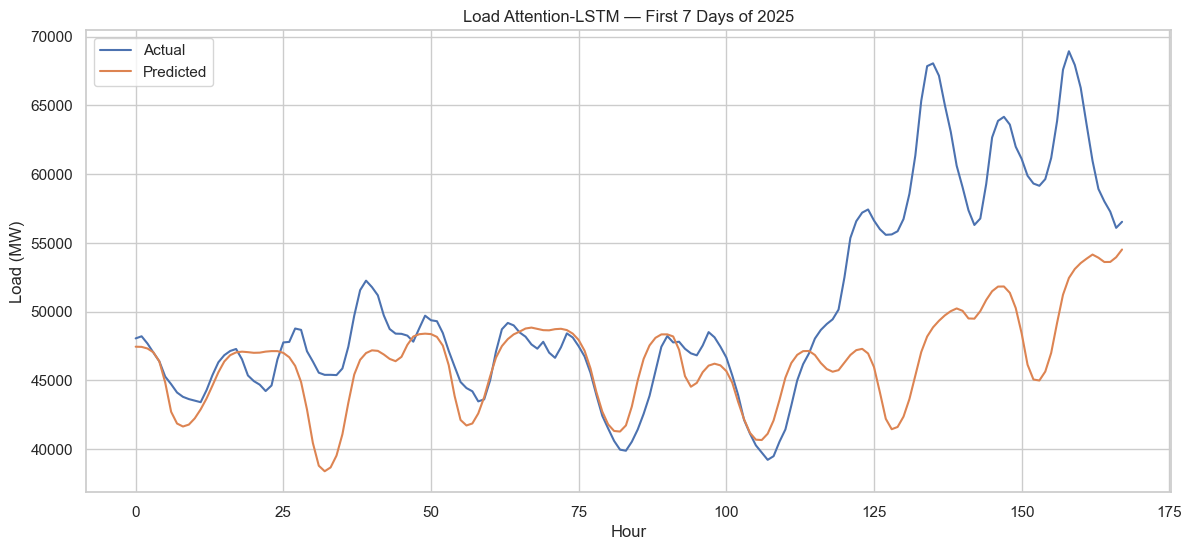

In [ ]:
# Plot the first seven days of Attention-LSTM predictions

hours = 168

plt.figure(figsize=(14, 6))

plt.plot(
    attention_load_actual[:hours],
    label="Actual"
)

plt.plot(
    attention_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load Attention-LSTM — First 7 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Compare the three 1-hour Load models

load_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "CNN-LSTM",
        "Attention-LSTM"
    ],
    "MAE_MW": [
        619.3125,
        753.270752,
        attention_load_mae
    ],
    "RMSE_MW": [
        814.2667,
        992.068515,
        attention_load_rmse
    ],
    "R2": [
        0.9935,
        0.990388,
        attention_load_r2
    ]
})

load_model_comparison

,Model,MAE_MW,RMSE_MW,R2
0,Baseline LSTM,619.312500,814.266700,0.993500
1,CNN-LSTM,753.270752,992.068515,0.990388
2,Attention-LSTM,4231.459473,5709.751658,0.681609


# Residual - LSTM

In [ ]:
# Define the 1-hour Residual-LSTM model

class ResidualLSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        dropout=0.2
    ):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout1 = nn.Dropout(dropout)

        self.lstm2 = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        output1, _ = self.lstm1(x)

        output1_dropped = self.dropout1(
            output1
        )

        output2, _ = self.lstm2(
            output1_dropped
        )

        residual = output1[:, -1, :]

        last_output = output2[:, -1, :]

        last_output = last_output + residual

        last_output = self.dropout2(
            last_output
        )

        prediction = self.fc(
            last_output
        )

        return prediction.squeeze(1)

In [ ]:
# Create the Residual-LSTM model

residual_load_model = ResidualLSTMForecaster(
    input_size=len(load_features),
    hidden_size=64,
    dropout=0.2
)

residual_load_model = residual_load_model.to(device)

print(residual_load_model)

ResidualLSTMForecaster(
  (lstm1): LSTM(13, 64, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 64, batch_first=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# Count trainable parameters

residual_parameters = sum(
    p.numel()
    for p in residual_load_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", residual_parameters)

Trainable parameters: 53569


In [ ]:
# Test the Residual-LSTM forward pass

X_batch, y_batch = next(
    iter(load_train_loader)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    residual_output = residual_load_model(
        X_batch
    )

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Output shape:", residual_output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [ ]:
# Define Residual-LSTM loss and optimizer

residual_load_criterion = nn.MSELoss()

residual_load_optimizer = torch.optim.Adam(
    residual_load_model.parameters(),
    lr=0.001
)

In [ ]:
# Train the Residual-LSTM

RESIDUAL_EPOCHS = 20

residual_load_history = train_cnn_lstm(
    model=residual_load_model,
    train_loader=load_train_loader,
    criterion=residual_load_criterion,
    optimizer=residual_load_optimizer,
    epochs=RESIDUAL_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.106070
Epoch [2/20] Loss: 0.019199
Epoch [3/20] Loss: 0.014593
Epoch [4/20] Loss: 0.012579
Epoch [5/20] Loss: 0.011511
Epoch [6/20] Loss: 0.010245
Epoch [7/20] Loss: 0.009877
Epoch [8/20] Loss: 0.009043
Epoch [9/20] Loss: 0.008676
Epoch [10/20] Loss: 0.008523
Epoch [11/20] Loss: 0.008121
Epoch [12/20] Loss: 0.007857
Epoch [13/20] Loss: 0.007631
Epoch [14/20] Loss: 0.007012
Epoch [15/20] Loss: 0.007268
Epoch [16/20] Loss: 0.006920
Epoch [17/20] Loss: 0.006662
Epoch [18/20] Loss: 0.006768
Epoch [19/20] Loss: 0.006552
Epoch [20/20] Loss: 0.006538


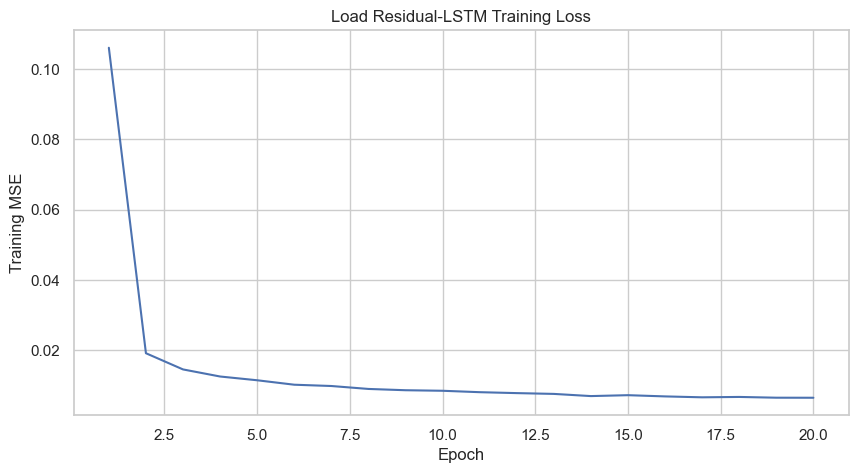

In [ ]:
# Plot Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, RESIDUAL_EPOCHS + 1),
    residual_load_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load Residual-LSTM Training Loss")

plt.grid(True)
plt.show()

In [ ]:
# Generate Residual-LSTM test predictions

residual_load_model.eval()

residual_load_predictions_scaled = []
residual_load_actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in load_test_loader:

        X_batch = X_batch.to(device)

        predictions = residual_load_model(
            X_batch
        )

        residual_load_predictions_scaled.extend(
            predictions.cpu().numpy()
        )

        residual_load_actual_scaled.extend(
            y_batch.numpy()
        )

residual_load_predictions_scaled = np.array(
    residual_load_predictions_scaled
)

residual_load_actual_scaled = np.array(
    residual_load_actual_scaled
)

print(
    "Prediction shape:",
    residual_load_predictions_scaled.shape
)

print(
    "Actual shape    :",
    residual_load_actual_scaled.shape
)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# Convert Residual-LSTM predictions back to MW

residual_load_predictions = load_y_scaler.inverse_transform(
    residual_load_predictions_scaled.reshape(-1, 1)
).flatten()

residual_load_actual = load_y_scaler.inverse_transform(
    residual_load_actual_scaled.reshape(-1, 1)
).flatten()

In [ ]:
# Calculate Residual-LSTM test metrics

residual_load_mae = mean_absolute_error(
    residual_load_actual,
    residual_load_predictions
)

residual_load_rmse = np.sqrt(
    mean_squared_error(
        residual_load_actual,
        residual_load_predictions
    )
)

residual_load_r2 = r2_score(
    residual_load_actual,
    residual_load_predictions
)

print("=" * 50)
print("LOAD RESIDUAL-LSTM — 2025 TEST RESULTS")
print("=" * 50)

print(f"MAE  : {residual_load_mae:.4f} MW")
print(f"RMSE : {residual_load_rmse:.4f} MW")
print(f"R²   : {residual_load_r2:.4f}")

LOAD RESIDUAL-LSTM — 2025 TEST RESULTS
MAE  : 536.8350 MW
RMSE : 729.7688 MW
R²   : 0.9948


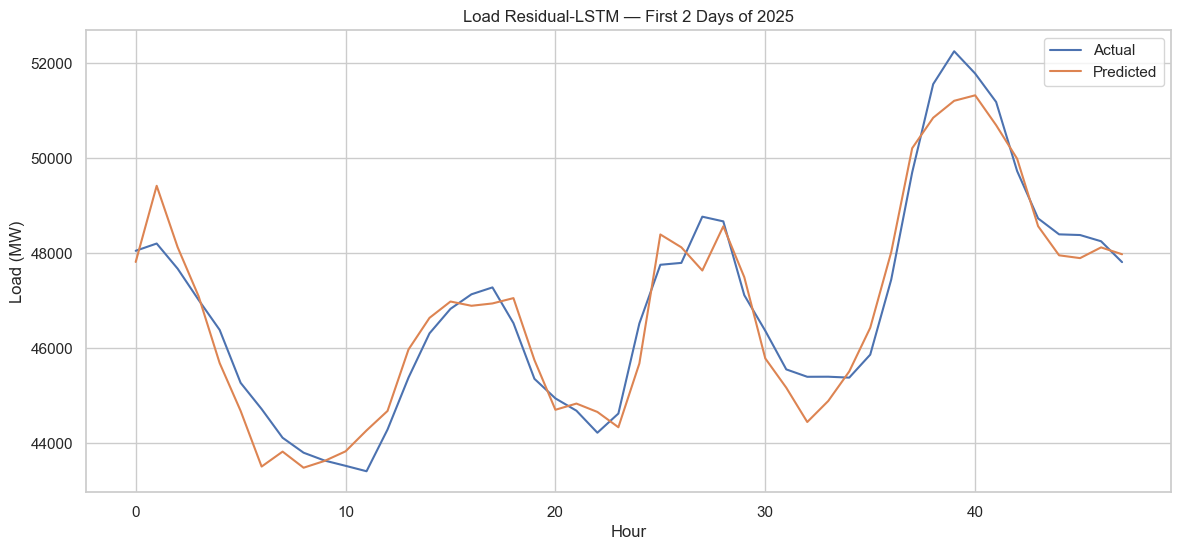

In [ ]:
# Plot the first two days of Residual-LSTM predictions

hours = 48

plt.figure(figsize=(14, 6))

plt.plot(
    residual_load_actual[:hours],
    label="Actual"
)

plt.plot(
    residual_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load Residual-LSTM — First 2 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

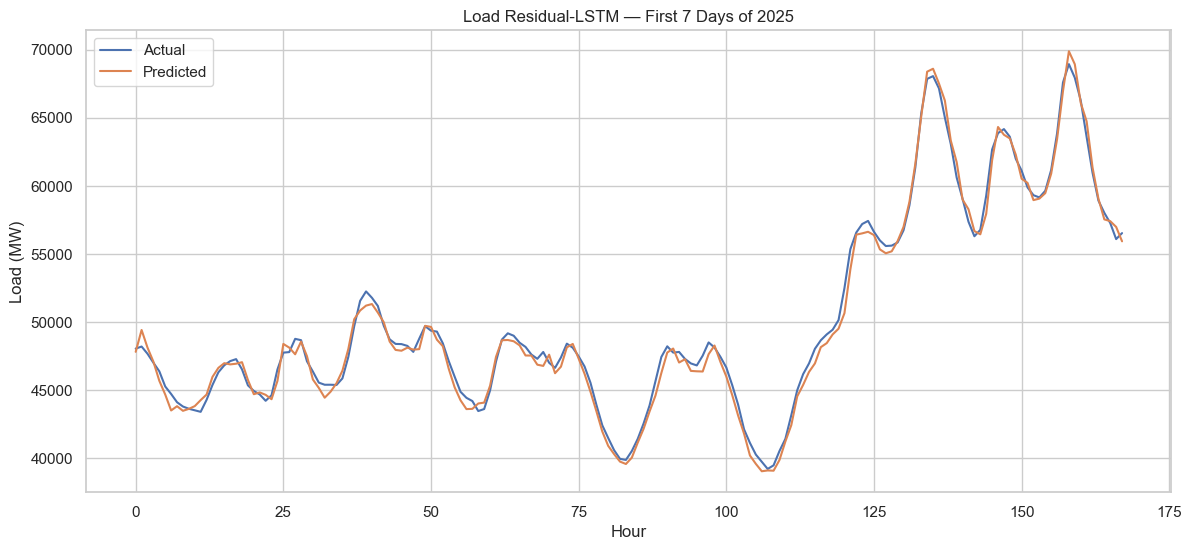

In [ ]:
# Plot the first seven days of Residual-LSTM predictions

hours = 168

plt.figure(figsize=(14, 6))

plt.plot(
    residual_load_actual[:hours],
    label="Actual"
)

plt.plot(
    residual_load_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title("Load Residual-LSTM — First 7 Days of 2025")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Compare all 1-hour Load models

load_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "CNN-LSTM",
        "Attention-LSTM",
        "Residual-LSTM"
    ],
    "MAE_MW": [
        619.3125,
        753.270752,
        4231.459473,
        residual_load_mae
    ],
    "RMSE_MW": [
        814.2667,
        992.068515,
        5709.751658,
        residual_load_rmse
    ],
    "R2": [
        0.9935,
        0.990388,
        0.681609,
        residual_load_r2
    ]
})

load_model_comparison

,Model,MAE_MW,RMSE_MW,R2
0,Baseline LSTM,619.312500,814.266700,0.993500
1,CNN-LSTM,753.270752,992.068515,0.990388
2,Attention-LSTM,4231.459473,5709.751658,0.681609
3,Residual-LSTM,536.834961,729.768799,0.994799


# Residual-LSTM 6 hours

In [ ]:
# Define the 6-hour Residual-LSTM model

class ResidualLSTMForecaster6H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        dropout=0.2,
        output_size=6
    ):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout1 = nn.Dropout(dropout)

        self.lstm2 = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        output1, _ = self.lstm1(x)

        output1_dropped = self.dropout1(
            output1
        )

        output2, _ = self.lstm2(
            output1_dropped
        )

        residual = output1[:, -1, :]

        last_output = output2[:, -1, :]

        last_output = last_output + residual

        last_output = self.dropout2(
            last_output
        )

        prediction = self.fc(
            last_output
        )

        return prediction

In [ ]:
# Create the 6-hour Residual-LSTM

load_input_size = len(load_features)

residual_load_model_6h = ResidualLSTMForecaster6H(
    input_size=load_input_size,
    hidden_size=64,
    dropout=0.2,
    output_size=6
)

residual_load_model_6h = residual_load_model_6h.to(device)

print(residual_load_model_6h)

ResidualLSTMForecaster6H(
  (lstm1): LSTM(13, 64, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 64, batch_first=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [ ]:
# Count trainable parameters

residual_parameters_6h = sum(
    p.numel()
    for p in residual_load_model_6h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    residual_parameters_6h
)

Trainable parameters: 53894


In [ ]:
# Test the 6-hour Residual-LSTM forward pass

X_batch, y_batch = next(
    iter(train_loader)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    residual_output_6h = residual_load_model_6h(
        X_batch
    )

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Output shape:", residual_output_6h.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64, 6])
Output shape: torch.Size([64, 6])


In [ ]:
# Define the 6-hour Residual-LSTM loss and optimizer

residual_6h_criterion = nn.MSELoss()

residual_6h_optimizer = torch.optim.Adam(
    residual_load_model_6h.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
# Train the 6-hour Residual-LSTM

RESIDUAL_6H_EPOCHS = 20

residual_history_6h = train_model_multi_output(
    model=residual_load_model_6h,
    train_loader=train_loader,
    criterion=residual_6h_criterion,
    optimizer=residual_6h_optimizer,
    epochs=RESIDUAL_6H_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.149054
Epoch [2/20] Loss: 0.039181
Epoch [3/20] Loss: 0.029152
Epoch [4/20] Loss: 0.025542
Epoch [5/20] Loss: 0.023613
Epoch [6/20] Loss: 0.022257
Epoch [7/20] Loss: 0.020826
Epoch [8/20] Loss: 0.020605
Epoch [9/20] Loss: 0.019766
Epoch [10/20] Loss: 0.018559
Epoch [11/20] Loss: 0.018372
Epoch [12/20] Loss: 0.017970
Epoch [13/20] Loss: 0.017507
Epoch [14/20] Loss: 0.017667
Epoch [15/20] Loss: 0.016896
Epoch [16/20] Loss: 0.016816
Epoch [17/20] Loss: 0.016609
Epoch [18/20] Loss: 0.016116
Epoch [19/20] Loss: 0.015890
Epoch [20/20] Loss: 0.015793


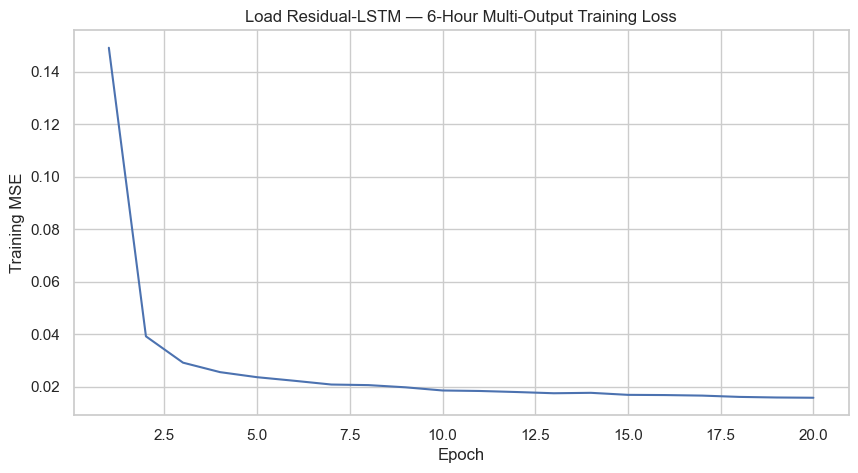

In [ ]:
# Plot 6-hour Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, RESIDUAL_6H_EPOCHS + 1),
    residual_history_6h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title(
    "Load Residual-LSTM — 6-Hour Multi-Output Training Loss"
)

plt.grid(True)

plt.show()

In [ ]:
# Generate 6-hour Residual-LSTM predictions

residual_load_model_6h.eval()

residual_predictions_scaled = []
residual_actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = residual_load_model_6h(
            X_batch
        )

        residual_predictions_scaled.append(
            predictions.cpu().numpy()
        )

        residual_actual_scaled.append(
            y_batch.numpy()
        )

residual_predictions_scaled = np.vstack(
    residual_predictions_scaled
)

residual_actual_scaled = np.vstack(
    residual_actual_scaled
)

print(
    "Predictions shape:",
    residual_predictions_scaled.shape
)

print(
    "Actual shape:",
    residual_actual_scaled.shape
)

Predictions shape: (8755, 6)
Actual shape: (8755, 6)


In [ ]:
# Convert 6-hour predictions back to MW

residual_predictions_original = y_scaler.inverse_transform(
    residual_predictions_scaled.reshape(-1, 1)
).reshape(
    residual_predictions_scaled.shape
)

residual_actual_original = y_scaler.inverse_transform(
    residual_actual_scaled.reshape(-1, 1)
).reshape(
    residual_actual_scaled.shape
)

print(
    "Prediction range:",
    residual_predictions_original.min(),
    "to",
    residual_predictions_original.max(),
    "MW"
)

print(
    "Actual range:",
    residual_actual_original.min(),
    "to",
    residual_actual_original.max(),
    "MW"
)

Prediction range: 37521.566 to 85913.945 MW
Actual range: 38617.902 to 83876.46 MW


In [ ]:
# Calculate metrics for all available forecast horizons

num_horizons = residual_predictions_original.shape[1]

residual_results = []

for h in range(num_horizons):

    actual_h = residual_actual_original[:, h]

    pred_h = residual_predictions_original[:, h]

    mae = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2 = r2_score(
        actual_h,
        pred_h
    )

    residual_results.append({
        "Horizon": f"t+{h+1}",
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "R2": r2
    })

residual_results_df = pd.DataFrame(
    residual_results
)

residual_results_df

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,741.906616,974.348981,0.990730
1,t+2,1016.905762,1344.298609,0.982355
2,t+3,1220.501709,1608.961078,0.974722
3,t+4,1362.681030,1801.214451,0.968320
4,t+5,1491.768555,1965.927834,0.962261
5,t+6,1621.335693,2127.784059,0.955789


In [ ]:
# Check the 6-hour Residual-LSTM prediction dimensions

print("FORECAST_HORIZON:", FORECAST_HORIZON)

print(
    "Predictions shape:",
    residual_predictions_scaled.shape
)

print(
    "Actual shape:",
    residual_actual_scaled.shape
)

print(
    "Model output size:",
    residual_load_model_6h.fc.out_features
)

FORECAST_HORIZON: 1
Predictions shape: (8755, 6)
Actual shape: (8755, 6)
Model output size: 6


In [ ]:
# Calculate overall 6-hour Residual-LSTM performance

residual_overall_actual = (
    residual_actual_original.flatten()
)

residual_overall_pred = (
    residual_predictions_original.flatten()
)

residual_overall_mae = mean_absolute_error(
    residual_overall_actual,
    residual_overall_pred
)

residual_overall_rmse = np.sqrt(
    mean_squared_error(
        residual_overall_actual,
        residual_overall_pred
    )
)

residual_overall_r2 = r2_score(
    residual_overall_actual,
    residual_overall_pred
)

print("=" * 55)
print("LOAD RESIDUAL-LSTM — 6-HOUR RESULTS")
print("=" * 55)

print(
    f"Overall MAE  : {residual_overall_mae:.4f} MW"
)

print(
    f"Overall RMSE : {residual_overall_rmse:.4f} MW"
)

print(
    f"Overall R²   : {residual_overall_r2:.4f}"
)

LOAD RESIDUAL-LSTM — 6-HOUR RESULTS
Overall MAE  : 1242.5165 MW
Overall RMSE : 1682.3575 MW
Overall R²   : 0.9724


In [ ]:
# Compare baseline and Residual-LSTM across all horizons

comparison_horizon = pd.DataFrame({
    "Horizon": results_df["Horizon"].values,
    "Baseline_LSTM_MAE": results_df["MAE_MW"].values,
    "Residual_LSTM_MAE": residual_results_df["MAE_MW"].values
})

comparison_horizon

,Horizon,Baseline_LSTM_MAE,Residual_LSTM_MAE
0,t+1,1002.326233,741.906616
1,t+2,1150.808228,1016.905762
2,t+3,1286.762817,1220.501709
3,t+4,1416.933350,1362.681030
4,t+5,1538.448242,1491.768555
5,t+6,1655.123413,1621.335693


In [ ]:
# Calculate Residual-LSTM improvement over the 6-hour baseline

mae_improvement_6h = (
    (1341.7338 - residual_overall_mae)
    / 1341.7338
) * 100

rmse_improvement_6h = (
    (1780.7989 - residual_overall_rmse)
    / 1780.7989
) * 100

r2_improvement_6h = (
    (residual_overall_r2 - 0.9690)
    / 0.9690
) * 100

print(
    f"MAE improvement : {mae_improvement_6h:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement_6h:.2f}%"
)

print(
    f"R² improvement  : {r2_improvement_6h:.2f}%"
)

MAE improvement : 7.39%
RMSE improvement: 5.53%
R² improvement  : 0.35%


In [ ]:
# Compare MAE across the six forecast horizons

comparison_horizon = pd.DataFrame({
    "Horizon": results_df["Horizon"],
    "Baseline_LSTM_MAE": results_df["MAE_MW"],
    "Residual_LSTM_MAE": residual_results_df["MAE_MW"]
})

comparison_horizon

,Horizon,Baseline_LSTM_MAE,Residual_LSTM_MAE
0,t+1,1002.326233,741.906616
1,t+2,1150.808228,1016.905762
2,t+3,1286.762817,1220.501709
3,t+4,1416.933350,1362.681030
4,t+5,1538.448242,1491.768555
5,t+6,1655.123413,1621.335693


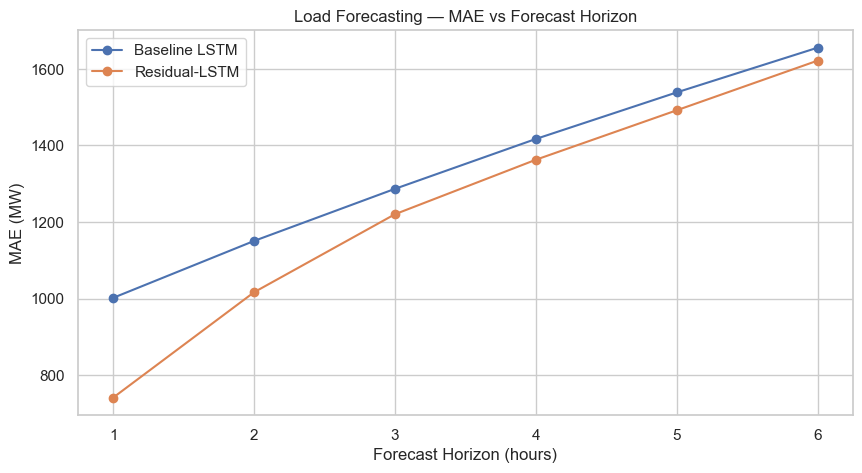

In [ ]:
# Plot MAE across all six forecast horizons

num_horizons = residual_predictions_original.shape[1]

horizons = np.arange(
    1,
    num_horizons + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["MAE_MW"].values,
    marker="o",
    label="Baseline LSTM"
)

plt.plot(
    horizons,
    residual_results_df["MAE_MW"].values,
    marker="o",
    label="Residual-LSTM"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("MAE (MW)")
plt.title("Load Forecasting — MAE vs Forecast Horizon")

plt.xticks(horizons)

plt.grid(True)
plt.legend()

plt.show()

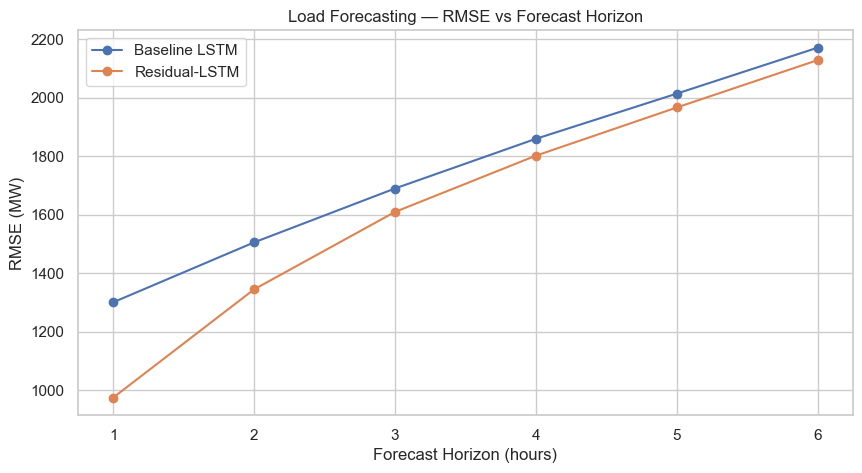

In [ ]:
# Plot RMSE across all six forecast horizons

num_horizons = residual_predictions_original.shape[1]

horizons = np.arange(
    1,
    num_horizons + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["RMSE_MW"].values,
    marker="o",
    label="Baseline LSTM"
)

plt.plot(
    horizons,
    residual_results_df["RMSE_MW"].values,
    marker="o",
    label="Residual-LSTM"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("RMSE (MW)")
plt.title("Load Forecasting — RMSE vs Forecast Horizon")

plt.xticks(horizons)

plt.grid(True)
plt.legend()

plt.show()

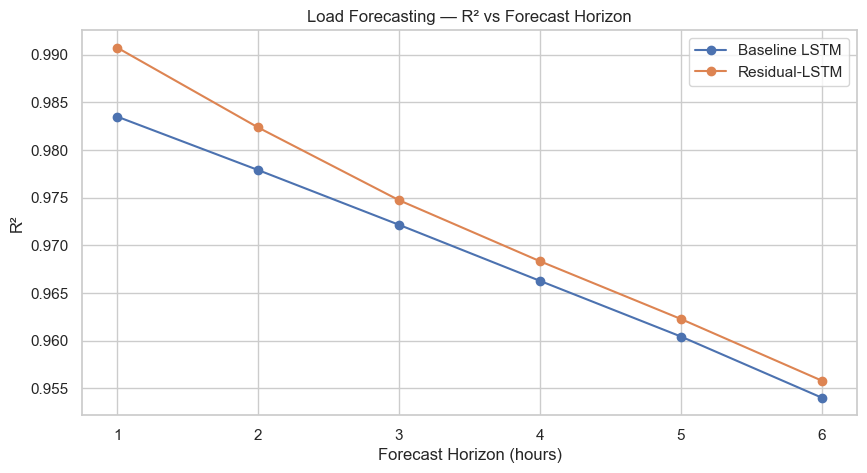

In [ ]:
# Plot R² across all six forecast horizons

num_horizons = residual_predictions_original.shape[1]

horizons = np.arange(
    1,
    num_horizons + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    horizons,
    results_df["R2"].values,
    marker="o",
    label="Baseline LSTM"
)

plt.plot(
    horizons,
    residual_results_df["R2"].values,
    marker="o",
    label="Residual-LSTM"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("R²")
plt.title("Load Forecasting — R² vs Forecast Horizon")

plt.xticks(horizons)

plt.grid(True)
plt.legend()

plt.show()

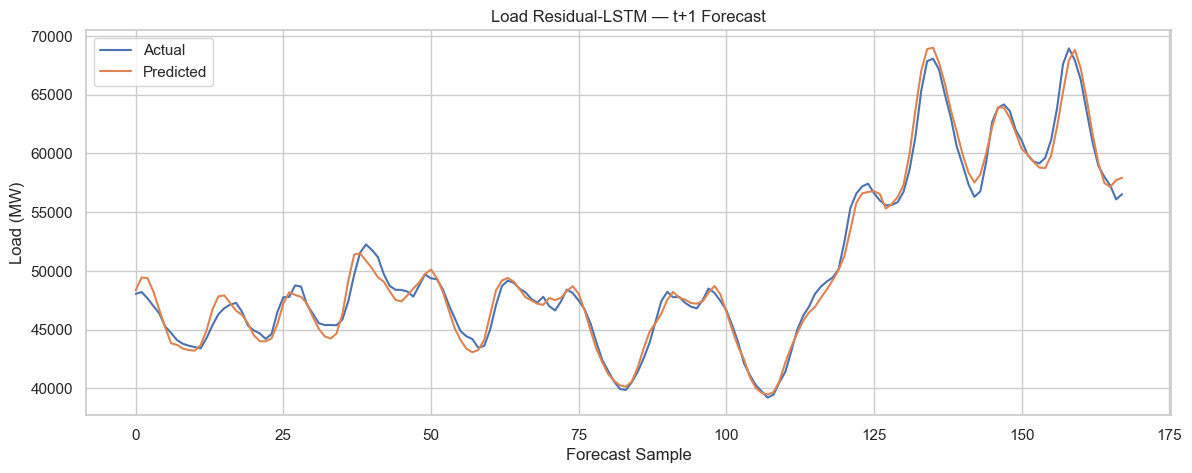

In [ ]:
# Plot Residual-LSTM t+1 predictions

N = 168

plt.figure(figsize=(14, 5))

plt.plot(
    residual_actual_original[:N, 0],
    label="Actual"
)

plt.plot(
    residual_predictions_original[:N, 0],
    label="Predicted"
)

plt.xlabel("Forecast Sample")
plt.ylabel("Load (MW)")

plt.title(
    "Load Residual-LSTM — t+1 Forecast"
)

plt.legend()
plt.grid(True)

plt.show()

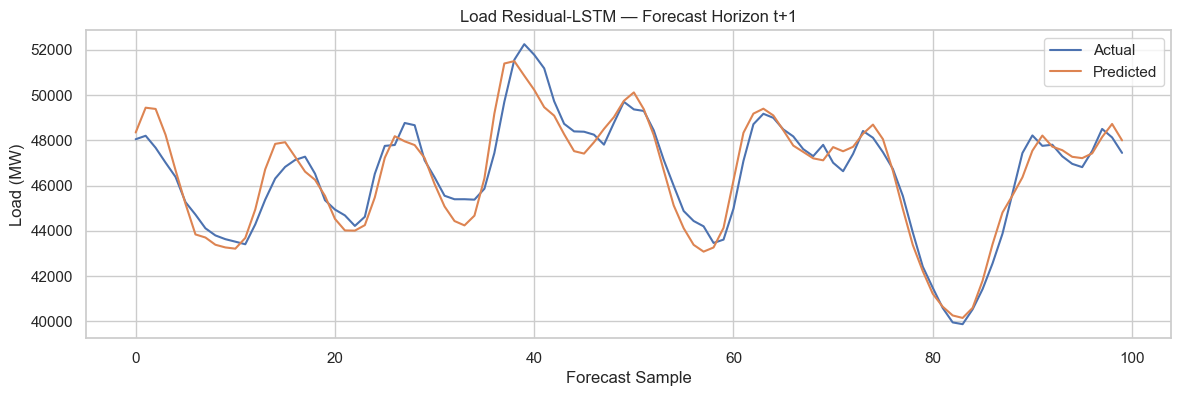

In [ ]:
# Plot Residual-LSTM predictions for all six horizons

N = 100

for h in range(FORECAST_HORIZON):

    plt.figure(figsize=(14, 4))

    plt.plot(
        residual_actual_original[:N, h],
        label="Actual"
    )

    plt.plot(
        residual_predictions_original[:N, h],
        label="Predicted"
    )

    plt.xlabel("Forecast Sample")
    plt.ylabel("Load (MW)")

    plt.title(
        f"Load Residual-LSTM — Forecast Horizon t+{h+1}"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

# CNN- LSTM- Residual 1 hour

In [ ]:
# Define the 1-hour CNN-Residual-LSTM model

class CNNResidualLSTMForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        dropout=0.2
    ):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        self.lstm1 = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout1 = nn.Dropout(dropout)

        self.lstm2 = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        x = x.permute(0, 2, 1)

        x = self.conv1(x)

        x = self.relu(x)

        x = x.permute(0, 2, 1)

        output1, _ = self.lstm1(x)

        output1_dropped = self.dropout1(
            output1
        )

        output2, _ = self.lstm2(
            output1_dropped
        )

        residual = output1[:, -1, :]

        last_output = output2[:, -1, :]

        last_output = last_output + residual

        last_output = self.dropout2(
            last_output
        )

        prediction = self.fc(
            last_output
        )

        return prediction.squeeze(1)

In [ ]:
# Create the 1-hour CNN-Residual-LSTM

cnn_residual_load_model = CNNResidualLSTMForecaster(
    input_size=len(load_features),
    hidden_size=64,
    dropout=0.2
)

cnn_residual_load_model = cnn_residual_load_model.to(device)

print(cnn_residual_load_model)

CNNResidualLSTMForecaster(
  (conv1): Conv1d(13, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm1): LSTM(64, 64, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 64, batch_first=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# Count trainable parameters

cnn_residual_parameters = sum(
    p.numel()
    for p in cnn_residual_load_model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    cnn_residual_parameters
)

Trainable parameters: 69185


In [ ]:
# Test the model forward pass

X_batch, y_batch = next(
    iter(load_train_loader)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    cnn_residual_output = cnn_residual_load_model(
        X_batch
    )

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)
print("Output shape:", cnn_residual_output.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64])
Output shape: torch.Size([64])


In [ ]:
# Define loss and optimizer

cnn_residual_criterion = nn.MSELoss()

cnn_residual_optimizer = torch.optim.Adam(
    cnn_residual_load_model.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
# Train the 1-hour CNN-Residual-LSTM

CNN_RESIDUAL_EPOCHS = 20

cnn_residual_history = train_model(
    model=cnn_residual_load_model,
    train_loader=load_train_loader,
    criterion=cnn_residual_criterion,
    optimizer=cnn_residual_optimizer,
    epochs=CNN_RESIDUAL_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.088953
Epoch [2/20] Loss: 0.015180
Epoch [3/20] Loss: 0.011911
Epoch [4/20] Loss: 0.010553
Epoch [5/20] Loss: 0.009624
Epoch [6/20] Loss: 0.009223
Epoch [7/20] Loss: 0.009041
Epoch [8/20] Loss: 0.008608
Epoch [9/20] Loss: 0.008094
Epoch [10/20] Loss: 0.008110
Epoch [11/20] Loss: 0.007748
Epoch [12/20] Loss: 0.007538
Epoch [13/20] Loss: 0.007565
Epoch [14/20] Loss: 0.007274
Epoch [15/20] Loss: 0.007195
Epoch [16/20] Loss: 0.006884
Epoch [17/20] Loss: 0.006553
Epoch [18/20] Loss: 0.006660
Epoch [19/20] Loss: 0.006821
Epoch [20/20] Loss: 0.006540


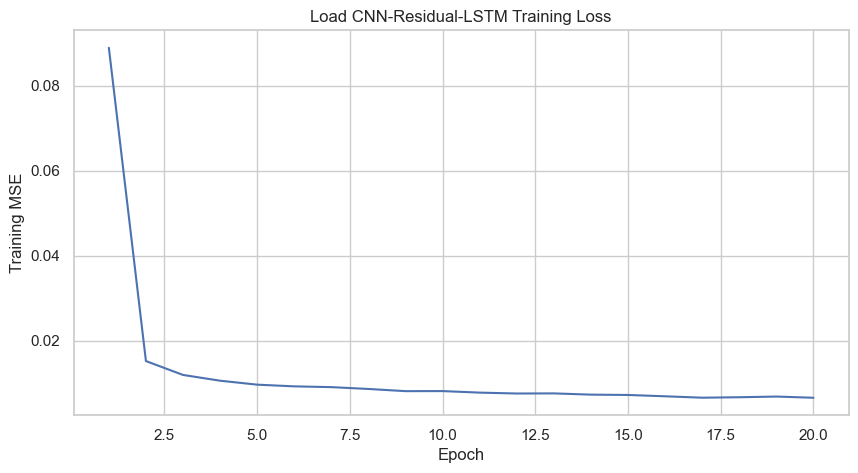

In [ ]:
# Plot CNN-Residual-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, CNN_RESIDUAL_EPOCHS + 1),
    cnn_residual_history
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Load CNN-Residual-LSTM Training Loss")

plt.grid(True)

plt.show()

In [ ]:
# Generate 1-hour test predictions

cnn_residual_load_model.eval()

cnn_residual_predictions_scaled = []
cnn_residual_actual_scaled = []

with torch.no_grad():

    for X_batch, y_batch in load_test_loader:

        X_batch = X_batch.to(device)

        predictions = cnn_residual_load_model(
            X_batch
        )

        cnn_residual_predictions_scaled.extend(
            predictions.cpu().numpy()
        )

        cnn_residual_actual_scaled.extend(
            y_batch.numpy()
        )

cnn_residual_predictions_scaled = np.array(
    cnn_residual_predictions_scaled
)

cnn_residual_actual_scaled = np.array(
    cnn_residual_actual_scaled
)

print(
    "Prediction shape:",
    cnn_residual_predictions_scaled.shape
)

print(
    "Actual shape    :",
    cnn_residual_actual_scaled.shape
)

Prediction shape: (8760,)
Actual shape    : (8760,)


In [ ]:
# Convert predictions back to MW

cnn_residual_predictions = load_y_scaler.inverse_transform(
    cnn_residual_predictions_scaled.reshape(-1, 1)
).flatten()

cnn_residual_actual = load_y_scaler.inverse_transform(
    cnn_residual_actual_scaled.reshape(-1, 1)
).flatten()

In [ ]:
# Calculate CNN-Residual-LSTM test metrics

cnn_residual_mae = mean_absolute_error(
    cnn_residual_actual,
    cnn_residual_predictions
)

cnn_residual_rmse = np.sqrt(
    mean_squared_error(
        cnn_residual_actual,
        cnn_residual_predictions
    )
)

cnn_residual_r2 = r2_score(
    cnn_residual_actual,
    cnn_residual_predictions
)

print("=" * 55)
print("LOAD CNN-RESIDUAL-LSTM — 2025 TEST RESULTS")
print("=" * 55)

print(
    f"MAE  : {cnn_residual_mae:.4f} MW"
)

print(
    f"RMSE : {cnn_residual_rmse:.4f} MW"
)

print(
    f"R²   : {cnn_residual_r2:.4f}"
)

LOAD CNN-RESIDUAL-LSTM — 2025 TEST RESULTS
MAE  : 619.4652 MW
RMSE : 818.6685 MW
R²   : 0.9935


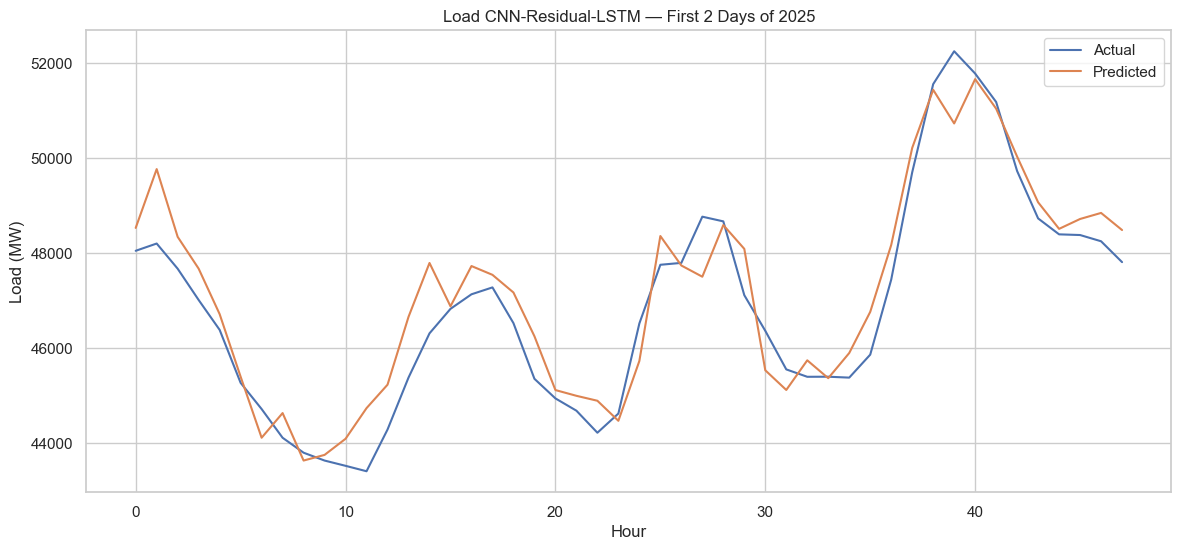

In [ ]:
# Plot the first two days of CNN-Residual-LSTM predictions

hours = 48

plt.figure(figsize=(14, 6))

plt.plot(
    cnn_residual_actual[:hours],
    label="Actual"
)

plt.plot(
    cnn_residual_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title(
    "Load CNN-Residual-LSTM — First 2 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

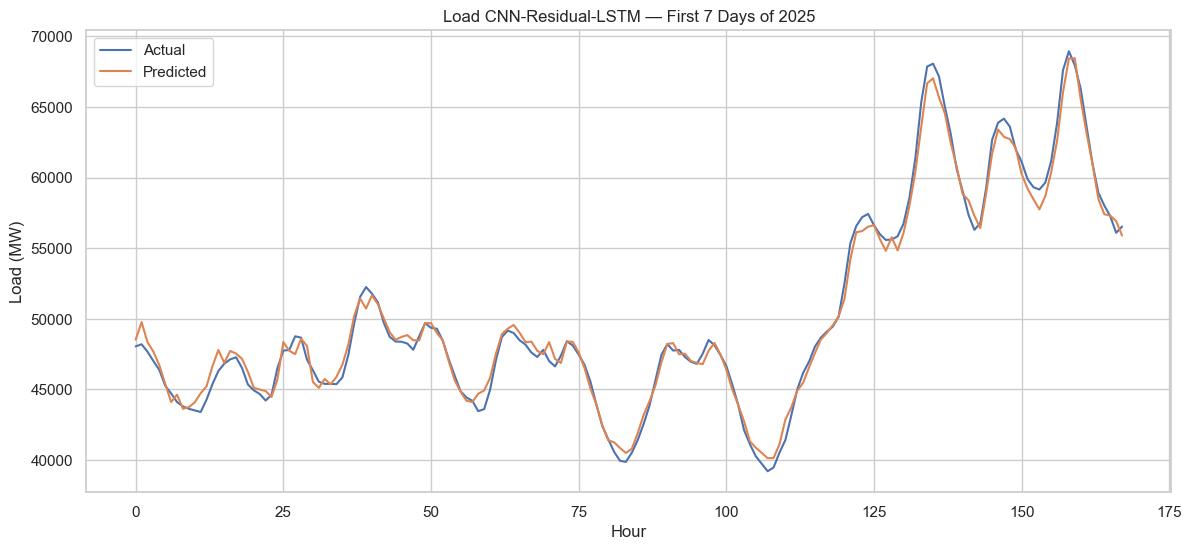

In [ ]:
# Plot the first seven days of CNN-Residual-LSTM predictions

hours = 168

plt.figure(figsize=(14, 6))

plt.plot(
    cnn_residual_actual[:hours],
    label="Actual"
)

plt.plot(
    cnn_residual_predictions[:hours],
    label="Predicted"
)

plt.xlabel("Hour")
plt.ylabel("Load (MW)")
plt.title(
    "Load CNN-Residual-LSTM — First 7 Days of 2025"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Compare all 1-hour Load models

load_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "CNN-LSTM",
        "Attention-LSTM",
        "Residual-LSTM",
        "CNN-Residual-LSTM"
    ],
    "MAE_MW": [
        619.3125,
        753.270752,
        4231.459473,
        536.834961,
        cnn_residual_mae
    ],
    "RMSE_MW": [
        814.2667,
        992.068515,
        5709.751658,
        729.768799,
        cnn_residual_rmse
    ],
    "R2": [
        0.9935,
        0.990388,
        0.681609,
        0.994799,
        cnn_residual_r2
    ]
})

load_model_comparison

,Model,MAE_MW,RMSE_MW,R2
0,Baseline LSTM,619.312500,814.266700,0.993500
1,CNN-LSTM,753.270752,992.068515,0.990388
2,Attention-LSTM,4231.459473,5709.751658,0.681609
3,Residual-LSTM,536.834961,729.768799,0.994799
4,CNN-Residual-LSTM,619.465210,818.668546,0.993455


In [ ]:
# Compare CNN-Residual-LSTM with the best 1-hour model

mae_change = (
    (536.834961 - cnn_residual_mae)
    / 536.834961
) * 100

rmse_change = (
    (729.768799 - cnn_residual_rmse)
    / 729.768799
) * 100

r2_change = (
    (cnn_residual_r2 - 0.994799)
    / 0.994799
) * 100

print(
    f"MAE improvement over Residual-LSTM : {mae_change:.2f}%"
)

print(
    f"RMSE improvement over Residual-LSTM: {rmse_change:.2f}%"
)

print(
    f"R² improvement over Residual-LSTM  : {r2_change:.2f}%"
)

MAE improvement over Residual-LSTM : -15.39%
RMSE improvement over Residual-LSTM: -12.18%
R² improvement over Residual-LSTM  : -0.14%


# LSTM-Residual 24h

In [86]:
# Set the 24-hour forecasting configuration

LOOKBACK_24H = 168
FORECAST_HORIZON_24H = 24

print("Lookback:", LOOKBACK_24H)
print("Forecast horizon:", FORECAST_HORIZON_24H)

Lookback: 168
Forecast horizon: 24


In [87]:
# Create 24-hour training sequences

X_train_seq_24h, y_train_seq_24h = create_multi_output_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK_24H,
    FORECAST_HORIZON_24H
)

print("X_train_seq_24h shape:", X_train_seq_24h.shape)
print("y_train_seq_24h shape:", y_train_seq_24h.shape)

NameError: name 'create_multi_output_sequences' is not defined

In [ ]:
# Create test context using the final 168 training hours

X_test_context_24h = np.vstack([
    X_train_scaled[-LOOKBACK_24H:],
    X_test_scaled
])

y_test_context_24h = np.vstack([
    y_train_scaled[-LOOKBACK_24H:],
    y_test_scaled
])

print(
    "X_test_context_24h shape:",
    X_test_context_24h.shape
)

print(
    "y_test_context_24h shape:",
    y_test_context_24h.shape
)

X_test_context_24h shape: (8928, 13)
y_test_context_24h shape: (8928, 1)


In [ ]:
# Create 24-hour test sequences

X_test_seq_24h = []
y_test_seq_24h = []

for i in range(
    len(X_test_scaled) - FORECAST_HORIZON_24H + 1
):

    X_seq = X_test_context_24h[
        i : i + LOOKBACK_24H
    ]

    target_start = LOOKBACK_24H + i

    y_seq = y_test_context_24h[
        target_start :
        target_start + FORECAST_HORIZON_24H
    ]

    X_test_seq_24h.append(X_seq)
    y_test_seq_24h.append(y_seq.flatten())

X_test_seq_24h = np.array(
    X_test_seq_24h
)

y_test_seq_24h = np.array(
    y_test_seq_24h
)

print(
    "X_test_seq_24h shape:",
    X_test_seq_24h.shape
)

print(
    "y_test_seq_24h shape:",
    y_test_seq_24h.shape
)

X_test_seq_24h shape: (8737, 168, 13)
y_test_seq_24h shape: (8737, 24)


In [ ]:
# Verify the 24-hour sequence dimensions

print("Training X:", X_train_seq_24h.shape)
print("Training y:", y_train_seq_24h.shape)
print("Testing X :", X_test_seq_24h.shape)
print("Testing y :", y_test_seq_24h.shape)

assert X_train_seq_24h.shape[1] == 168
assert X_train_seq_24h.shape[2] == 13

assert y_train_seq_24h.shape[1] == 24
assert y_test_seq_24h.shape[1] == 24

print("All shape checks passed.")

Training X: (17346, 168, 13)
Training y: (17346, 24)
Testing X : (8737, 168, 13)
Testing y : (8737, 24)
All shape checks passed.


In [ ]:
# Convert 24-hour sequences to PyTorch tensors

X_train_tensor_24h = torch.tensor(
    X_train_seq_24h,
    dtype=torch.float32
)

y_train_tensor_24h = torch.tensor(
    y_train_seq_24h,
    dtype=torch.float32
)

X_test_tensor_24h = torch.tensor(
    X_test_seq_24h,
    dtype=torch.float32
)

y_test_tensor_24h = torch.tensor(
    y_test_seq_24h,
    dtype=torch.float32
)

print("X_train:", X_train_tensor_24h.shape)
print("y_train:", y_train_tensor_24h.shape)
print("X_test :", X_test_tensor_24h.shape)
print("y_test :", y_test_tensor_24h.shape)

X_train: torch.Size([17346, 168, 13])
y_train: torch.Size([17346, 24])
X_test : torch.Size([8737, 168, 13])
y_test : torch.Size([8737, 24])


In [ ]:
# Create 24-hour DataLoaders

train_dataset_24h = TensorDataset(
    X_train_tensor_24h,
    y_train_tensor_24h
)

test_dataset_24h = TensorDataset(
    X_test_tensor_24h,
    y_test_tensor_24h
)

train_loader_24h = DataLoader(
    train_dataset_24h,
    batch_size=64,
    shuffle=True
)

test_loader_24h = DataLoader(
    test_dataset_24h,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader_24h))
print("Testing batches :", len(test_loader_24h))

Training batches: 272
Testing batches : 137


In [ ]:
# Define the 24-hour Residual-LSTM

class ResidualLSTMForecaster24H(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        dropout=0.2,
        output_size=24
    ):
        super().__init__()

        self.lstm1 = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout1 = nn.Dropout(dropout)

        self.lstm2 = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout2 = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        output1, _ = self.lstm1(x)

        output1_dropped = self.dropout1(
            output1
        )

        output2, _ = self.lstm2(
            output1_dropped
        )

        residual = output1[:, -1, :]

        last_output = output2[:, -1, :]

        last_output = last_output + residual

        last_output = self.dropout2(
            last_output
        )

        prediction = self.fc(
            last_output
        )

        return prediction

In [ ]:
# Create the 24-hour Residual-LSTM

load_input_size = len(load_features)

residual_load_model_24h = ResidualLSTMForecaster24H(
    input_size=load_input_size,
    hidden_size=64,
    dropout=0.2,
    output_size=24
)

residual_load_model_24h = (
    residual_load_model_24h.to(device)
)

print(residual_load_model_24h)

ResidualLSTMForecaster24H(
  (lstm1): LSTM(13, 64, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 64, batch_first=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=24, bias=True)
)


In [ ]:
# Count trainable parameters

residual_parameters_24h = sum(
    p.numel()
    for p in residual_load_model_24h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    residual_parameters_24h
)

Trainable parameters: 55064


In [ ]:
# Test the 24-hour Residual-LSTM forward pass

X_batch_24h, y_batch_24h = next(
    iter(train_loader_24h)
)

X_batch_24h = X_batch_24h.to(device)
y_batch_24h = y_batch_24h.to(device)

with torch.no_grad():

    residual_output_24h = (
        residual_load_model_24h(
            X_batch_24h
        )
    )

print(
    "Input shape :",
    X_batch_24h.shape
)

print(
    "Target shape:",
    y_batch_24h.shape
)

print(
    "Output shape:",
    residual_output_24h.shape
)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64, 24])
Output shape: torch.Size([64, 24])


In [ ]:
# Define the 24-hour loss and optimizer

residual_24h_criterion = nn.MSELoss()

residual_24h_optimizer = torch.optim.Adam(
    residual_load_model_24h.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
# Train the 24-hour Residual-LSTM

RESIDUAL_24H_EPOCHS = 20

residual_history_24h = train_model_multi_output(
    model=residual_load_model_24h,
    train_loader=train_loader_24h,
    criterion=residual_24h_criterion,
    optimizer=residual_24h_optimizer,
    epochs=RESIDUAL_24H_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.199241
Epoch [2/20] Loss: 0.073552
Epoch [3/20] Loss: 0.066115
Epoch [4/20] Loss: 0.060560
Epoch [5/20] Loss: 0.056600
Epoch [6/20] Loss: 0.051657
Epoch [7/20] Loss: 0.047138
Epoch [8/20] Loss: 0.045328
Epoch [9/20] Loss: 0.042526
Epoch [10/20] Loss: 0.039906
Epoch [11/20] Loss: 0.037998
Epoch [12/20] Loss: 0.036638
Epoch [13/20] Loss: 0.035601
Epoch [14/20] Loss: 0.034102
Epoch [15/20] Loss: 0.032790
Epoch [16/20] Loss: 0.031563
Epoch [17/20] Loss: 0.032856
Epoch [18/20] Loss: 0.030083
Epoch [19/20] Loss: 0.029700
Epoch [20/20] Loss: 0.034109


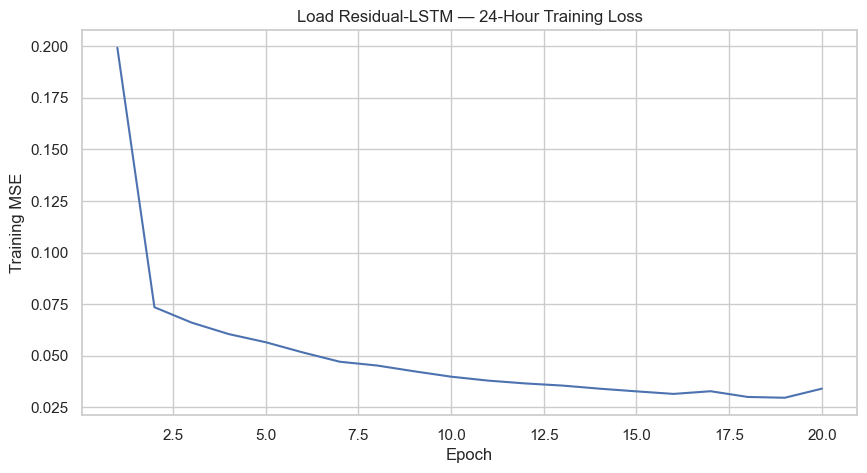

In [ ]:
# Plot the 24-hour training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        RESIDUAL_24H_EPOCHS + 1
    ),
    residual_history_24h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title(
    "Load Residual-LSTM — 24-Hour Training Loss"
)

plt.grid(True)

plt.show()

In [ ]:
# Generate 24-hour Residual-LSTM predictions

residual_load_model_24h.eval()

residual_predictions_24h_scaled = []
residual_actual_24h_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_24h:

        X_batch = X_batch.to(device)

        predictions = residual_load_model_24h(
            X_batch
        )

        residual_predictions_24h_scaled.append(
            predictions.cpu().numpy()
        )

        residual_actual_24h_scaled.append(
            y_batch.numpy()
        )

residual_predictions_24h_scaled = np.vstack(
    residual_predictions_24h_scaled
)

residual_actual_24h_scaled = np.vstack(
    residual_actual_24h_scaled
)

print(
    "Predictions shape:",
    residual_predictions_24h_scaled.shape
)

print(
    "Actual shape:",
    residual_actual_24h_scaled.shape
)

Predictions shape: (8737, 24)
Actual shape: (8737, 24)


In [ ]:
# Convert 24-hour predictions back to MW

residual_predictions_24h_original = (
    y_scaler.inverse_transform(
        residual_predictions_24h_scaled.reshape(-1, 1)
    ).reshape(
        residual_predictions_24h_scaled.shape
    )
)

residual_actual_24h_original = (
    y_scaler.inverse_transform(
        residual_actual_24h_scaled.reshape(-1, 1)
    ).reshape(
        residual_actual_24h_scaled.shape
    )
)

print(
    "Prediction range:",
    residual_predictions_24h_original.min(),
    "to",
    residual_predictions_24h_original.max(),
    "MW"
)

print(
    "Actual range:",
    residual_actual_24h_original.min(),
    "to",
    residual_actual_24h_original.max(),
    "MW"
)

Prediction range: 36178.47 to 84910.266 MW
Actual range: 38617.902 to 83876.46 MW


In [ ]:
# Calculate metrics for all 24 forecast horizons

residual_results_24h = []

for h in range(24):

    actual_h = residual_actual_24h_original[:, h]

    pred_h = residual_predictions_24h_original[:, h]

    mae = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2 = r2_score(
        actual_h,
        pred_h
    )

    residual_results_24h.append({
        "Horizon": f"t+{h+1}",
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "R2": r2
    })

residual_results_24h_df = pd.DataFrame(
    residual_results_24h
)

residual_results_24h_df

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1391.664673,1864.268020,0.966129
1,t+2,1607.934326,2134.666836,0.955587
2,t+3,1812.850220,2393.323630,0.944168
3,t+4,1996.781494,2634.962808,0.932319
4,t+5,2147.747803,2847.330592,0.920962
5,t+6,2277.636719,3030.468446,0.910459
6,t+7,2364.860596,3168.509744,0.902103
7,t+8,2424.352051,3278.833329,0.895153
8,t+9,2486.437988,3384.269345,0.888285
9,t+10,2548.526611,3484.760393,0.881534


In [ ]:
# Calculate overall 24-hour Residual-LSTM performance

residual_overall_actual_24h = (
    residual_actual_24h_original.flatten()
)

residual_overall_pred_24h = (
    residual_predictions_24h_original.flatten()
)

residual_overall_mae_24h = mean_absolute_error(
    residual_overall_actual_24h,
    residual_overall_pred_24h
)

residual_overall_rmse_24h = np.sqrt(
    mean_squared_error(
        residual_overall_actual_24h,
        residual_overall_pred_24h
    )
)

residual_overall_r2_24h = r2_score(
    residual_overall_actual_24h,
    residual_overall_pred_24h
)

print("=" * 60)
print("LOAD RESIDUAL-LSTM — 24-HOUR RESULTS")
print("=" * 60)

print(
    f"Overall MAE  : {residual_overall_mae_24h:.4f} MW"
)

print(
    f"Overall RMSE : {residual_overall_rmse_24h:.4f} MW"
)

print(
    f"Overall R²   : {residual_overall_r2_24h:.4f}"
)

LOAD RESIDUAL-LSTM — 24-HOUR RESULTS
Overall MAE  : 2584.2122 MW
Overall RMSE : 3613.1500 MW
Overall R²   : 0.8726


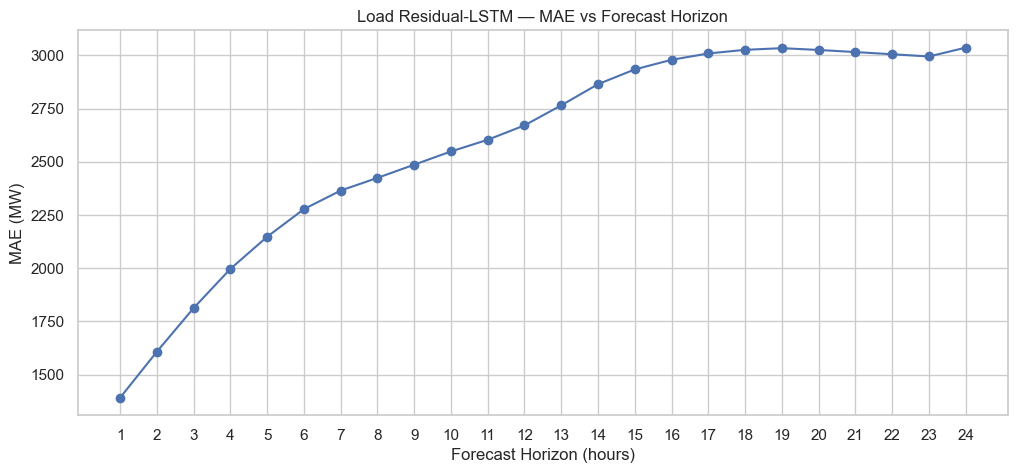

In [ ]:
# Plot MAE across the 24-hour forecast horizon

horizons_24h = np.arange(
    1,
    25
)

plt.figure(figsize=(12, 5))

plt.plot(
    horizons_24h,
    residual_results_24h_df["MAE_MW"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("MAE (MW)")
plt.title(
    "Load Residual-LSTM — MAE vs Forecast Horizon"
)

plt.xticks(horizons_24h)

plt.grid(True)

plt.show()

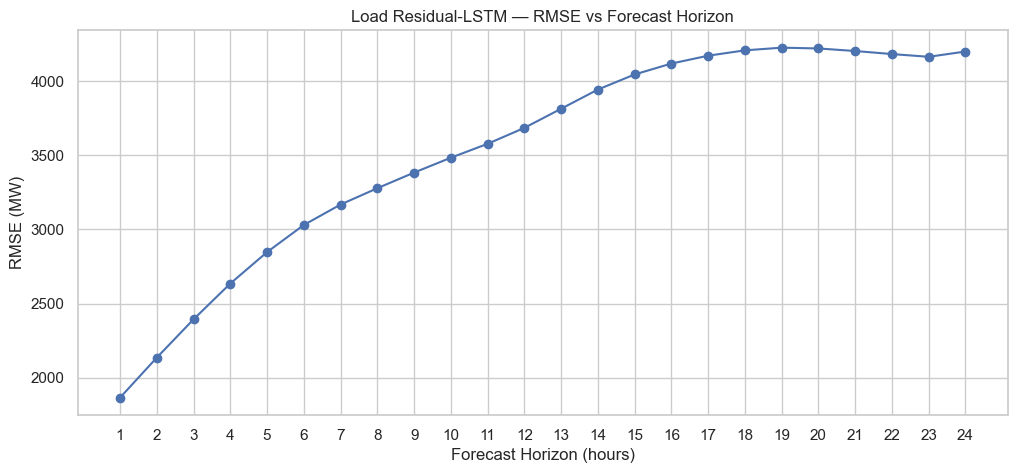

In [ ]:
# Plot RMSE across the 24-hour forecast horizon

plt.figure(figsize=(12, 5))

plt.plot(
    horizons_24h,
    residual_results_24h_df["RMSE_MW"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("RMSE (MW)")
plt.title(
    "Load Residual-LSTM — RMSE vs Forecast Horizon"
)

plt.xticks(horizons_24h)

plt.grid(True)

plt.show()

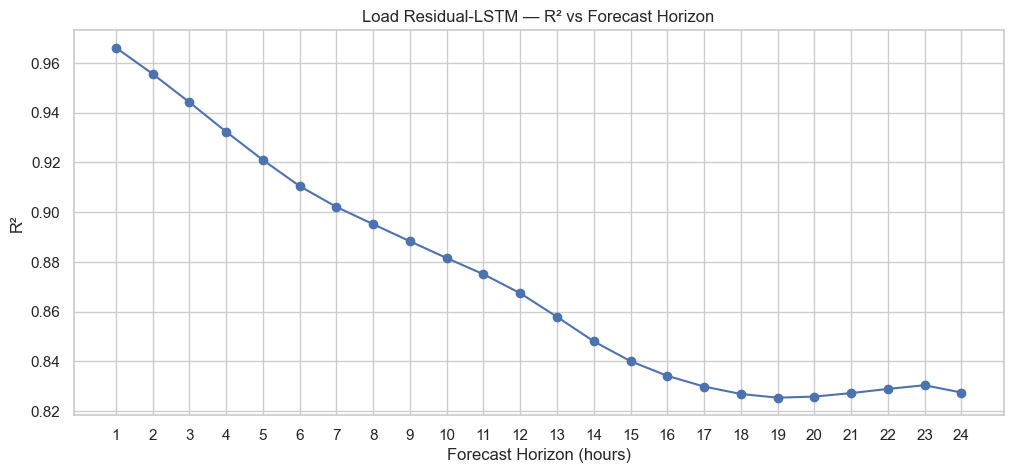

In [ ]:
# Plot R² across the 24-hour forecast horizon

plt.figure(figsize=(12, 5))

plt.plot(
    horizons_24h,
    residual_results_24h_df["R2"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("R²")
plt.title(
    "Load Residual-LSTM — R² vs Forecast Horizon"
)

plt.xticks(horizons_24h)

plt.grid(True)

plt.show()

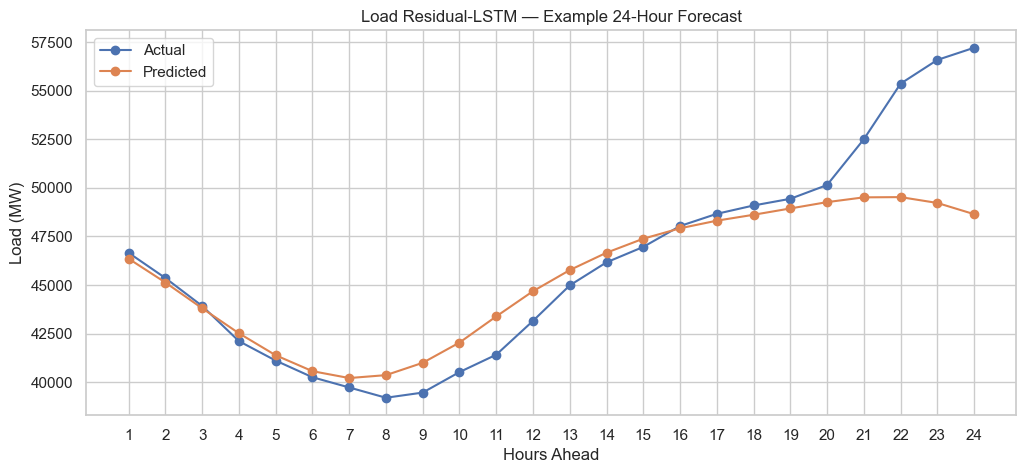

In [ ]:
# Plot one complete 24-hour forecast

sample_index = 100

actual_24h = residual_actual_24h_original[
    sample_index
]

predicted_24h = residual_predictions_24h_original[
    sample_index
]

hours_ahead_24h = np.arange(
    1,
    25
)

plt.figure(figsize=(12, 5))

plt.plot(
    hours_ahead_24h,
    actual_24h,
    marker="o",
    label="Actual"
)

plt.plot(
    hours_ahead_24h,
    predicted_24h,
    marker="o",
    label="Predicted"
)

plt.xlabel("Hours Ahead")
plt.ylabel("Load (MW)")

plt.title(
    "Load Residual-LSTM — Example 24-Hour Forecast"
)

plt.xticks(hours_ahead_24h)

plt.grid(True)
plt.legend()

plt.show()

# CNN-LSTM 24h model

In [88]:
# Import libraries and set the computation device

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
Device: cpu


In [89]:
# Load and sort the Load dataset

load_path = r"Load_Forecasting.csv"

load_df = pd.read_csv(load_path)

load_df["Datetime_UTC"] = pd.to_datetime(
    load_df["Datetime_UTC"]
)

load_df = load_df.sort_values(
    "Datetime_UTC"
).reset_index(drop=True)

print("Load shape:", load_df.shape)

print(
    "Start:",
    load_df["Datetime_UTC"].min()
)

print(
    "End:",
    load_df["Datetime_UTC"].max()
)

Load shape: (26297, 12)
Start: 2023-01-01 07:00:00+00:00
End: 2025-12-31 23:00:00+00:00


In [90]:
# Create Texas local-time calendar features

load_df["Datetime_Local"] = (
    load_df["Datetime_UTC"]
    .dt.tz_convert("America/Chicago")
)

load_df["Hour"] = (
    load_df["Datetime_Local"].dt.hour
)

load_df["DayOfWeek"] = (
    load_df["Datetime_Local"].dt.dayofweek
)

load_df["DayOfYear"] = (
    load_df["Datetime_Local"].dt.dayofyear
)

load_df["Month"] = (
    load_df["Datetime_Local"].dt.month
)

load_df["Year"] = (
    load_df["Datetime_Local"].dt.year
)

print(
    load_df[
        [
            "Datetime_UTC",
            "Datetime_Local",
            "Hour",
            "DayOfWeek",
            "DayOfYear",
            "Month",
            "Year"
        ]
    ].head()
)

               Datetime_UTC            Datetime_Local  Hour  DayOfWeek  \
0 2023-01-01 07:00:00+00:00 2023-01-01 01:00:00-06:00     1          6   
1 2023-01-01 08:00:00+00:00 2023-01-01 02:00:00-06:00     2          6   
2 2023-01-01 09:00:00+00:00 2023-01-01 03:00:00-06:00     3          6   
3 2023-01-01 10:00:00+00:00 2023-01-01 04:00:00-06:00     4          6   
4 2023-01-01 11:00:00+00:00 2023-01-01 05:00:00-06:00     5          6   

   DayOfYear  Month  Year  
0          1      1  2023  
1          1      1  2023  
2          1      1  2023  
3          1      1  2023  
4          1      1  2023  


In [91]:
# Create Texas local-time calendar features

load_df["Datetime_Local"] = (
    load_df["Datetime_UTC"]
    .dt.tz_convert("America/Chicago")
)

load_df["Hour"] = (
    load_df["Datetime_Local"].dt.hour
)

load_df["DayOfWeek"] = (
    load_df["Datetime_Local"].dt.dayofweek
)

load_df["DayOfYear"] = (
    load_df["Datetime_Local"].dt.dayofyear
)

load_df["Month"] = (
    load_df["Datetime_Local"].dt.month
)

load_df["Year"] = (
    load_df["Datetime_Local"].dt.year
)

print(
    load_df[
        [
            "Datetime_UTC",
            "Datetime_Local",
            "Hour",
            "DayOfWeek",
            "DayOfYear",
            "Month",
            "Year"
        ]
    ].head()
)

               Datetime_UTC            Datetime_Local  Hour  DayOfWeek  \
0 2023-01-01 07:00:00+00:00 2023-01-01 01:00:00-06:00     1          6   
1 2023-01-01 08:00:00+00:00 2023-01-01 02:00:00-06:00     2          6   
2 2023-01-01 09:00:00+00:00 2023-01-01 03:00:00-06:00     3          6   
3 2023-01-01 10:00:00+00:00 2023-01-01 04:00:00-06:00     4          6   
4 2023-01-01 11:00:00+00:00 2023-01-01 05:00:00-06:00     5          6   

   DayOfYear  Month  Year  
0          1      1  2023  
1          1      1  2023  
2          1      1  2023  
3          1      1  2023  
4          1      1  2023  


In [92]:
# Create cyclic time features

load_df["Hour_sin"] = np.sin(
    2 * np.pi * load_df["Hour"] / 24
)

load_df["Hour_cos"] = np.cos(
    2 * np.pi * load_df["Hour"] / 24
)

load_df["DayOfWeek_sin"] = np.sin(
    2 * np.pi * load_df["DayOfWeek"] / 7
)

load_df["DayOfWeek_cos"] = np.cos(
    2 * np.pi * load_df["DayOfWeek"] / 7
)

load_df["DayOfYear_sin"] = np.sin(
    2 * np.pi * load_df["DayOfYear"] / 365.25
)

load_df["DayOfYear_cos"] = np.cos(
    2 * np.pi * load_df["DayOfYear"] / 365.25
)

In [93]:
# Define the final Load forecasting features

load_features = [
    "Load_MW",
    "RH2M",
    "IsWeekend",
    "IsHoliday",
    "T2M",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",
    "CLOUD_AMT",
    "WS10M"
]

load_target = "Load_MW"

print("Number of features:", len(load_features))
print(load_features)

Number of features: 13
['Load_MW', 'RH2M', 'IsWeekend', 'IsHoliday', 'T2M', 'Hour_sin', 'Hour_cos', 'DayOfWeek_sin', 'DayOfWeek_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'CLOUD_AMT', 'WS10M']


In [94]:
# Verify that all selected features are available

missing_features = [
    feature
    for feature in load_features
    if feature not in load_df.columns
]

if missing_features:
    print("Missing features:")
    print(missing_features)
else:
    print("All Load features are available.")

All Load features are available.


In [95]:
# Split the Load data into training and testing periods

train_end = pd.Timestamp(
    "2024-12-31 23:00:00+00:00"
)

test_start = pd.Timestamp(
    "2025-01-01 00:00:00+00:00"
)

load_train = load_df[
    load_df["Datetime_UTC"] <= train_end
].copy()

load_test = load_df[
    load_df["Datetime_UTC"] >= test_start
].copy()

print("Training shape:", load_train.shape)
print("Testing shape :", load_test.shape)

print("\nTraining:")
print(
    load_train["Datetime_UTC"].min(),
    "to",
    load_train["Datetime_UTC"].max()
)

print("\nTesting:")
print(
    load_test["Datetime_UTC"].min(),
    "to",
    load_test["Datetime_UTC"].max()
)

Training shape: (17537, 20)
Testing shape : (8760, 20)

Training:
2023-01-01 07:00:00+00:00 to 2024-12-31 23:00:00+00:00

Testing:
2025-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00


In [96]:
# Prepare Load features and target arrays

X_train_raw = load_train[
    load_features
].values

y_train_raw = load_train[
    [load_target]
].values

X_test_raw = load_test[
    load_features
].values

y_test_raw = load_test[
    [load_target]
].values

print("X_train:", X_train_raw.shape)
print("y_train:", y_train_raw.shape)

print("X_test :", X_test_raw.shape)
print("y_test :", y_test_raw.shape)

X_train: (17537, 13)
y_train: (17537, 1)
X_test : (8760, 13)
y_test : (8760, 1)


In [97]:
# Scale features and target using training data only

X_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(
    X_train_raw
)

y_train_scaled = y_scaler.fit_transform(
    y_train_raw
)

X_test_scaled = X_scaler.transform(
    X_test_raw
)

y_test_scaled = y_scaler.transform(
    y_test_raw
)

print("Scaling completed.")

Scaling completed.


In [98]:
# Set the 24-hour forecasting configuration

LOOKBACK = 168
FORECAST_HORIZON = 24

print("Lookback:", LOOKBACK)
print("Forecast horizon:", FORECAST_HORIZON)

Lookback: 168
Forecast horizon: 24


In [99]:
# Create multi-output forecasting sequences

def create_multi_output_sequences(
    X,
    y,
    lookback,
    horizon
):

    X_sequences = []
    y_sequences = []

    for i in range(
        len(X) - lookback - horizon + 1
    ):

        X_seq = X[
            i : i + lookback
        ]

        y_seq = y[
            i + lookback :
            i + lookback + horizon
        ]

        X_sequences.append(X_seq)

        y_sequences.append(
            y_seq.flatten()
        )

    return (
        np.array(X_sequences),
        np.array(y_sequences)
    )

In [100]:
# Create 24-hour training sequences

X_train_seq, y_train_seq = (
    create_multi_output_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK,
        FORECAST_HORIZON
    )
)

print(
    "X_train_seq shape:",
    X_train_seq.shape
)

print(
    "y_train_seq shape:",
    y_train_seq.shape
)

X_train_seq shape: (17346, 168, 13)
y_train_seq shape: (17346, 24)


In [101]:
# Add the final 168 training hours as test context

X_test_context = np.vstack([
    X_train_scaled[-LOOKBACK:],
    X_test_scaled
])

y_test_context = np.vstack([
    y_train_scaled[-LOOKBACK:],
    y_test_scaled
])

print(
    "X_test_context:",
    X_test_context.shape
)

print(
    "y_test_context:",
    y_test_context.shape
)

X_test_context: (8928, 13)
y_test_context: (8928, 1)


In [102]:
# Create 24-hour testing sequences

X_test_seq = []
y_test_seq = []

for i in range(
    len(X_test_scaled) - FORECAST_HORIZON + 1
):

    X_seq = X_test_context[
        i : i + LOOKBACK
    ]

    target_start = LOOKBACK + i

    y_seq = y_test_context[
        target_start :
        target_start + FORECAST_HORIZON
    ]

    X_test_seq.append(X_seq)

    y_test_seq.append(
        y_seq.flatten()
    )

X_test_seq = np.array(
    X_test_seq
)

y_test_seq = np.array(
    y_test_seq
)

print(
    "X_test_seq shape:",
    X_test_seq.shape
)

print(
    "y_test_seq shape:",
    y_test_seq.shape
)

X_test_seq shape: (8737, 168, 13)
y_test_seq shape: (8737, 24)


In [103]:
# Verify the 24-hour sequence dimensions

print("Training X:", X_train_seq.shape)
print("Training y:", y_train_seq.shape)

print("Testing X :", X_test_seq.shape)
print("Testing y :", y_test_seq.shape)

assert X_train_seq.shape[1] == 168
assert X_train_seq.shape[2] == 13

assert y_train_seq.shape[1] == 24
assert y_test_seq.shape[1] == 24

print("All shape checks passed.")

Training X: (17346, 168, 13)
Training y: (17346, 24)
Testing X : (8737, 168, 13)
Testing y : (8737, 24)
All shape checks passed.


In [104]:
# Convert sequences to PyTorch tensors

X_train_tensor = torch.tensor(
    X_train_seq,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_seq,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_seq,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_seq,
    dtype=torch.float32
)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test :", X_test_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train: torch.Size([17346, 168, 13])
y_train: torch.Size([17346, 24])
X_test : torch.Size([8737, 168, 13])
y_test : torch.Size([8737, 24])


In [105]:
# Create the PyTorch forecasting dataset

class ForecastDataset(Dataset):

    def __init__(self, X, y):

        self.X = X
        self.y = y

    def __len__(self):

        return len(self.X)

    def __getitem__(self, index):

        return (
            self.X[index],
            self.y[index]
        )

In [106]:
# Create the 24-hour DataLoaders

BATCH_SIZE = 64

train_dataset = ForecastDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = ForecastDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Testing batches:",
    len(test_loader)
)

Training batches: 272
Testing batches: 137


In [107]:
# Verify the 24-hour batch dimensions

X_batch, y_batch = next(
    iter(train_loader)
)

print("Input shape :", X_batch.shape)
print("Target shape:", y_batch.shape)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64, 24])


In [108]:
# Define the 24-hour CNN-LSTM model

class CNNLSTMForecaster24H(nn.Module):

    def __init__(
        self,
        input_size,
        cnn_channels=32,
        kernel_size=3,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        output_size=24
    ):
        super().__init__()

        self.cnn = nn.Conv1d(
            in_channels=input_size,
            out_channels=cnn_channels,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.relu = nn.ReLU()

        self.lstm = nn.LSTM(
            input_size=cnn_channels,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        x = x.transpose(1, 2)

        x = self.cnn(x)

        x = self.relu(x)

        x = x.transpose(1, 2)

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        last_output = self.dropout(
            last_output
        )

        prediction = self.fc(
            last_output
        )

        return prediction

In [109]:
# Create the 24-hour CNN-LSTM

cnn_load_model_24h = CNNLSTMForecaster24H(
    input_size=len(load_features),
    cnn_channels=32,
    kernel_size=3,
    hidden_size=64,
    num_layers=2,
    dropout=0.2,
    output_size=24
)

cnn_load_model_24h = (
    cnn_load_model_24h.to(device)
)

print(cnn_load_model_24h)

CNNLSTMForecaster24H(
  (cnn): Conv1d(13, 32, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (lstm): LSTM(32, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=24, bias=True)
)


In [110]:
# Count trainable parameters

cnn_parameters_24h = sum(
    p.numel()
    for p in cnn_load_model_24h.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    cnn_parameters_24h
)

Trainable parameters: 61208


In [111]:
# Test the 24-hour CNN-LSTM forward pass

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():

    cnn_output_24h = (
        cnn_load_model_24h(
            X_batch
        )
    )

print(
    "Input shape :",
    X_batch.shape
)

print(
    "Target shape:",
    y_batch.shape
)

print(
    "Output shape:",
    cnn_output_24h.shape
)

Input shape : torch.Size([64, 168, 13])
Target shape: torch.Size([64, 24])
Output shape: torch.Size([64, 24])


In [112]:
# Define the CNN-LSTM loss and optimizer

cnn_load_criterion_24h = nn.MSELoss()

cnn_load_optimizer_24h = torch.optim.Adam(
    cnn_load_model_24h.parameters(),
    lr=0.001
)

print("Loss function : MSELoss")
print("Optimizer     : Adam")
print("Learning rate : 0.001")

Loss function : MSELoss
Optimizer     : Adam
Learning rate : 0.001


In [113]:
# Define the 24-hour CNN-LSTM training function

def train_cnn_lstm_24h(
    model,
    train_loader,
    criterion,
    optimizer,
    epochs,
    device
):

    history = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(
                X_batch
            )

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

        epoch_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        history.append(epoch_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.6f}"
        )

    return history

In [114]:
# Train the 24-hour CNN-LSTM

CNN_LSTM_24H_EPOCHS = 20

cnn_load_history_24h = train_cnn_lstm_24h(
    model=cnn_load_model_24h,
    train_loader=train_loader,
    criterion=cnn_load_criterion_24h,
    optimizer=cnn_load_optimizer_24h,
    epochs=CNN_LSTM_24H_EPOCHS,
    device=device
)

Epoch [1/20] Loss: 0.247481
Epoch [2/20] Loss: 0.078756
Epoch [3/20] Loss: 0.070946
Epoch [4/20] Loss: 0.063954
Epoch [5/20] Loss: 0.059329
Epoch [6/20] Loss: 0.057058
Epoch [7/20] Loss: 0.053626
Epoch [8/20] Loss: 0.049647
Epoch [9/20] Loss: 0.045422
Epoch [10/20] Loss: 0.042486
Epoch [11/20] Loss: 0.040308
Epoch [12/20] Loss: 0.037528
Epoch [13/20] Loss: 0.035872
Epoch [14/20] Loss: 0.033565
Epoch [15/20] Loss: 0.032543
Epoch [16/20] Loss: 0.031057
Epoch [17/20] Loss: 0.030550
Epoch [18/20] Loss: 0.028809
Epoch [19/20] Loss: 0.028346
Epoch [20/20] Loss: 0.028216


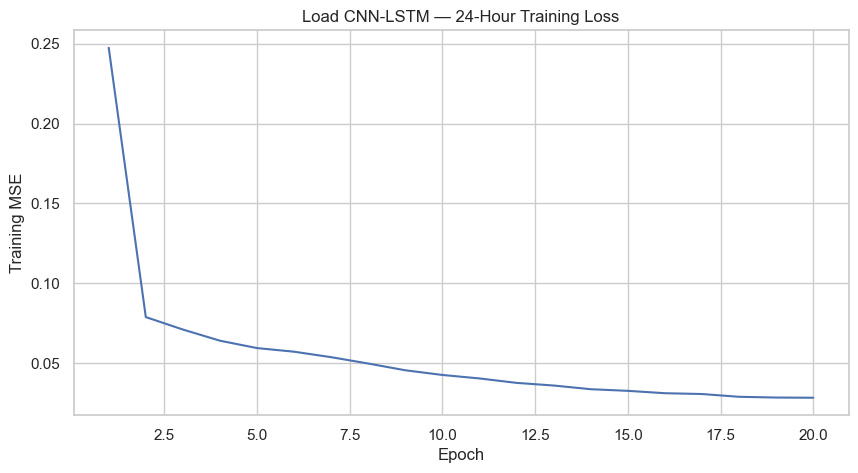

In [115]:
# Plot the 24-hour CNN-LSTM training loss

plt.figure(figsize=(10, 5))

plt.plot(
    range(
        1,
        CNN_LSTM_24H_EPOCHS + 1
    ),
    cnn_load_history_24h
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.title(
    "Load CNN-LSTM — 24-Hour Training Loss"
)

plt.grid(True)

plt.show()

In [116]:
# Generate 24-hour CNN-LSTM predictions

cnn_load_model_24h.eval()

cnn_predictions_24h_scaled = []
cnn_actual_24h_scaled = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = (
            cnn_load_model_24h(
                X_batch
            )
        )

        cnn_predictions_24h_scaled.append(
            predictions.cpu().numpy()
        )

        cnn_actual_24h_scaled.append(
            y_batch.numpy()
        )

cnn_predictions_24h_scaled = np.vstack(
    cnn_predictions_24h_scaled
)

cnn_actual_24h_scaled = np.vstack(
    cnn_actual_24h_scaled
)

print(
    "Prediction shape:",
    cnn_predictions_24h_scaled.shape
)

print(
    "Actual shape    :",
    cnn_actual_24h_scaled.shape
)

Prediction shape: (8737, 24)
Actual shape    : (8737, 24)


In [117]:
# Convert 24-hour predictions back to MW

cnn_predictions_24h = (
    y_scaler.inverse_transform(
        cnn_predictions_24h_scaled.reshape(-1, 1)
    )
    .reshape(
        cnn_predictions_24h_scaled.shape
    )
)

cnn_actual_24h = (
    y_scaler.inverse_transform(
        cnn_actual_24h_scaled.reshape(-1, 1)
    )
    .reshape(
        cnn_actual_24h_scaled.shape
    )
)

print(
    "Prediction range:",
    cnn_predictions_24h.min(),
    "to",
    cnn_predictions_24h.max(),
    "MW"
)

print(
    "Actual range:",
    cnn_actual_24h.min(),
    "to",
    cnn_actual_24h.max(),
    "MW"
)

Prediction range: 36520.223 to 85650.56 MW
Actual range: 38617.902 to 83876.46 MW


In [118]:
# Calculate metrics for each forecast horizon

cnn_results_24h = []

for h in range(
    FORECAST_HORIZON
):

    actual_h = cnn_actual_24h[:, h]

    pred_h = cnn_predictions_24h[:, h]

    mae = mean_absolute_error(
        actual_h,
        pred_h
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_h,
            pred_h
        )
    )

    r2 = r2_score(
        actual_h,
        pred_h
    )

    cnn_results_24h.append({
        "Horizon": f"t+{h+1}",
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "R2": r2
    })

cnn_results_24h_df = pd.DataFrame(
    cnn_results_24h
)

cnn_results_24h_df

,Horizon,MAE_MW,RMSE_MW,R2
0,t+1,1682.273315,2180.137037,0.953679
1,t+2,1789.616333,2348.048977,0.946265
2,t+3,1904.077515,2528.348769,0.937691
3,t+4,2022.160278,2712.535530,0.928276
4,t+5,2137.010010,2892.632365,0.918427
5,t+6,2238.128906,3053.478017,0.909094
6,t+7,2316.556641,3188.242306,0.900880
7,t+8,2379.792236,3299.996818,0.893795
8,t+9,2442.386230,3401.925778,0.887116
9,t+10,2505.460938,3496.301188,0.880748


In [119]:
# Calculate overall 24-hour CNN-LSTM performance

cnn_overall_actual_24h = (
    cnn_actual_24h.flatten()
)

cnn_overall_pred_24h = (
    cnn_predictions_24h.flatten()
)

cnn_overall_mae_24h = mean_absolute_error(
    cnn_overall_actual_24h,
    cnn_overall_pred_24h
)

cnn_overall_rmse_24h = np.sqrt(
    mean_squared_error(
        cnn_overall_actual_24h,
        cnn_overall_pred_24h
    )
)

cnn_overall_r2_24h = r2_score(
    cnn_overall_actual_24h,
    cnn_overall_pred_24h
)

print("=" * 60)
print("LOAD CNN-LSTM — 24-HOUR RESULTS")
print("=" * 60)

print(
    f"Overall MAE  : {cnn_overall_mae_24h:.4f} MW"
)

print(
    f"Overall RMSE : {cnn_overall_rmse_24h:.4f} MW"
)

print(
    f"Overall R²   : {cnn_overall_r2_24h:.4f}"
)

LOAD CNN-LSTM — 24-HOUR RESULTS
Overall MAE  : 2581.0073 MW
Overall RMSE : 3621.5005 MW
Overall R²   : 0.8720


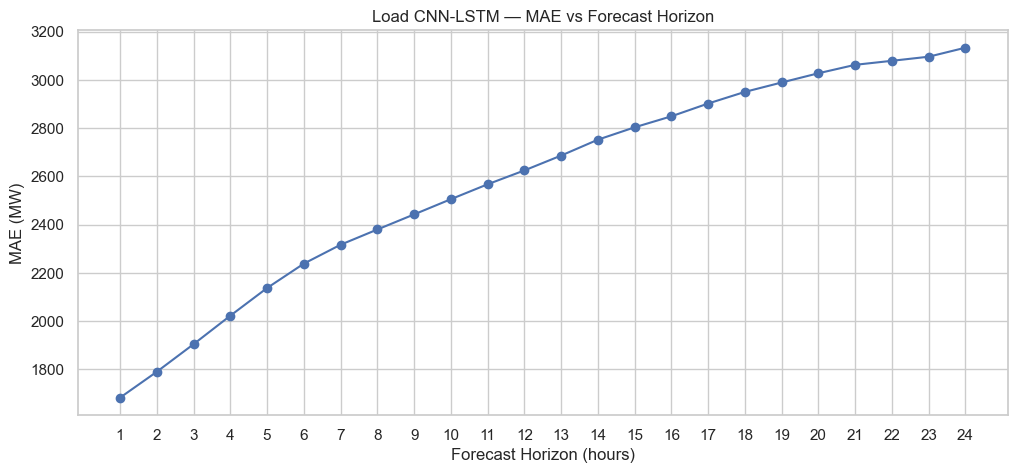

In [120]:
# Plot MAE across the 24-hour forecast horizon

horizons = np.arange(
    1,
    FORECAST_HORIZON + 1
)

plt.figure(figsize=(12, 5))

plt.plot(
    horizons,
    cnn_results_24h_df["MAE_MW"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("MAE (MW)")

plt.title(
    "Load CNN-LSTM — MAE vs Forecast Horizon"
)

plt.xticks(horizons)

plt.grid(True)

plt.show()

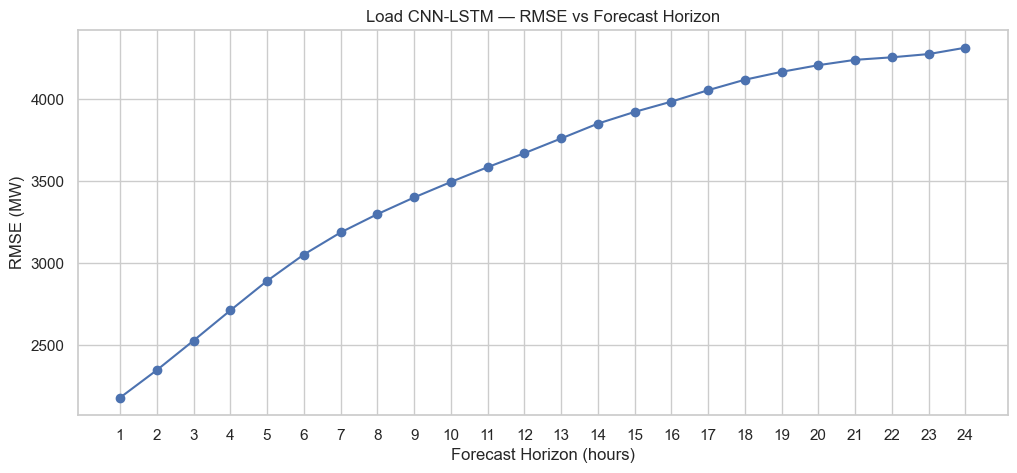

In [121]:
# Plot RMSE across the 24-hour forecast horizon

plt.figure(figsize=(12, 5))

plt.plot(
    horizons,
    cnn_results_24h_df["RMSE_MW"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("RMSE (MW)")

plt.title(
    "Load CNN-LSTM — RMSE vs Forecast Horizon"
)

plt.xticks(horizons)

plt.grid(True)

plt.show()

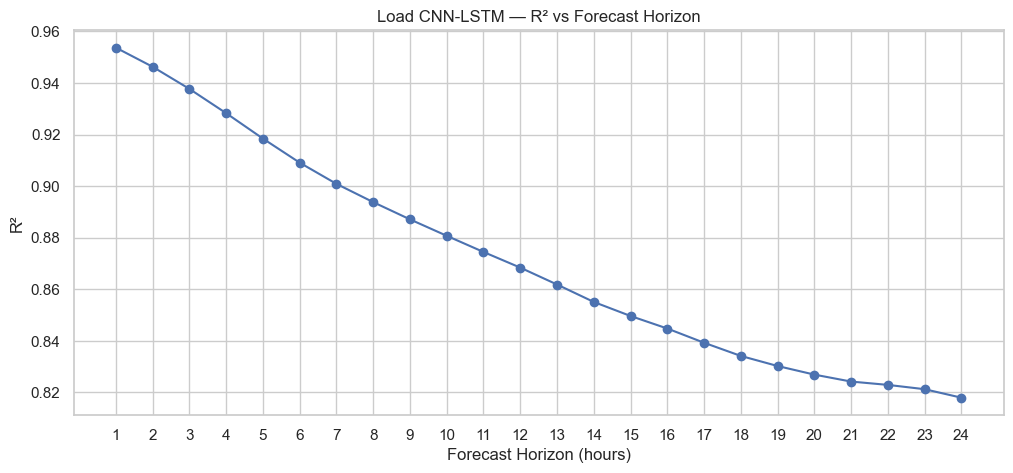

In [122]:
# Plot R² across the 24-hour forecast horizon

plt.figure(figsize=(12, 5))

plt.plot(
    horizons,
    cnn_results_24h_df["R2"],
    marker="o"
)

plt.xlabel("Forecast Horizon (hours)")
plt.ylabel("R²")

plt.title(
    "Load CNN-LSTM — R² vs Forecast Horizon"
)

plt.xticks(horizons)

plt.grid(True)

plt.show()

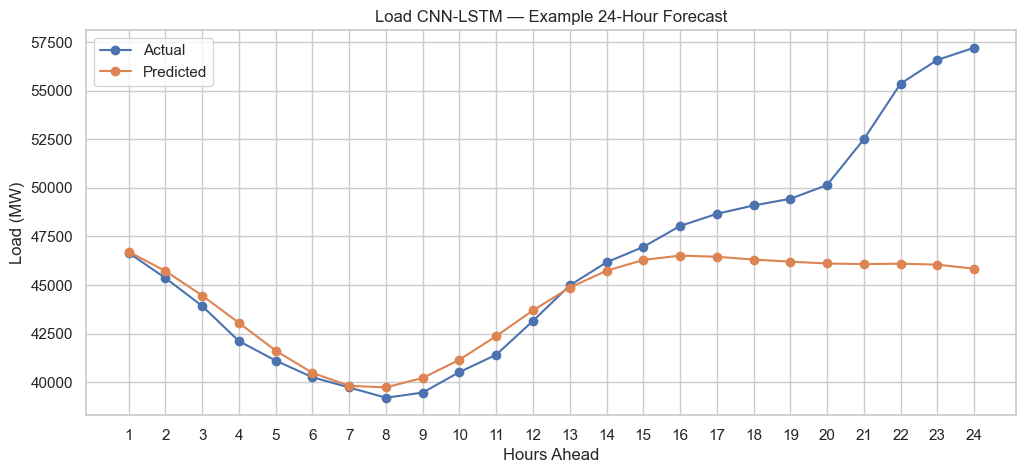

In [123]:
# Plot one complete 24-hour CNN-LSTM forecast

sample_index = 100

actual_24h = cnn_actual_24h[
    sample_index
]

predicted_24h = cnn_predictions_24h[
    sample_index
]

plt.figure(figsize=(12, 5))

plt.plot(
    horizons,
    actual_24h,
    marker="o",
    label="Actual"
)

plt.plot(
    horizons,
    predicted_24h,
    marker="o",
    label="Predicted"
)

plt.xlabel("Hours Ahead")
plt.ylabel("Load (MW)")

plt.title(
    "Load CNN-LSTM — Example 24-Hour Forecast"
)

plt.xticks(horizons)

plt.grid(True)
plt.legend()

plt.show()

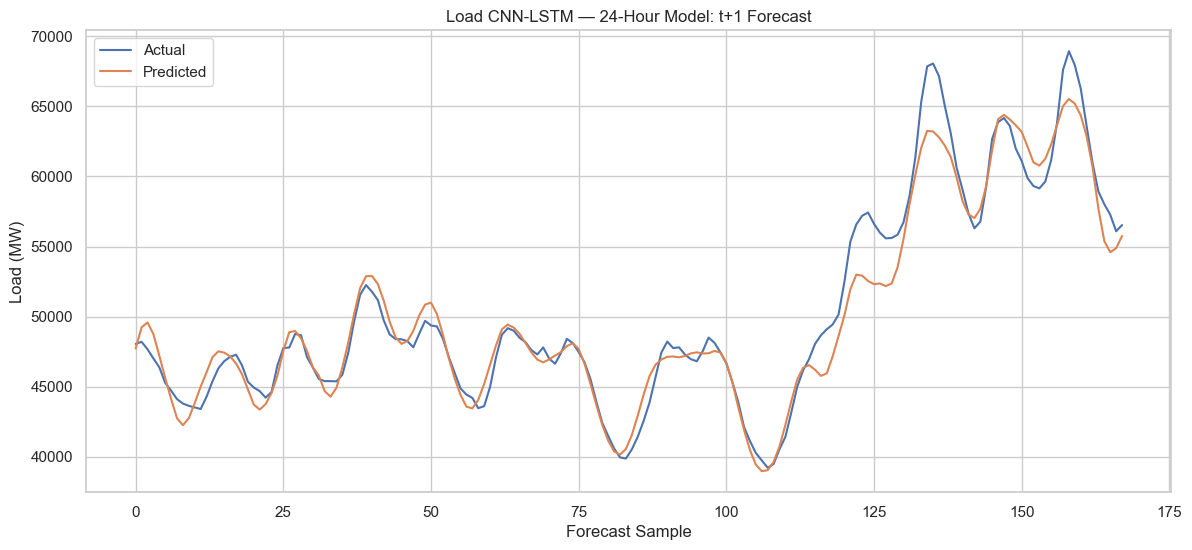

In [124]:
# Plot t+1 predictions for the first seven test days

hours = 168

plt.figure(figsize=(14, 6))

plt.plot(
    cnn_actual_24h[:hours, 0],
    label="Actual"
)

plt.plot(
    cnn_predictions_24h[:hours, 0],
    label="Predicted"
)

plt.xlabel("Forecast Sample")
plt.ylabel("Load (MW)")

plt.title(
    "Load CNN-LSTM — 24-Hour Model: t+1 Forecast"
)

plt.legend()
plt.grid(True)

plt.show()

# LSTM-Residual 24hr

In [125]:
# Define the 24-hour residual LSTM

class ResidualLSTM24(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        forecast_horizon=24,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            forecast_horizon
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        last_output = self.dropout(last_output)

        correction = self.fc(last_output)

        return correction

In [128]:
# Create the 24-hour residual LSTM

FORECAST_HORIZON = 24

load_input_size = len(load_features)

load_residual_model = ResidualLSTM24(
    input_size=load_input_size,
    hidden_size=64,
    num_layers=2,
    forecast_horizon=FORECAST_HORIZON,
    dropout=0.2
).to(device)

print(load_residual_model)

ResidualLSTM24(
  (lstm): LSTM(13, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=24, bias=True)
)


In [129]:
# Compare all completed Load forecasting models by forecasting time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

comparison_summary = pd.DataFrame([
    ["1 Hour", "Baseline LSTM", 619.3125, 814.2667, 0.9935],
    ["1 Hour", "CNN-LSTM", 753.270752, 992.068515, 0.990388],
    ["1 Hour", "Attention-LSTM", 4231.459473, 5709.751658, 0.681609],
    ["1 Hour", "Residual-LSTM", 536.834961, 729.768799, 0.994799],
    ["1 Hour", "CNN-Residual-LSTM", 619.465210, 818.668546, 0.993455],

    ["6 Hour", "Baseline LSTM", 1341.7338, 1780.7989, 0.9690],
    ["6 Hour", "Residual-LSTM", 1242.5165, 1682.3575, 0.9724],

    ["24 Hour", "Residual-LSTM", 2584.2122, 3613.1500, 0.8726],
    ["24 Hour", "CNN-LSTM", 2581.0073, 3621.5005, 0.8720]
], columns=[
    "Forecasting_Time",
    "Model",
    "MAE_MW",
    "RMSE_MW",
    "R2"
])

comparison_summary

,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,1 Hour,Baseline LSTM,619.312500,814.266700,0.993500
1,1 Hour,CNN-LSTM,753.270752,992.068515,0.990388
2,1 Hour,Attention-LSTM,4231.459473,5709.751658,0.681609
3,1 Hour,Residual-LSTM,536.834961,729.768799,0.994799
4,1 Hour,CNN-Residual-LSTM,619.465210,818.668546,0.993455
5,6 Hour,Baseline LSTM,1341.733800,1780.798900,0.969000
6,6 Hour,Residual-LSTM,1242.516500,1682.357500,0.972400
7,24 Hour,Residual-LSTM,2584.212200,3613.150000,0.872600
8,24 Hour,CNN-LSTM,2581.007300,3621.500500,0.872000


In [130]:
# Display the models separately for each forecasting time

for forecast_time in ["1 Hour", "6 Hour", "24 Hour"]:

    print("=" * 70)
    print(f"{forecast_time} FORECASTING")
    print("=" * 70)

    display(
        comparison_summary[
            comparison_summary["Forecasting_Time"] == forecast_time
        ].reset_index(drop=True)
    )

1 Hour FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,1 Hour,Baseline LSTM,619.312500,814.266700,0.993500
1,1 Hour,CNN-LSTM,753.270752,992.068515,0.990388
2,1 Hour,Attention-LSTM,4231.459473,5709.751658,0.681609
3,1 Hour,Residual-LSTM,536.834961,729.768799,0.994799
4,1 Hour,CNN-Residual-LSTM,619.465210,818.668546,0.993455


6 Hour FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,6 Hour,Baseline LSTM,1341.7338,1780.7989,0.9690
1,6 Hour,Residual-LSTM,1242.5165,1682.3575,0.9724


24 Hour FORECASTING


,Forecasting_Time,Model,MAE_MW,RMSE_MW,R2
0,24 Hour,Residual-LSTM,2584.2122,3613.1500,0.8726
1,24 Hour,CNN-LSTM,2581.0073,3621.5005,0.8720


In [131]:
# Find the best model at each forecasting time

best_models = []

for forecast_time in ["1 Hour", "6 Hour", "24 Hour"]:

    data = comparison_summary[
        comparison_summary["Forecasting_Time"] == forecast_time
    ]

    best_mae = data.loc[data["MAE_MW"].idxmin()]
    best_rmse = data.loc[data["RMSE_MW"].idxmin()]
    best_r2 = data.loc[data["R2"].idxmax()]

    best_models.append({
        "Forecasting_Time": forecast_time,
        "Best_MAE_Model": best_mae["Model"],
        "Best_MAE_MW": best_mae["MAE_MW"],
        "Best_RMSE_Model": best_rmse["Model"],
        "Best_RMSE_MW": best_rmse["RMSE_MW"],
        "Best_R2_Model": best_r2["Model"],
        "Best_R2": best_r2["R2"]
    })

best_models_df = pd.DataFrame(best_models)

best_models_df

,Forecasting_Time,Best_MAE_Model,Best_MAE_MW,Best_RMSE_Model,Best_RMSE_MW,Best_R2_Model,Best_R2
0,1 Hour,Residual-LSTM,536.834961,Residual-LSTM,729.768799,Residual-LSTM,0.994799
1,6 Hour,Residual-LSTM,1242.516500,Residual-LSTM,1682.357500,Residual-LSTM,0.972400
2,24 Hour,CNN-LSTM,2581.007300,Residual-LSTM,3613.150000,Residual-LSTM,0.872600
